# Oracle-Referenced, Audited Benchmark for Stealthy False-Data Injection in Power-System State Estimation and Load-Frequency Control

**A pilot implementation of the research proposal "Hardness-Calibrated Detection of Stealthy FDI in LFC" (version 2).**

This notebook is the single source of truth for the pilot study. It runs top to bottom, generates every dataset it uses, draws every figure it shows, and ends by evaluating the pre-registered hypotheses and writing `outputs/results.json`.

> **Honesty statement.** This is a *simulation pilot*. It does not use real utility data, and every number printed here comes from the synthetic generator defined in Part 4. Nothing in this notebook is evidence of real-world performance, and none of it guarantees publication in any venue. Hypotheses are evaluated against thresholds that were written down *before* the experiments ran (Part 1.3), and failures are reported as failures.

## What the study asks

Published false-data-injection (FDI) detection papers report F1 scores near 99% on a handful of IEEE test grids with in-distribution splits. Those numbers say little about three questions this notebook measures directly:

1. **How far is each detector from the best possible detector?** For a stealth attack that shifts the state estimate by a vector $c$, the best detector's performance is a closed-form function of one number, the *hardness* $\delta(c)=\sqrt{c^\top\Sigma^{-1}c}$. We report every detector's gap to that oracle, as a function of $\delta$.
2. **Is the benchmark itself solvable by shortcuts?** We apply a four-test audit to our own generator and to the existing SCEPTRE dataset.
3. **Do the results survive on grids the detector has never seen?** We train on some randomized grids and test on others, and compare training on one IEEE case against training on a randomized family.

On top of that we test three methods (hardness-stratified training, oracle distillation, conformal risk control on damage) and translate detection into grid damage with a two-area load-frequency-control (LFC) loop.

## Roadmap

| Part | Content |
|---|---|
| 1 | Environment, reproducibility contract, frozen hypotheses |
| 2 | Theory: hardness, oracle ROC, clean-only reference, damage ceiling |
| 3 | Grid library: IEEE cases, randomized variants, synthetic grids |
| 4 | Physics core: Newton power flow, measurement model, WLS estimator |
| 5 | Operating conditions, measurement noise, hard negatives |
| 6 | Attack library |
| 7 | Dataset assembly |
| 8 | Shortcut audit (ours and SCEPTRE) |
| 9 | Detectors |
| 10 | In-grid oracle-gap study |
| 11 | Leave-grid-out generalization |
| 12 | LFC plant and damage at budget |
| 13 | Methods: hardness-stratified training, oracle distillation, conformal risk control |
| 14 | Adaptive attacker |
| 15 | Hypothesis scorecard and export |

## Part 1. Environment and reproducibility

### 1.1 Environment

This notebook reuses the SCEPTRE environment contract: Python 3.10, `numpy`, `scipy`, `pandas`, `pandapower`, `networkx`, `scikit-learn`, `matplotlib`. PyTorch is **optional**. Every result below is produced with the CPU-only scientific stack, so the notebook runs without a GPU. If PyTorch with a CUDA 12.8 build is present (as on the RTX 5060 machine SCEPTRE targeted), cell 1.2 reports it, and the optional deep-set detector in Part 9 is enabled.

Install steps are in `README.md` and `setup_env.ps1` in the project root.

In [1]:
import os, sys, time, json, math, warnings, platform, itertools, pickle, textwrap
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import scipy
import scipy.linalg as sla
import scipy.stats as st
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, Rectangle

import sklearn
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

import pandapower as pp
import pandapower.networks as pn
from pandapower.pypower.makeYbus import makeYbus as _pp_makeYbus

warnings.filterwarnings("ignore")
t_notebook_start = time.time()

# Optional deep-learning stack (never required).
try:
    import torch
    HAS_TORCH = True
except Exception:
    torch = None
    HAS_TORCH = False

print("python      ", platform.python_version(), "|", platform.system())
for name, mod in [("numpy", np), ("scipy", scipy), ("pandas", pd), ("networkx", nx),
                  ("sklearn", sklearn), ("matplotlib", matplotlib), ("pandapower", pp)]:
    print(f"{name:<12}", getattr(mod, "__version__", "?"))
if HAS_TORCH:
    print("torch       ", torch.__version__, "| cuda:", torch.cuda.is_available(),
          "| arch:", torch.cuda.get_arch_list() if torch.cuda.is_available() else "-")
else:
    print("torch        not installed (optional; CPU-only path is used)")

python       3.13.16 | Linux
numpy        2.4.6
scipy        1.18.1
pandas       2.3.3
networkx     3.6.1
sklearn      1.9.1
matplotlib   3.11.2
pandapower   3.5.6
torch        not installed (optional; CPU-only path is used)


### 1.2 Reproducibility contract and project paths

* One global seed. Every random stream is derived from it with a named `SeedSequence` spawn, so adding an experiment never changes another experiment's data.
* `BUDGET` controls sample counts: `full` is what the reported numbers use; `quick` is for smoke tests. Set it with the environment variable `FDI_BUDGET`.
* All outputs go to `figures/`, `outputs/` and `data/` next to the notebook's project root.

In [2]:
GLOBAL_SEED = 2026
BUDGET = os.environ.get("FDI_BUDGET", "full")
assert BUDGET in ("full", "quick")

# Project root = the folder that contains `notebooks/` (falls back to cwd).
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
FIG = ROOT / "figures"; OUT = ROOT / "outputs"; DATA = ROOT / "data"
for d in (FIG, OUT, DATA):
    d.mkdir(parents=True, exist_ok=True)

def rng_for(name, *idx):
    """Named, independent random stream derived from the global seed."""
    key = [GLOBAL_SEED] + [ord(c) for c in name] + [int(i) for i in idx]
    return np.random.default_rng(np.random.SeedSequence(key))

SIZES = dict(
    full =dict(n_cal=900, n_train=1800, n_test=1800, n_budget_seeds=3, rs_trials=6),
    quick=dict(n_cal=300, n_train=500,  n_test=500,  n_budget_seeds=2, rs_trials=2),
)[BUDGET]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False,
})
PAL = dict(ink="#1f2937", blue="#2563eb", red="#dc2626", green="#16a34a", amber="#d97706",
           purple="#7c3aed", teal="#0d9488", grey="#6b7280", pink="#db2777", sky="#0ea5e9")

_fig_log = []
def savefig(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    _fig_log.append(name)
    plt.show()
    return path

print("ROOT   :", ROOT)
print("BUDGET :", BUDGET, SIZES)

ROOT   : /tmp/w2/proj
BUDGET : full {'n_cal': 900, 'n_train': 1800, 'n_test': 1800, 'n_budget_seeds': 3, 'rs_trials': 6}


### 1.3 Frozen hypotheses (the pre-registration)

These thresholds were fixed **before** any experiment in this notebook was run. They are the proposal's H1 to H14 in executable form. Part 15 evaluates them mechanically, with no hand-tuning afterwards. A hypothesis that fails stays failed in the final table.

Two hypotheses (H9 and H10 of the proposal: physics-structured head, flow detector) are *not* tested here because they need the optional deep stack; they are marked `NOT_RUN` rather than silently dropped.

In [3]:
HYPOTHESES = {
 "H1":  "Trivial detectors are within 0.01 AUROC of the best deep model on the existing SCEPTRE data (shortcut-solvable).",
 "H2":  "On the rebuilt benchmark, the best tuned learned detector is >= 0.05 AUROC below the oracle at hardness 1-4 with 1,800 training windows, and the gap shrinks with more data.",
 "H3":  "A clean-only Hotelling test matches or beats clean-only deep/ML one-class detectors (isolation forest, PCA) at equal false-alarm rate.",
 "H4":  "Ranking detectors by AUROC differs from ranking by damage-at-budget (Spearman rho < 0.8).",
 "H5":  "Against an adaptive attacker, the static supervised detector loses more power than the clean-only test.",
 "H6":  "Hardness-stratified training closes >= 20% more of the oracle gap at small hardness than uniform-magnitude training at equal data.",
 "H7":  "Oracle distillation beats a plain student in AUROC at the 1% and 5% label budgets.",
 "H8":  "Conformal risk control keeps realised evadable damage under budget in >= 95% of calibration splits for non-adaptive attacks.",
 "H9":  "Physics-structured head matches an unstructured network at large hardness (NOT RUN: needs optional deep stack).",
 "H10": "A flow detector beats Hotelling only for non-Gaussian clean residuals (NOT RUN: needs optional deep stack).",
 "H11": "After randomization and the audit gates, the trivial-detector gap exceeds 0.02 AUROC in the hard bins (delta < 2).",
 "H12": "A detector trained on <= 3 grids loses >= 0.05 AUROC at small hardness on unseen grids versus held-out windows of seen grids.",
 "H13": "Training on a broad randomized grid family beats training on one IEEE case on unseen-grid AUROC at equal sample count.",
 "H14": "Detectors trained without hard negatives raise false alarms on N-1 outages by >= 2x versus detectors trained with them.",
}
THRESH = dict(h1_gap=0.01, h2_gap=0.05, h3_tol=0.0, h4_rho=0.8, h6_closure=0.20,
              h8_cov=0.95, h11_gap=0.02, h12_drop=0.05, h14_ratio=2.0)
SMALL_DELTA = (0.5, 2.0)     # "hard" region used by H2/H6/H11/H12/H13
MID_DELTA   = (1.0, 4.0)     # region used by H2
print(json.dumps(HYPOTHESES, indent=1)[:400], "...")
print(THRESH)

{
 "H1": "Trivial detectors are within 0.01 AUROC of the best deep model on the existing SCEPTRE data (shortcut-solvable).",
 "H2": "On the rebuilt benchmark, the best tuned learned detector is >= 0.05 AUROC below the oracle at hardness 1-4 with 1,800 training windows, and the gap shrinks with more data.",
 "H3": "A clean-only Hotelling test matches or beats clean-only deep/ML one-class detectors  ...
{'h1_gap': 0.01, 'h2_gap': 0.05, 'h3_tol': 0.0, 'h4_rho': 0.8, 'h6_closure': 0.2, 'h8_cov': 0.95, 'h11_gap': 0.02, 'h12_drop': 0.05, 'h14_ratio': 2.0}


### 1.4 Study architecture (Figure 1)

The diagram shows the whole pipeline once, so every later cell can be placed in it. Blue boxes are things we generate, green boxes are things we measure, amber boxes are the methods layer, and the red box is the translation from detection to grid damage.

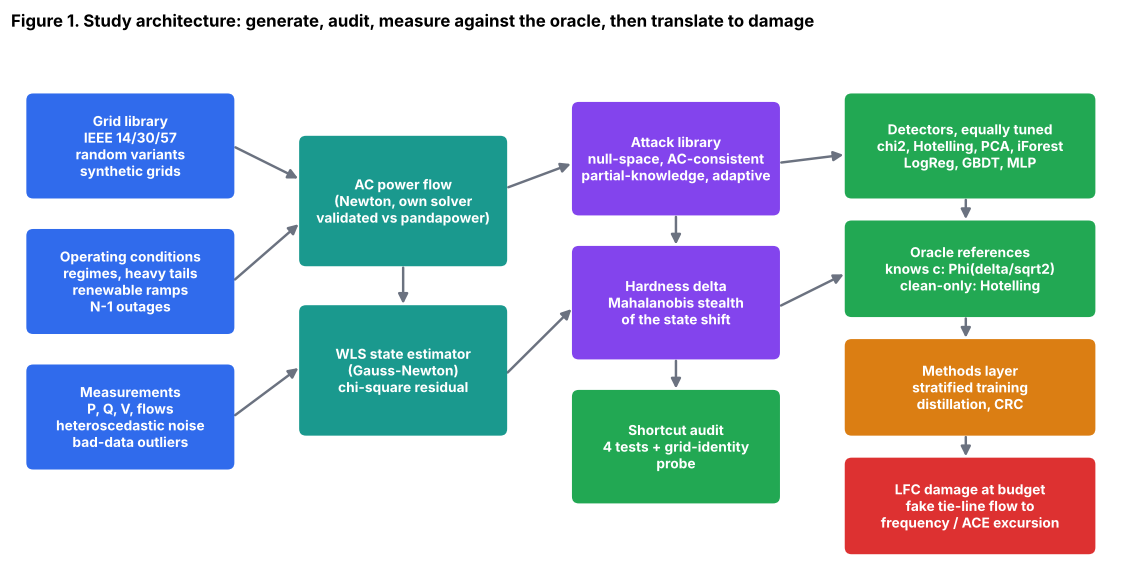

PosixPath('/tmp/w2/proj/figures/fig01_architecture.png')

In [4]:
def box(ax, xy, w, h, text, color, fs=9, tc="white"):
    x, y = xy
    p = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                       fc=color, ec="none", alpha=0.95, zorder=3)
    ax.add_patch(p)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", color=tc, fontsize=fs,
            fontweight="bold", zorder=4, wrap=True)

def arrow(ax, p0, p1, color=PAL["grey"], rad=0.0, lw=1.6):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=13, lw=lw,
                                 color=color, connectionstyle=f"arc3,rad={rad}", zorder=2))

fig, ax = plt.subplots(figsize=(13, 6.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off")
ax.set_title("Figure 1. Study architecture: generate, audit, measure against the oracle, then translate to damage",
             loc="left")

# column 1: generation
box(ax, (0.2, 4.3), 2.4, 1.2, "Grid library\nIEEE 14/30/57\nrandom variants\nsynthetic grids", PAL["blue"])
box(ax, (0.2, 2.7), 2.4, 1.2, "Operating conditions\nregimes, heavy tails\nrenewable ramps\nN-1 outages", PAL["blue"])
box(ax, (0.2, 1.1), 2.4, 1.2, "Measurements\nP, Q, V, flows\nheteroscedastic noise\nbad-data outliers", PAL["blue"])
# column 2: physics
box(ax, (3.4, 3.5), 2.4, 1.5, "AC power flow\n(Newton, own solver\nvalidated vs pandapower)", PAL["teal"])
box(ax, (3.4, 1.5), 2.4, 1.5, "WLS state estimator\n(Gauss-Newton)\nchi-square residual", PAL["teal"])
# column 3: attacks + audit
box(ax, (6.6, 4.1), 2.4, 1.3, "Attack library\nnull-space, AC-consistent\npartial-knowledge, adaptive", PAL["purple"])
box(ax, (6.6, 2.4), 2.4, 1.3, "Hardness delta\nMahalanobis stealth\nof the state shift", PAL["purple"])
box(ax, (6.6, 0.7), 2.4, 1.3, "Shortcut audit\n4 tests + grid-identity\nprobe", PAL["green"])
# column 4: measurement
box(ax, (9.8, 4.3), 2.9, 1.2, "Detectors, equally tuned\nchi2, Hotelling, PCA, iForest\nLogReg, GBDT, MLP", PAL["green"])
box(ax, (9.8, 2.9), 2.9, 1.1, "Oracle references\nknows c: Phi(delta/sqrt2)\nclean-only: Hotelling", PAL["green"])
box(ax, (9.8, 1.5), 2.9, 1.1, "Methods layer\nstratified training\ndistillation, CRC", PAL["amber"])
box(ax, (9.8, 0.1), 2.9, 1.1, "LFC damage at budget\nfake tie-line flow to\nfrequency / ACE excursion", PAL["red"])

for a, b in [((2.6, 4.9), (3.4, 4.5)), ((2.6, 3.3), (3.4, 4.0)), ((2.6, 1.7), (3.4, 2.3)),
             ((4.6, 3.5), (4.6, 3.0)), ((5.8, 4.4), (6.6, 4.7)), ((5.8, 2.2), (6.6, 3.0)),
             ((7.8, 4.1), (7.8, 3.7)), ((7.8, 2.4), (7.8, 2.0)),
             ((9.0, 4.7), (9.8, 4.8)), ((9.0, 3.0), (9.8, 3.4)), ((11.2, 4.3), (11.2, 4.0)),
             ((11.2, 2.9), (11.2, 2.6)), ((11.2, 1.5), (11.2, 1.2))]:
    arrow(ax, a, b)
savefig(fig, "fig01_architecture")

## Part 2. Theory: what "best possible" means

### 2.1 The setting in one paragraph

A state estimator turns measurements $z$ into a state estimate $\hat x$. A *stealth* (null-space) false-data injection adds $a = Hc$ to the measurements, with $H$ the measurement Jacobian. The residual $r = z - H\hat x$ is unchanged because $Hc$ lies in the column space of $H$ and the residual lives in its orthogonal complement. The classical chi-square bad-data test, which looks only at $r$, therefore cannot see the attack. The attack's only footprint is a shift $c$ of the *state estimate*. Whether that shift is detectable depends on how large it is compared with how much the estimate wanders on its own, because load and generation vary all day.

**Hardness.** If $\Sigma$ is the covariance of the clean state estimate, the hardness of a shift $c$ is its Mahalanobis length

$$\delta(c)=\sqrt{c^{\top}\Sigma^{-1}c}.$$

**Oracle detector.** For a *known* direction $c$ and Gaussian clean estimates, the likelihood-ratio test is $s=c^\top\Sigma^{-1}(\hat x-\mu)$, and its operating characteristic is exact:

$$\mathrm{TPR}(\alpha)=\Phi\!\big(\delta-\Phi^{-1}(1-\alpha)\big),\qquad \mathrm{AUROC}=\Phi\!\big(\delta/\sqrt{2}\big).$$

No detector, learned or not, can beat this for that $c$ under the Gaussian model (Neyman–Pearson). This is known theory (it is the likelihood-ratio result behind the Gaussian-stealth literature); what we add is checking it on non-Gaussian AC data and using it as a yardstick for learned detectors.

**Clean-only reference.** A real operator does not know $c$. A detector trained only on clean data can at best test whether $\hat x$ is plausible in *all* $n$ directions, i.e. Hotelling's $T^2=(\hat x-\mu)^\top\Sigma^{-1}(\hat x-\mu)$, which under attack is non-central $\chi^2_n(\delta^2)$. Its power is lower than the oracle's and falls as $n$ grows.

**Damage ceiling.** If an attack of hardness $\delta$ fakes a tie-line flow $h^\top c$, the largest fake flow it can cause is $\delta\sqrt{h^\top\Sigma h}$, reached at $c^\star=\delta\,\Sigma h/\sqrt{h^\top\Sigma h}$ (Lagrange / Cauchy–Schwarz in the $\Sigma^{-1}$ inner product).

In [5]:
def oracle_tpr(delta, alpha):
    """TPR of the likelihood-ratio detector at false-alarm rate alpha."""
    return st.norm.cdf(np.asarray(delta) - st.norm.ppf(1 - np.asarray(alpha)))

def oracle_auc(delta):
    return st.norm.cdf(np.asarray(delta) / np.sqrt(2.0))

def hotelling_tpr(delta, n, alpha):
    """Power of the clean-only chi2_n test against a shift of hardness delta."""
    thr = st.chi2.ppf(1 - alpha, n)
    return st.ncx2.sf(thr, n, np.asarray(delta) ** 2)

def hotelling_auc(delta, n, grid=4000):
    """AUROC between chi2_n (clean) and ncx2(n, delta^2) (attacked): P(X_a > X_c)."""
    delta = np.atleast_1d(delta).astype(float)
    hi = st.chi2.ppf(1 - 1e-9, n) + (delta.max() + 8) ** 2
    x = np.linspace(0, hi, grid)
    Fc = st.chi2.cdf(x, n)
    return np.array([np.trapezoid(st.ncx2.pdf(x, n, d ** 2) * Fc, x) for d in delta])

# --- Monte-Carlo check of the closed forms (pure Gaussian world) ---------------
rg = rng_for("theory_mc")
n_dim, n_mc = 12, 40000
A = rg.normal(size=(n_dim, n_dim)); Sigma_t = A @ A.T / n_dim + 0.3 * np.eye(n_dim)
Li = np.linalg.cholesky(Sigma_t); Sinv = np.linalg.inv(Sigma_t)
rows = []
for d in [0.5, 1.0, 2.0, 3.0]:
    u = rg.normal(size=n_dim); u /= np.sqrt(u @ Sinv @ u); c = d * u          # hardness exactly d
    xc = rg.normal(size=(n_mc, n_dim)) @ Li.T
    xa = rg.normal(size=(n_mc, n_dim)) @ Li.T + c
    s_or_c, s_or_a = xc @ Sinv @ c, xa @ Sinv @ c
    t2_c = np.einsum("ij,jk,ik->i", xc, Sinv, xc); t2_a = np.einsum("ij,jk,ik->i", xa, Sinv, xa)
    rows.append(dict(delta=d,
        auc_oracle_mc=roc_auc_score(np.r_[np.zeros(n_mc), np.ones(n_mc)], np.r_[s_or_c, s_or_a]),
        auc_oracle_formula=float(oracle_auc(d)),
        auc_T2_mc=roc_auc_score(np.r_[np.zeros(n_mc), np.ones(n_mc)], np.r_[t2_c, t2_a]),
        auc_T2_formula=float(hotelling_auc(d, n_dim)[0])))
print(pd.DataFrame(rows).round(4).to_string(index=False))

# --- damage-ceiling check -------------------------------------------------------
h_t = rg.normal(size=n_dim)
c_star = 2.0 * Sigma_t @ h_t / np.sqrt(h_t @ Sigma_t @ h_t)
dirs = rg.normal(size=(200000, n_dim)); dirs /= np.sqrt(np.einsum("ij,jk,ik->i", dirs, Sinv, dirs))[:, None]
print(f"\nhardness of c*            : {np.sqrt(c_star @ Sinv @ c_star):.4f}")
print(f"h'c* (closed form)         : {h_t @ c_star:.4f}  vs  delta*sqrt(h'Sh) = {2.0*np.sqrt(h_t@Sigma_t@h_t):.4f}")
print(f"best of 200k random dirs   : {(2.0 * dirs @ h_t).max():.4f}  (must not exceed the ceiling)")

 delta  auc_oracle_mc  auc_oracle_formula  auc_T2_mc  auc_T2_formula
   0.5         0.6386              0.6382     0.5139          0.5140
   1.0         0.7598              0.7602     0.5524          0.5543
   2.0         0.9213              0.9214     0.6903          0.6922
   3.0         0.9830              0.9831     0.8426          0.8448

hardness of c*            : 2.0000
h'c* (closed form)         : 5.4596  vs  delta*sqrt(h'Sh) = 5.4596
best of 200k random dirs   : 4.5648  (must not exceed the ceiling)


### 2.2 Two figures that carry the whole idea (Figures 2 and 3)

Figure 2 shows the geometry: why the residual test is blind to the attack, and why *equal-sized* attacks can have very different hardness. Figure 3 shows the oracle's ROC family and how the clean-only reference degrades with dimension.

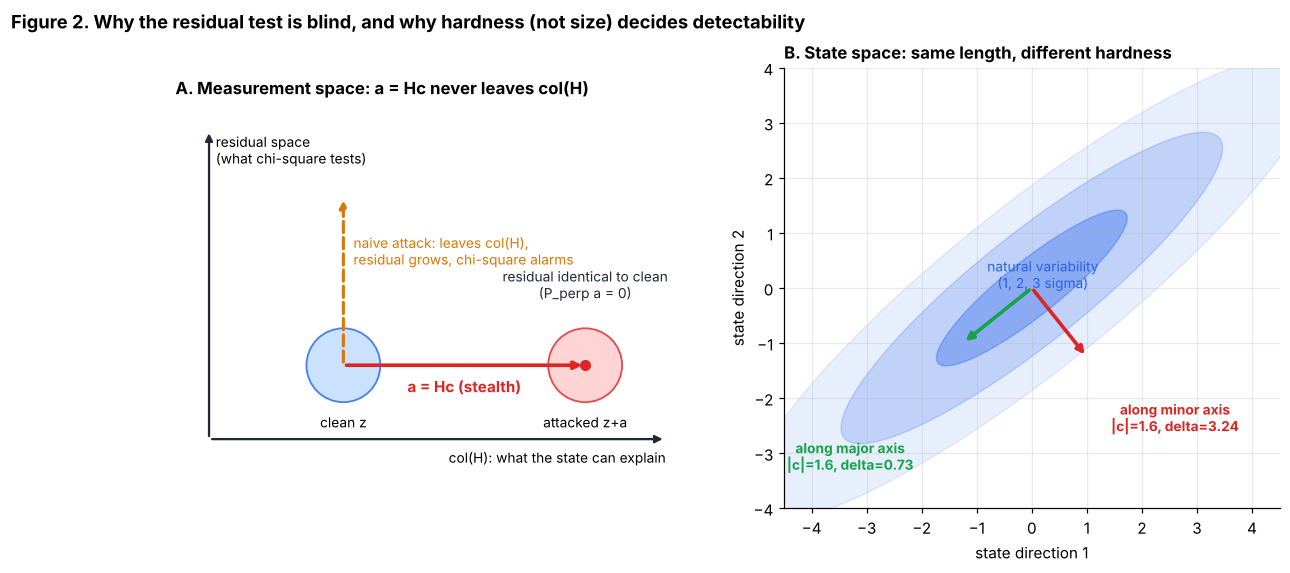

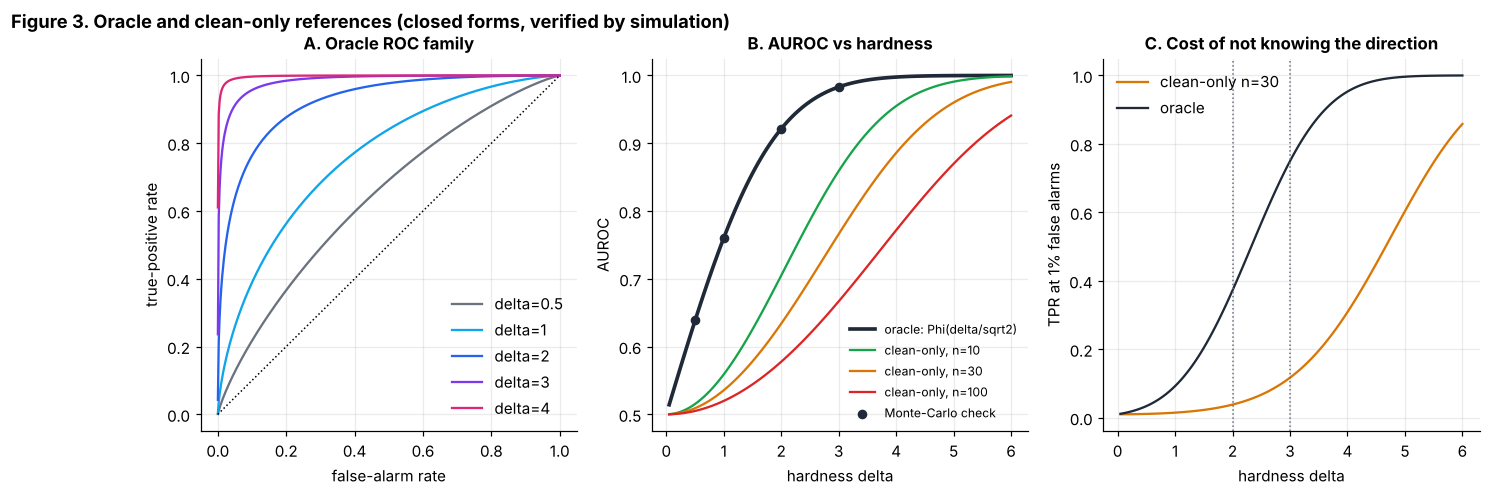

PosixPath('/tmp/w2/proj/figures/fig03_oracle_roc.png')

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel A: measurement-space decomposition
ax = axes[0]; ax.set_xlim(-0.5, 7); ax.set_ylim(-0.5, 5); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("A. Measurement space: a = Hc never leaves col(H)", loc="left")
ax.annotate("", xy=(6.8, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=1.5, color=PAL["ink"]))
ax.annotate("", xy=(0, 4.6), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=1.5, color=PAL["ink"]))
ax.text(6.8, -0.35, "col(H): what the state can explain", ha="right", fontsize=9)
ax.text(0.1, 4.55, "residual space\n(what chi-square tests)", fontsize=9, va="top")
ax.add_patch(Circle((2.0, 1.1), 0.55, fc="#bfdbfe", ec=PAL["blue"], lw=1.2, alpha=0.8))
ax.text(2.0, 0.25, "clean z", ha="center", va="center", fontsize=9)
ax.annotate("", xy=(5.6, 1.1), xytext=(2.0, 1.1), arrowprops=dict(arrowstyle="-|>", lw=2.4, color=PAL["red"]))
ax.text(3.8, 0.7, "a = Hc (stealth)", color=PAL["red"], ha="center", fontsize=10, fontweight="bold")
ax.add_patch(Circle((5.6, 1.1), 0.55, fc="#fecaca", ec=PAL["red"], lw=1.2, alpha=0.8))
ax.text(5.6, 0.25, "attacked z+a", ha="center", va="center", fontsize=9)
ax.annotate("", xy=(2.0, 3.6), xytext=(2.0, 1.1), arrowprops=dict(arrowstyle="-|>", lw=2.0, color=PAL["amber"], ls="--"))
ax.text(2.15, 2.6, "naive attack: leaves col(H),\nresidual grows, chi-square alarms", color=PAL["amber"], fontsize=9)
ax.plot([5.6, 5.6], [1.1, 1.1], "o", color=PAL["red"])
ax.text(5.6, 2.1, "residual identical to clean\n(P_perp a = 0)", ha="center", color=PAL["ink"], fontsize=9)

# Panel B: state space with covariance ellipse
ax = axes[1]
ax.set_title("B. State space: same length, different hardness", loc="left")
Sg = np.array([[3.0, 2.2], [2.2, 2.0]]); w, V = np.linalg.eigh(Sg)
th = np.linspace(0, 2 * np.pi, 200)
for k, a_ in [(1, 0.35), (2, 0.2), (3, 0.1)]:
    e = V @ np.diag(np.sqrt(w)) @ np.vstack([np.cos(th), np.sin(th)]) * k
    ax.fill(e[0], e[1], color=PAL["blue"], alpha=a_)
ax.text(0.2, 0.0, "natural variability\n(1, 2, 3 sigma)", fontsize=9, color=PAL["blue"], ha="center")
L = 1.6
for vec, col, lab in [(V[:, 1], PAL["green"], "along major axis"), (V[:, 0], PAL["red"], "along minor axis")]:
    c_ = L * vec; d_ = np.sqrt(c_ @ np.linalg.inv(Sg) @ c_)
    ax.annotate("", xy=c_, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2.4, color=col))
    pos = (-3.3, -3.3) if c_[0] < 0 else (2.6, -2.6)
    ax.text(pos[0], pos[1], f"{lab}\n|c|={L:.1f}, delta={d_:.2f}", color=col, fontsize=9, ha="center", fontweight="bold")
ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4, 4); ax.set_aspect("equal")
ax.set_xlabel("state direction 1"); ax.set_ylabel("state direction 2")
fig.suptitle("Figure 2. Why the residual test is blind, and why hardness (not size) decides detectability", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig02_geometry")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
al = np.linspace(1e-4, 1 - 1e-4, 400)
ax = axes[0]
for d, col in zip([0.5, 1, 2, 3, 4], [PAL["grey"], PAL["sky"], PAL["blue"], PAL["purple"], PAL["pink"]]):
    ax.plot(al, oracle_tpr(d, al), color=col, label=f"delta={d}")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false-alarm rate"); ax.set_ylabel("true-positive rate")
ax.set_title("A. Oracle ROC family"); ax.legend()
ax = axes[1]
dd = np.linspace(0.05, 6, 120)
ax.plot(dd, oracle_auc(dd), color=PAL["ink"], lw=2.4, label="oracle: Phi(delta/sqrt2)")
for n_, col in [(10, PAL["green"]), (30, PAL["amber"]), (100, PAL["red"])]:
    ax.plot(dd, hotelling_auc(dd, n_), color=col, label=f"clean-only, n={n_}")
mc = pd.DataFrame(rows)
ax.scatter(mc.delta, mc.auc_oracle_mc, c=PAL["ink"], s=28, zorder=5, label="Monte-Carlo check")
ax.set_xlabel("hardness delta"); ax.set_ylabel("AUROC"); ax.set_title("B. AUROC vs hardness"); ax.legend(fontsize=8)
ax = axes[2]
ax.plot(dd, hotelling_tpr(dd, 30, 0.01), color=PAL["amber"], label="clean-only n=30")
ax.plot(dd, oracle_tpr(dd, 0.01), color=PAL["ink"], label="oracle")
for d0 in (2.0, 3.0): ax.axvline(d0, color=PAL["grey"], ls=":", lw=1)
ax.set_xlabel("hardness delta"); ax.set_ylabel("TPR at 1% false alarms")
ax.set_title("C. Cost of not knowing the direction"); ax.legend()
fig.suptitle("Figure 3. Oracle and clean-only references (closed forms, verified by simulation)", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig03_oracle_roc")

## Part 3. Grid library

The benchmark's value depends on grid diversity, so grids are data objects that can be cloned and modified, not fixed library calls. Three sources feed the library:

1. **IEEE cases** (14, 30, 57 buses) read from `pandapower`'s internal power-flow case (`ppc`), then stored in our own `Grid` container.
2. **Randomized variants**: remove a few lines while keeping the network connected, jitter line impedances by about ±15%, and re-site loads among load buses.
3. **Synthetic grids** with random bus counts: random geometric networks with a spanning backbone plus extra loops, log-normal loads, and generators on a random subset of buses.

Every grid carries a `family` tag and an `area` label (a two-area partition by Kernighan–Lin bisection), which later defines the tie lines for the LFC study. The benchmark family itself is assembled in Part 4.2, after the physics core exists, so that each grid can be screened for power-flow convergence. Branch and bus data stay in per-unit and megawatt arrays so the physics core in Part 4 can rebuild admittance matrices for any topology, including N−1 outages.

In [7]:
@dataclass
class Grid:
    name: str
    baseMVA: float
    bustype: np.ndarray            # 1 PQ, 2 PV, 3 reference
    Pd: np.ndarray; Qd: np.ndarray # MW, MVAr
    Gs: np.ndarray; Bs: np.ndarray # shunt MW, MVAr at 1 pu
    gen_bus: np.ndarray; gen_P: np.ndarray; gen_V: np.ndarray
    f: np.ndarray; t: np.ndarray   # branch end buses (0-based)
    r: np.ndarray; x: np.ndarray; b: np.ndarray
    tap: np.ndarray; shift: np.ndarray   # tap ratio, phase shift (rad)
    status: np.ndarray             # bool per branch
    family: str = ""
    area: np.ndarray = None
    meta: dict = field(default_factory=dict)

    @property
    def n(self): return len(self.bustype)
    @property
    def nl(self): return len(self.f)

    def clone(self, **kw):
        d = {k: (v.copy() if isinstance(v, np.ndarray) else v) for k, v in self.__dict__.items()}
        d["meta"] = dict(self.meta); d.update(kw)
        return Grid(**d)

    def graph(self, only_active=True):
        G = nx.Graph(); G.add_nodes_from(range(self.n))
        for k in range(self.nl):
            if self.status[k] or not only_active:
                G.add_edge(int(self.f[k]), int(self.t[k]), k=k)
        return G

def grid_from_pandapower(net, name, family="ieee"):
    pp.runpp(net, init="flat", numba=False)
    ppc = net._ppc
    bus, gen, br = ppc["bus"], ppc["gen"], ppc["branch"]
    idx = {int(b): i for i, b in enumerate(bus[:, 0])}
    live = br[:, 10] > 0
    gmask = gen[:, 7] > 0
    tap = br[live, 8].copy(); tap[tap == 0] = 1.0
    g = Grid(name=name, baseMVA=float(ppc["baseMVA"]), bustype=bus[:, 1].astype(int),
             Pd=bus[:, 2].copy(), Qd=bus[:, 3].copy(), Gs=bus[:, 4].copy(), Bs=bus[:, 5].copy(),
             gen_bus=np.array([idx[int(b)] for b in gen[gmask, 0]]), gen_P=gen[gmask, 1].copy(), gen_V=gen[gmask, 5].copy(),
             f=np.array([idx[int(b)] for b in br[live, 0]]), t=np.array([idx[int(b)] for b in br[live, 1]]),
             r=br[live, 2].copy(), x=br[live, 3].copy(), b=br[live, 4].copy(),
             tap=tap, shift=np.deg2rad(br[live, 9]), status=np.ones(int(live.sum()), bool), family=family)
    g.meta["Vm_ref"] = bus[:, 7].copy()
    return g

def assign_areas(g, seed=0):
    """Two-area partition (balanced min-cut heuristic) -> g.area in {0,1}."""
    G = g.graph()
    A, B = nx.algorithms.community.kernighan_lin_bisection(G, seed=seed)
    area = np.zeros(g.n, int); area[list(B)] = 1
    g.area = area
    g.meta["tie"] = np.where(area[g.f] != area[g.t])[0]
    return g

def is_connected_without(g, drop):
    G = g.graph()
    G.remove_edges_from([(int(g.f[k]), int(g.t[k])) for k in drop])
    return nx.is_connected(G)

def variant_grid(base, rng, n_remove=2, jitter=0.15, resite=True, name=None):
    g = base.clone(name=name or base.name + "_v", family="variant")
    cand = list(rng.permutation(g.nl)); dropped = []
    for k in cand:
        if len(dropped) >= n_remove: break
        if is_connected_without(g, dropped + [k]): dropped.append(int(k))
    g.status[dropped] = False
    # drop them physically so downstream code never sees dead branches
    keep = g.status
    for a in ["f", "t", "r", "x", "b", "tap", "shift"]:
        setattr(g, a, getattr(g, a)[keep])
    g.status = np.ones(len(g.f), bool)
    s = rng.uniform(1 - jitter, 1 + jitter, size=g.nl)
    g.r, g.x, g.b = g.r * s, g.x * s, g.b * rng.uniform(1 - jitter, 1 + jitter, size=g.nl)
    if resite:
        load_buses = np.where((g.Pd > 0) & (g.bustype == 1))[0]
        perm = rng.permutation(load_buses)
        g.Pd[load_buses], g.Qd[load_buses] = g.Pd[perm], g.Qd[perm]
    g.meta["removed"] = dropped
    return g

def synthetic_grid(n, rng, name, extra_loops=0.35, load_mw=(4, 60), baseMVA=100.0):
    """Random geometric grid: connected backbone (MST on random points) + extra short links."""
    pts = rng.uniform(0, 1, size=(n, 2))
    D = np.linalg.norm(pts[:, None] - pts[None], axis=2)
    G = nx.Graph(); G.add_nodes_from(range(n))
    for i in range(n):
        for j in range(i + 1, n): G.add_edge(i, j, w=D[i, j])
    T = nx.minimum_spanning_tree(G, weight="w")
    edges = set(map(lambda e: tuple(sorted(e)), T.edges()))
    order = np.dstack(np.unravel_index(np.argsort(D + np.eye(n) * 9), D.shape))[0]
    want = int(extra_loops * n)
    for i, j in order:
        if len(edges) >= (n - 1) + want: break
        e = tuple(sorted((int(i), int(j))))
        if e not in edges and rng.random() < 0.5: edges.add(e)
    edges = sorted(edges)
    f = np.array([e[0] for e in edges]); t = np.array([e[1] for e in edges])
    d = D[f, t]
    x = 0.04 + 0.35 * d * rng.uniform(0.8, 1.2, size=len(d))
    r = x * rng.uniform(0.12, 0.35, size=len(d))
    b = 0.02 + 0.05 * d
    Pd = np.exp(rng.normal(np.log(np.mean(load_mw)), 0.6, size=n)).clip(*load_mw)
    Pd[rng.random(n) < 0.15] = 0.0
    Qd = Pd * rng.uniform(0.2, 0.45, size=n)
    ng = max(2, n // 5)
    gb = rng.choice(n, size=ng, replace=False)
    ref = int(gb[0])
    btype = np.ones(n, int); btype[gb] = 2; btype[ref] = 3
    Pg = np.zeros(ng); share = rng.uniform(0.7, 1.3, size=ng); share /= share.sum()
    Pg = share * Pd.sum() * 1.02
    g = Grid(name=name, baseMVA=baseMVA, bustype=btype, Pd=Pd, Qd=Qd, Gs=np.zeros(n), Bs=np.zeros(n),
             gen_bus=gb, gen_P=Pg, gen_V=rng.uniform(1.0, 1.04, size=ng),
             f=f, t=t, r=r, x=x, b=b, tap=np.ones(len(f)), shift=np.zeros(len(f)),
             status=np.ones(len(f), bool), family="synthetic")
    return g

In [8]:
base14 = grid_from_pandapower(pn.case14(), "ieee14")
base30 = grid_from_pandapower(pn.case30(), "ieee30")
base57 = grid_from_pandapower(pn.case57(), "ieee57")
for g in (base14, base30, base57): assign_areas(g)
print(f"{'grid':<8}{'buses':>6}{'branches':>9}{'gens':>5}{'load MW':>9}{'tie lines':>10}")
for g in (base14, base30, base57):
    print(f"{g.name:<8}{g.n:>6}{g.nl:>9}{len(g.gen_bus):>5}{g.Pd.sum():>9.1f}{len(g.meta['tie']):>10}")

grid     buses branches gens  load MW tie lines
ieee14      14       20    5    259.0         3
ieee30      30       41    6    189.2         5
ieee57      57       80    7   1250.8         6


## Part 4. Physics core

Everything here is written from scratch in NumPy so that every step of the data-generating process is inspectable, and then **validated against `pandapower`** before any dataset is built.

| Block | What it does | Validation |
|---|---|---|
| Admittance matrices | $Y_{bus}$, $Y_f$, $Y_t$ from branch data, any topology | compared with pandapower's `makeYbus` |
| Newton–Raphson power flow | polar form, PV/PQ handling | voltages compared with `pandapower.runpp` on the base cases |
| Measurement model $h(x)$ | bus injections $P,Q$, voltage magnitudes, branch flows $P_f$ | analytic Jacobian vs finite differences |
| WLS state estimator | Gauss–Newton on $\min_x (z-h(x))^\top W (z-h(x))$ | recovers the true state under noise; $\chi^2$ statistic matches its theoretical distribution |

State vector: $x=[\theta_{\text{non-ref}},\,V_m]$ with $2n-1$ entries.

In [9]:
def build_Y(g):
    """Return Ybus (n x n), Yf, Yt (nl x n), Cf, Ct incidence for the ACTIVE branches of g."""
    n, nl = g.n, g.nl
    act = g.status
    ys = 1.0 / (g.r + 1j * g.x)
    bc = 1j * g.b
    tap = g.tap * np.exp(1j * g.shift)
    Ytt = ys + bc / 2
    Yff = Ytt / (tap * np.conj(tap))
    Yft = -ys / np.conj(tap)
    Ytf = -ys / tap
    Yff, Yft, Ytf, Ytt = [np.where(act, a, 0.0) for a in (Yff, Yft, Ytf, Ytt)]
    Cf = np.zeros((nl, n)); Ct = np.zeros((nl, n))
    Cf[np.arange(nl), g.f] = 1.0; Ct[np.arange(nl), g.t] = 1.0
    Yf = Yff[:, None] * Cf + Yft[:, None] * Ct
    Yt = Ytf[:, None] * Cf + Ytt[:, None] * Ct
    Ysh = (g.Gs + 1j * g.Bs) / g.baseMVA
    Ybus = Cf.T @ Yf + Ct.T @ Yt + np.diag(Ysh)
    return Ybus, Yf, Yt, Cf, Ct

class Model:
    """Precomputed matrices for one grid topology."""
    def __init__(self, g):
        self.g = g
        self.Ybus, self.Yf, self.Yt, self.Cf, self.Ct = build_Y(g)
        self.n, self.nl = g.n, g.nl
        self.ref = int(np.where(g.bustype == 3)[0][0])
        self.pv = np.where(g.bustype == 2)[0]
        self.pq = np.where(g.bustype == 1)[0]
        self.pvpq = np.r_[self.pv, self.pq]
        self.nonref = np.array([i for i in range(self.n) if i != self.ref])
        # generator voltage set-points per bus
        self.Vset = np.ones(self.n)
        for b_, v_ in zip(g.gen_bus, g.gen_V): self.Vset[b_] = v_

def dS_dV(M, V):
    Ibus = M.Ybus @ V; Vn = V / np.abs(V)
    dVm = V[:, None] * np.conj(M.Ybus * Vn[None, :]) + np.diag(np.conj(Ibus) * Vn)
    dVa = 1j * V[:, None] * np.conj(np.diag(Ibus) - M.Ybus * V[None, :])
    return dVm, dVa

def newton_pf(M, Pd, Qd, Pg_bus, V0=None, tol=1e-9, maxit=25):
    """Polar Newton-Raphson. Pd, Qd in MW/MVAr per bus; Pg_bus in MW per bus (slack output is free)."""
    g = M.g; n = M.n
    Sbus = ((Pg_bus - Pd) + 1j * (-Qd)) / g.baseMVA
    V = (np.ones(n, complex) if V0 is None else V0.copy())
    Vm = np.abs(V); Va = np.angle(V)
    Vm[np.r_[M.pv, M.ref]] = M.Vset[np.r_[M.pv, M.ref]]
    V = Vm * np.exp(1j * Va)
    pvpq, pq = M.pvpq, M.pq
    for it in range(maxit):
        S = V * np.conj(M.Ybus @ V)
        mis = S - Sbus
        F = np.r_[mis[pvpq].real, mis[pq].imag]
        if np.max(np.abs(F)) < tol: return V, True, it
        dVm, dVa = dS_dV(M, V)
        J = np.block([[dVa[np.ix_(pvpq, pvpq)].real, dVm[np.ix_(pvpq, pq)].real],
                      [dVa[np.ix_(pq, pvpq)].imag,   dVm[np.ix_(pq, pq)].imag]])
        try: dx = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError: return V, False, it
        Va[pvpq] += dx[:len(pvpq)]; Vm[pq] += dx[len(pvpq):]
        V = Vm * np.exp(1j * Va)
    return V, False, maxit

def meas_h(M, V):
    """Full measurement vector [P_inj(n), Q_inj(n), Vm(n), Pf(nl)] in per unit."""
    S = V * np.conj(M.Ybus @ V)
    Sf = (M.Cf @ V) * np.conj(M.Yf @ V)
    return np.r_[S.real, S.imag, np.abs(V), Sf.real]

def meas_jac(M, V):
    """Analytic Jacobian of meas_h wrt x = [Va_nonref, Vm]."""
    n = M.n; Vn = V / np.abs(V)
    dVm, dVa = dS_dV(M, V)
    Vf = M.Cf @ V; If = M.Yf @ V
    dSf_dVa = 1j * (np.conj(If)[:, None] * M.Cf * V[None, :] - Vf[:, None] * np.conj(M.Yf * V[None, :]))
    dSf_dVm = Vf[:, None] * np.conj(M.Yf * Vn[None, :]) + np.conj(If)[:, None] * M.Cf * Vn[None, :]
    H = np.zeros((3 * n + M.nl, 2 * n - 1))
    ne = M.nonref
    H[:n, :n - 1] = dVa[:, ne].real;  H[:n, n - 1:] = dVm.real
    H[n:2 * n, :n - 1] = dVa[:, ne].imag; H[n:2 * n, n - 1:] = dVm.imag
    H[2 * n:3 * n, n - 1:] = np.eye(n)
    H[3 * n:, :n - 1] = dSf_dVa[:, ne].real; H[3 * n:, n - 1:] = dSf_dVm.real
    return H

def x_to_V(M, x, Va_ref=0.0):
    n = M.n
    Va = np.zeros(n); Va[M.nonref] = x[:n - 1]; Va[M.ref] = Va_ref
    return x[n - 1:] * np.exp(1j * Va)

def V_to_x(M, V):
    return np.r_[np.angle(V)[M.nonref] - np.angle(V)[M.ref], np.abs(V)]

### 4.1 Validation against pandapower (Figure 5)

Three checks, all on the three IEEE cases: (i) admittance matrix agreement, (ii) Newton power flow versus `pandapower.runpp`, (iii) analytic Jacobian versus central finite differences. If any of them fails, nothing downstream can be trusted, so the cell stops with an assertion.

  grid  converged  iters   max_dY  max_dVm  max_dVa_rad   max_dJ
ieee14       True      4 0.00e+00 4.44e-16     1.67e-16 4.27e-09
ieee30       True      3 0.00e+00 5.55e-16     2.02e-15 4.80e-09
ieee57       True      5 0.00e+00 2.89e-15     5.50e-15 7.72e-09


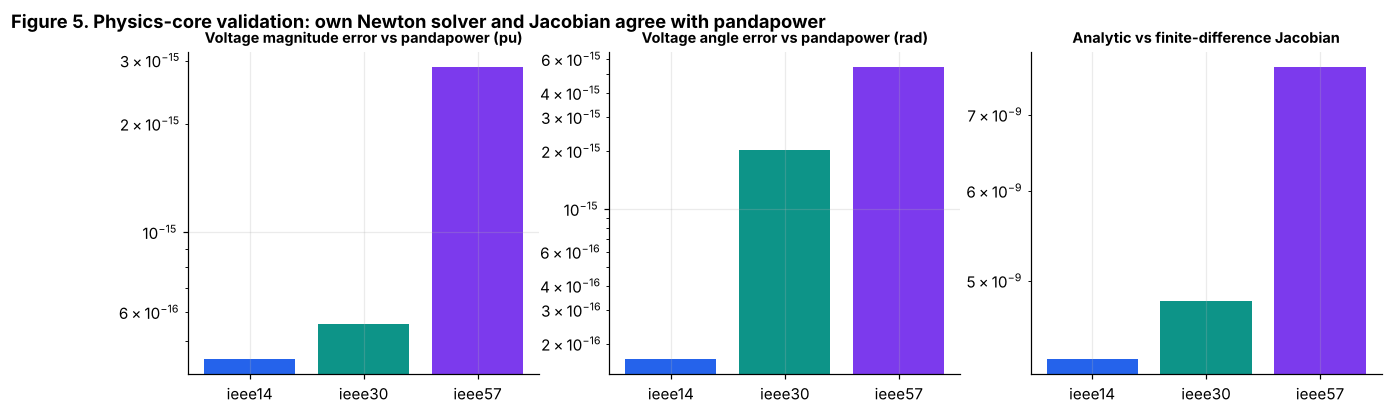

PosixPath('/tmp/w2/proj/figures/fig05_physics_validation.png')

In [10]:
val_rows = []
for name, mk in [("ieee14", pn.case14), ("ieee30", pn.case30), ("ieee57", pn.case57)]:
    g = {"ieee14": base14, "ieee30": base30, "ieee57": base57}[name]; M = Model(g)
    # (i) Ybus vs pandapower's makeYbus
    net = mk(); pp.runpp(net, init="flat", numba=False); ppc = net._ppc
    Yb_pp, _, _ = _pp_makeYbus(ppc["baseMVA"], ppc["bus"], ppc["branch"])
    e_Y = np.abs(M.Ybus - Yb_pp.toarray()).max()
    # (ii) power flow vs pandapower voltages
    Pg_bus = np.zeros(g.n); np.add.at(Pg_bus, g.gen_bus, g.gen_P)
    V, ok, it = newton_pf(M, g.Pd, g.Qd, Pg_bus)
    Vm_pp = ppc["bus"][:, 7]; Va_pp = np.deg2rad(ppc["bus"][:, 8])
    e_vm = np.abs(np.abs(V) - Vm_pp).max()
    # pandapower reports angles relative to its slack reference
    e_va = np.abs((np.angle(V) - np.angle(V)[M.ref]) - (Va_pp - Va_pp[M.ref])).max()
    # (iii) Jacobian vs finite differences
    x0 = V_to_x(M, V); H = meas_jac(M, V); Hn = np.zeros_like(H); eps = 1e-6
    for j in range(len(x0)):
        xp, xm = x0.copy(), x0.copy(); xp[j] += eps; xm[j] -= eps
        Hn[:, j] = (meas_h(M, x_to_V(M, xp, np.angle(V)[M.ref])) - meas_h(M, x_to_V(M, xm, np.angle(V)[M.ref]))) / (2 * eps)
    e_J = np.abs(H - Hn).max()
    val_rows.append(dict(grid=name, converged=ok, iters=it, max_dY=e_Y, max_dVm=e_vm, max_dVa_rad=e_va, max_dJ=e_J))
val = pd.DataFrame(val_rows)
print(val.to_string(index=False, float_format=lambda v: f"{v:.2e}"))
assert (val.converged).all() and (val.max_dY < 1e-9).all() and (val.max_dVm < 1e-5).all() and (val.max_dJ < 1e-5).all(), \
    "physics core failed validation against pandapower"

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, ttl in zip(axes, ["max_dVm", "max_dVa_rad", "max_dJ"],
                        ["Voltage magnitude error vs pandapower (pu)", "Voltage angle error vs pandapower (rad)",
                         "Analytic vs finite-difference Jacobian"]):
    ax.bar(val.grid, val[col].clip(lower=1e-16), color=[PAL["blue"], PAL["teal"], PAL["purple"]])
    ax.set_yscale("log"); ax.set_title(ttl, fontsize=9.5)
fig.suptitle("Figure 5. Physics-core validation: own Newton solver and Jacobian agree with pandapower", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig05_physics_validation")

### 4.2 The benchmark family, with an acceptance screen (Figure 4)

The physics core now exists, so every generated grid can be screened before it is accepted. The grids below are fixed once here, from named seeds, and reused by every experiment. `TRAIN_FAMILY` is the broad randomized family used for training in Part 11; `UNSEEN` grids are never used for training or tuning.

* IEEE 14, 30 and 57-bus bases.
* `ieee14_v1`, `ieee14_v2`, `ieee30_v1`: variants with removed lines, jittered impedances and re-sited loads.
* `syn20`, `syn28`, `syn36`: synthetic grids in the training family.
* `ieee30_v2`, `syn24u`, `syn44u`: variants and synthetic grids held out as **unseen** grids, and IEEE 57 as the largest unseen grid.

Each grid has to pass a convergence screen (base load and 122% peak load) before it enters the family.

{'ieee14': '-', 'ieee30': '-', 'ieee57': '-', 'ieee14_v1': 1, 'ieee14_v2': 1, 'ieee30_v1': 6, 'syn20': 7, 'syn28': 11, 'syn36': 1, 'ieee30_v2': 1, 'syn24u': 4, 'syn44u': 16} <- tries needed to pass the screen


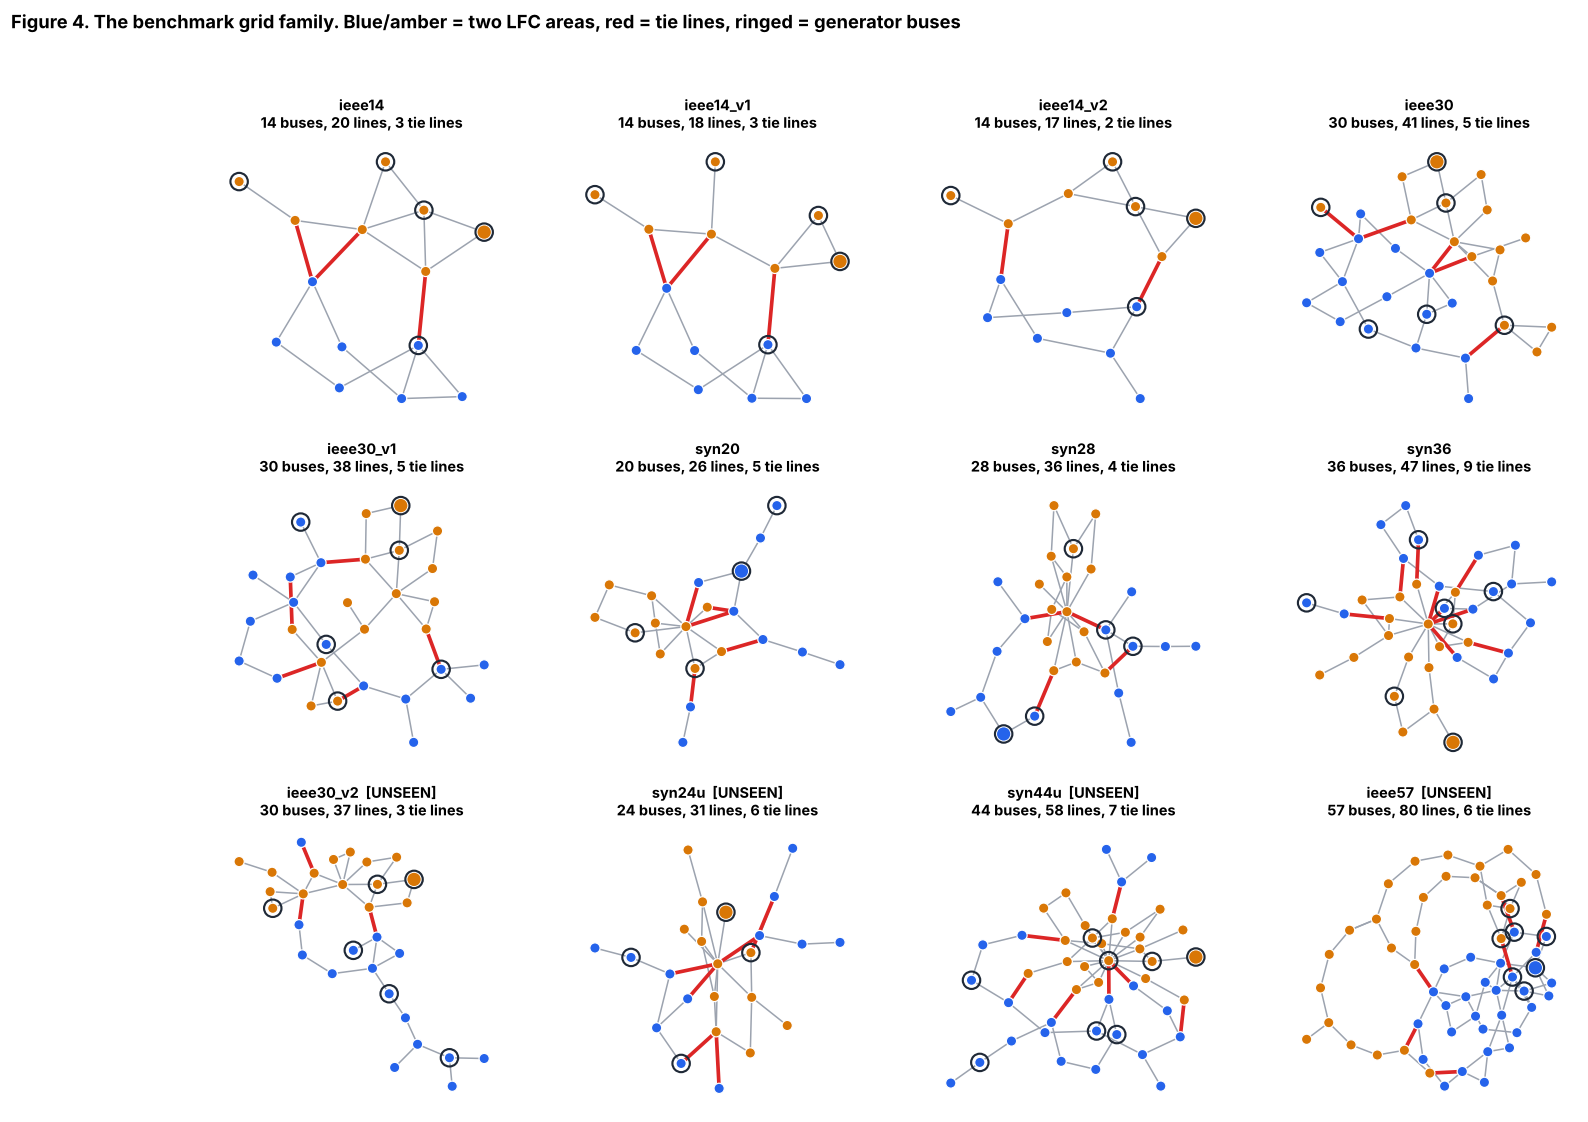

PosixPath('/tmp/w2/proj/figures/fig04_grid_family.png')

In [11]:
def accept(g, peak=1.22):
    """Screen: Newton power flow must converge at base load and at peak load with sane voltages."""
    try:
        M = Model(g)
        Pg = np.zeros(g.n); np.add.at(Pg, g.gen_bus, g.gen_P)
        for lvl in (1.0, peak):
            V, ok, _ = newton_pf(M, g.Pd * lvl, g.Qd * lvl, Pg * lvl)
            if not ok or np.abs(V).min() < 0.88 or np.abs(V).max() > 1.12: return False
        return True
    except Exception:
        return False

def screened(make, name, max_tries=40):
    for i in range(max_tries):
        g = assign_areas(make(i))
        g.name = name
        if accept(g): g.meta["tries"] = i + 1; return g
    raise RuntimeError(f"no acceptable grid found for {name}")

GRIDS = {"ieee14": base14, "ieee30": base30, "ieee57": base57}
GRIDS["ieee14_v1"] = screened(lambda i: variant_grid(base14, rng_for("g_v1", i), 2, 0.15, True, "ieee14_v1"), "ieee14_v1")
GRIDS["ieee14_v2"] = screened(lambda i: variant_grid(base14, rng_for("g_v2", i), 3, 0.20, True, "ieee14_v2"), "ieee14_v2")
GRIDS["ieee30_v1"] = screened(lambda i: variant_grid(base30, rng_for("g_v3", i), 3, 0.15, True, "ieee30_v1"), "ieee30_v1")
GRIDS["syn20"]     = screened(lambda i: synthetic_grid(20, rng_for("g_s20", i), "syn20"), "syn20")
GRIDS["syn28"]     = screened(lambda i: synthetic_grid(28, rng_for("g_s28", i), "syn28"), "syn28")
GRIDS["syn36"]     = screened(lambda i: synthetic_grid(36, rng_for("g_s36", i), "syn36"), "syn36")
# held-out grids (never used for training or tuning)
GRIDS["ieee30_v2"] = screened(lambda i: variant_grid(base30, rng_for("g_v4", i), 4, 0.25, True, "ieee30_v2"), "ieee30_v2")
GRIDS["syn24u"]    = screened(lambda i: synthetic_grid(24, rng_for("g_s24u", i), "syn24u"), "syn24u")
GRIDS["syn44u"]    = screened(lambda i: synthetic_grid(44, rng_for("g_s44u", i), "syn44u"), "syn44u")

TRAIN_FAMILY = ["ieee14", "ieee14_v1", "ieee14_v2", "ieee30", "ieee30_v1", "syn20", "syn28", "syn36"]
UNSEEN       = ["ieee30_v2", "syn24u", "syn44u", "ieee57"]
for k in UNSEEN: GRIDS[k].family = GRIDS[k].family + "_unseen"
print({k: GRIDS[k].meta.get("tries", "-") for k in GRIDS}, "<- tries needed to pass the screen")

def draw_grid(ax, g, title):
    G = g.graph()
    pos = nx.kamada_kawai_layout(G)
    tie = set(g.meta["tie"].tolist())
    cols = [PAL["blue"] if a == 0 else PAL["amber"] for a in g.area]
    ties = [(int(g.f[k]), int(g.t[k])) for k in tie]
    others = [(int(g.f[k]), int(g.t[k])) for k in range(g.nl) if k not in tie]
    nx.draw_networkx_edges(G, pos, edgelist=others, ax=ax, edge_color="#9ca3af", width=1.0)
    nx.draw_networkx_edges(G, pos, edgelist=ties, ax=ax, edge_color=PAL["red"], width=2.4)
    sizes = [90 if g.bustype[i] == 3 else 45 for i in range(g.n)]
    shapes = nx.draw_networkx_nodes(G, pos, ax=ax, node_color=cols, node_size=sizes, linewidths=0.8, edgecolors="white")
    gb = set(g.gen_bus.tolist())
    nx.draw_networkx_nodes(G, pos, nodelist=sorted(gb), ax=ax, node_color="none", node_size=130, edgecolors=PAL["ink"], linewidths=1.4)
    ax.set_title(f"{title}\n{g.n} buses, {g.nl} lines, {len(tie)} tie lines", fontsize=9.5)
    ax.axis("off")

order = TRAIN_FAMILY + UNSEEN
fig, axes = plt.subplots(3, 4, figsize=(16, 11.5))
for ax, k in zip(axes.ravel(), order):
    draw_grid(ax, GRIDS[k], k + ("  [UNSEEN]" if k in UNSEEN else ""))
fig.suptitle("Figure 4. The benchmark grid family. Blue/amber = two LFC areas, red = tie lines, ringed = generator buses",
             x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig04_grid_family")

### 4.3 Measurement set, noise and the WLS estimator

**Measurement set.** Each grid gets a random meter placement: every candidate meter (bus injection $P$, $Q$, voltage magnitude, branch flow $P_f$) is kept with probability 0.9, and the placement is redrawn until the Jacobian has full column rank (observability) and at least 1.5 times as many meters as states (redundancy, which is what gives the $\chi^2$ test its degrees of freedom).

**Noise.** Each meter's standard deviation is a type-specific base value times a fixed, grid-specific factor drawn log-uniformly from $[0.6, 1.6]$. This gives heteroscedastic noise without per-sample randomness in the weights, so one weight matrix serves every sample of a grid.

**Estimator.** Weighted least squares with $W=\mathrm{diag}(1/\sigma^2)$, solved by three Gauss–Newton iterations from the nominal operating point (the usual warm start, because an operator starts from the last estimate or forecast). The $\chi^2$ statistic is $J(\hat x)=r^\top W r$ with $m-(2n-1)$ degrees of freedom.

In [12]:
SIG_BASE = dict(P=0.004, Q=0.004, V=0.0012, F=0.004)    # per-unit standard deviations
KEEP_PROB = 0.90

def setup_meters(M, rng, V_nom):
    """Random meter placement + heteroscedastic noise; returns dict with indices and sigmas."""
    n, nl = M.n, M.nl
    types = np.r_[np.zeros(n, int), np.ones(n, int), 2 * np.ones(n, int), 3 * np.ones(nl, int)]
    base = np.array([SIG_BASE["P"], SIG_BASE["Q"], SIG_BASE["V"], SIG_BASE["F"]])[types]
    H_full = meas_jac(M, V_nom)
    for attempt in range(200):
        keep = rng.random(len(types)) < KEEP_PROB
        keep[2 * n + M.ref] = True       # always meter the reference voltage magnitude
        sel = np.where(keep)[0]
        H = H_full[sel]
        if len(sel) >= 1.5 * (2 * n - 1) and np.linalg.matrix_rank(H) == 2 * n - 1:
            break
    else:
        raise RuntimeError("could not find an observable meter placement")
    sig = base[sel] * np.exp(rng.uniform(np.log(0.6), np.log(1.6), size=len(sel)))
    return dict(sel=sel, sigma=sig, W=1.0 / sig ** 2, types=types[sel], m=len(sel), ns=2 * n - 1)

def wls_estimate(M, mt, z, x0, iters=3):
    """Gauss-Newton WLS. z: measured vector on mt['sel']. Returns xhat, chi2, residual."""
    sel, W = mt["sel"], mt["W"]
    x = x0.copy(); Va_ref = 0.0
    for _ in range(iters):
        V = x_to_V(M, x, Va_ref)
        r = z - meas_h(M, V)[sel]
        H = meas_jac(M, V)[sel]
        G = H.T @ (W[:, None] * H)
        dx = np.linalg.solve(G, H.T @ (W * r))
        x = x + dx
    V = x_to_V(M, x, Va_ref)
    r = z - meas_h(M, V)[sel]
    return x, float(np.sum(W * r * r)), r

### 4.4 Operating conditions and measurements

The estimator is only interesting if the grid moves on its own. Each sample draws an operating condition from the process below, solves the AC power flow, and measures it.

* **Regime switching.** Off-peak, normal or peak system loading (levels 0.78 / 1.0 / 1.22 with probabilities 0.3 / 0.5 / 0.2).
* **Spatial correlation.** A shared system factor, an area factor and a per-bus factor, so load changes are correlated within areas but not perfectly.
* **Heavy tails.** Per-bus factors are Student-$t$ with 4 degrees of freedom (scaled to 8% standard deviation), so occasional large load swings occur. This is what breaks the Gaussian assumption behind the oracle.
* **Renewable ramps.** In 15% of samples one non-reference generator drops its output by 40–80%.
* **Dispatch.** Generator outputs scale with total load; the reference bus absorbs the mismatch.

Two kinds of *hard negatives* are also generated and labelled **clean**, because an operator must not raise an attack alarm on them: **N−1 line outages** (the true topology differs from the estimator's model, 5% of clean samples) and **gross bad-data errors** (one meter reads 8–20σ off, 5% of clean samples).

In [13]:
LOAD_REGIMES = np.array([0.78, 1.00, 1.22]); REGIME_P = np.array([0.3, 0.5, 0.2])

class GridSim:
    """Everything needed to draw operating points, measure them, estimate, and attack them for one grid."""
    def __init__(self, g, seed_name):
        self.g = g; self.M = Model(g)
        self.rng_meter = rng_for("meters", *[ord(c) for c in g.name])
        Pg_bus = np.zeros(g.n); np.add.at(Pg_bus, g.gen_bus, g.gen_P); self.Pg0 = Pg_bus
        V0, ok, _ = newton_pf(self.M, g.Pd, g.Qd, Pg_bus)
        if not ok: raise RuntimeError(f"base case of {g.name} did not converge")
        self.V0 = V0; self.x0 = V_to_x(self.M, V0)
        self.mt = setup_meters(self.M, self.rng_meter, V0)
        self.load_bus = np.where(g.Pd > 0)[0]
        self.nonref_gens = [b for b in g.gen_bus if b != self.M.ref]
        self._outage_models = {}
        # candidate N-1 outages: removable lines that keep the grid connected
        self.outage_lines = [k for k in range(g.nl) if is_connected_without(g, [k])]

    def outage_model(self, k):
        if k not in self._outage_models:
            go = self.g.clone(); go.status[k] = False
            self._outage_models[k] = Model(go)
        return self._outage_models[k]

    def draw_conditions(self, rng):
        g = self.g
        reg = rng.choice(LOAD_REGIMES, p=REGIME_P)
        sysf = reg * (1 + 0.03 * rng.standard_t(5) * np.sqrt(3 / 5))
        areaf = 1 + 0.05 * rng.normal(size=2)
        busf = 1 + 0.08 * rng.standard_t(4, size=g.n) * np.sqrt(2 / 4)
        m = np.clip(sysf * areaf[g.area] * busf, 0.3, 2.2)
        Pd = g.Pd * m; Qd = g.Qd * m * (1 + 0.02 * rng.normal(size=g.n))
        Pg = self.Pg0 * (Pd.sum() / g.Pd.sum()) * (1 + 0.02 * rng.normal())
        if rng.random() < 0.15 and self.nonref_gens:
            b_ = rng.choice(self.nonref_gens); Pg[b_] *= rng.uniform(0.2, 0.6)
        return Pd, Qd, Pg

    def solve(self, Pd, Qd, Pg, model=None):
        M = model or self.M
        V, ok, _ = newton_pf(M, Pd, Qd, Pg, V0=self.V0)
        return V, ok

    def measure(self, V_true, rng, model=None, outlier=False):
        M = model or self.M
        clean = meas_h(M, V_true)[self.mt["sel"]]
        z = clean + rng.normal(size=self.mt["m"]) * self.mt["sigma"]
        if outlier:
            j = rng.integers(self.mt["m"]); z[j] += rng.choice([-1, 1]) * rng.uniform(8, 20) * self.mt["sigma"][j]
        return z

    def estimate(self, z):
        return wls_estimate(self.M, self.mt, z, self.x0)

def new_sample(sim, rng, kind="clean"):
    """kind: clean | outage | outlier. Returns (z, V_true, info) or None if the power flow fails."""
    for _ in range(20):
        Pd, Qd, Pg = sim.draw_conditions(rng)
        if kind == "outage":
            k = int(rng.choice(sim.outage_lines)); mo = sim.outage_model(k)
            V, ok = sim.solve(Pd, Qd, Pg, mo)
            if ok: return sim.measure(V, rng, mo), V, dict(kind=kind, line=k)
        else:
            V, ok = sim.solve(Pd, Qd, Pg)
            if ok: return sim.measure(V, rng, outlier=(kind == "outlier")), V, dict(kind=kind)
    return None

t0 = time.time()
SIMS = {name: GridSim(GRIDS[name], name) for name in TRAIN_FAMILY + UNSEEN}
print(f"built {len(SIMS)} simulators in {time.time()-t0:.1f}s")
print(f"{'grid':<10}{'states':>7}{'meters':>7}{'dof':>5}{'N-1 lines':>10}")
for k, s in SIMS.items():
    print(f"{k:<10}{s.mt['ns']:>7}{s.mt['m']:>7}{s.mt['m']-s.mt['ns']:>5}{len(s.outage_lines):>10}")

built 12 simulators in 0.1s
grid       states meters  dof N-1 lines
ieee14         27     56   29        19
ieee14_v1      27     54   27        16
ieee14_v2      27     54   27        15
ieee30         59    117   58        38
ieee30_v1      59    115   56        32
syn20          39     80   41        20
syn28          55    112   57        28
syn36          71    136   65        41
ieee30_v2      59    115   56        26
syn24u         47     94   47        21
syn44u         87    169   82        49
ieee57        113    231  118        79


### 4.5 Does the estimator behave like a textbook estimator? (Figure 6)

Before attacking anything, two sanity checks on clean data from IEEE 14 and a synthetic grid: (i) the estimation error should be small relative to the load-driven wandering of the state, and (ii) $J(\hat x)$ should follow $\chi^2_{m-n_s}$. Outage and bad-data samples are overlaid to show why chi-square is a good detector for *those* anomalies (and why it must not be asked to find stealth attacks).

ieee14: clean J mean 29.2 (chi2 mean 29), outage median 4804, outlier median 140


syn28: clean J mean 56.7 (chi2 mean 57), outage median 17048, outlier median 140


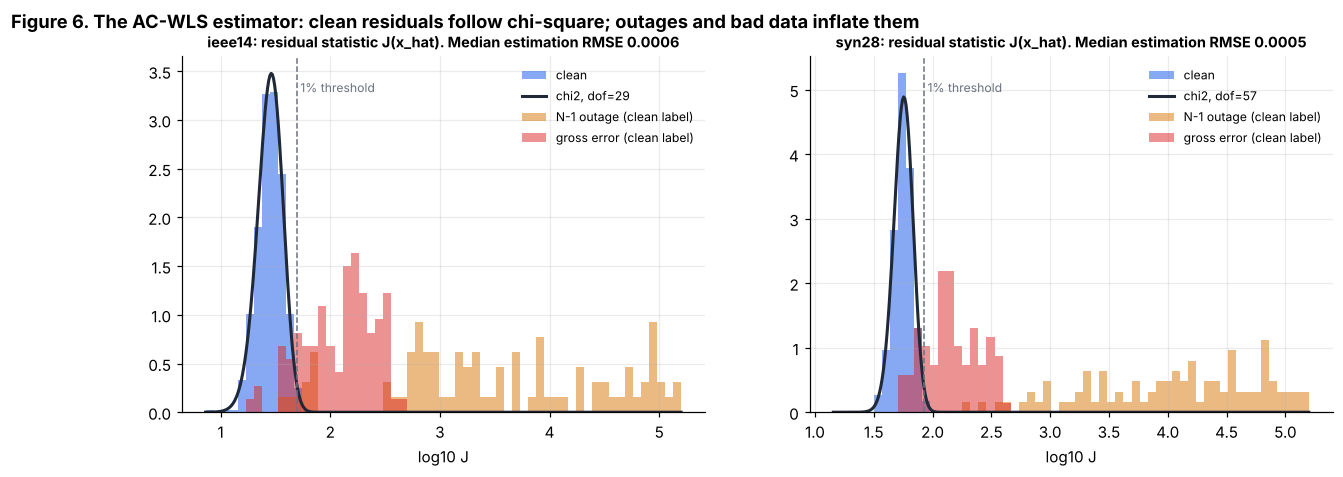

PosixPath('/tmp/w2/proj/figures/fig06_chi2_clean_vs_anomalies.png')

In [14]:
def chi2_study(name, n=500, seed=1):
    sim = SIMS[name]; rng = rng_for("chi2study", seed, *[ord(c) for c in name])
    rec = {"clean": [], "outage": [], "outlier": []}; err = []
    for kind, cnt in [("clean", n), ("outage", n // 5), ("outlier", n // 5)]:
        while len(rec[kind]) < cnt:
            s = new_sample(sim, rng, kind)
            if s is None: continue
            z, V, info = s
            xh, J, r = sim.estimate(z)
            rec[kind].append(J)
            if kind == "clean": err.append(np.sqrt(np.mean((xh - V_to_x(sim.M, V)) ** 2)))
    return rec, np.array(err), sim.mt["m"] - sim.mt["ns"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
for ax, name in zip(axes, ["ieee14", "syn28"]):
    rec, err, dof = chi2_study(name)
    lg = {k: np.log10(np.maximum(v, 1e-9)) for k, v in rec.items()}
    xs = np.linspace(np.log10(dof) - 0.6, 5.2, 400); xj = 10 ** xs
    bins = np.linspace(xs[0], 5.2, 60)
    ax.hist(lg["clean"], bins=bins, density=True, alpha=0.55, color=PAL["blue"], label="clean")
    ax.plot(xs, st.chi2.pdf(xj, dof) * xj * np.log(10), color=PAL["ink"], lw=2, label=f"chi2, dof={dof}")
    ax.hist(lg["outage"], bins=bins, density=True, alpha=0.5, color=PAL["amber"], label="N-1 outage (clean label)")
    ax.hist(lg["outlier"], bins=bins, density=True, alpha=0.5, color=PAL["red"], label="gross error (clean label)")
    thr = st.chi2.ppf(0.99, dof); ax.axvline(np.log10(thr), color=PAL["grey"], ls="--", lw=1); ax.text(np.log10(thr), ax.get_ylim()[1] * 0.9, " 1% threshold", fontsize=8, color=PAL["grey"])
    ax.set_title(f"{name}: residual statistic J(x_hat). Median estimation RMSE {np.median(err):.4f}", fontsize=9.5)
    ax.set_xlabel("log10 J"); ax.legend(fontsize=8, loc="upper right")
    print(f"{name}: clean J mean {np.mean(rec['clean']):.1f} (chi2 mean {dof}), "
          f"outage median {np.median(rec['outage']):.0f}, outlier median {np.median(rec['outlier']):.0f}")
fig.suptitle("Figure 6. The AC-WLS estimator: clean residuals follow chi-square; outages and bad data inflate them",
             x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig06_chi2_clean_vs_anomalies")

## Part 5. Natural variability and the hardness scale

Hardness needs $\Sigma$, the covariance of the *clean* state estimate. It is estimated per grid from a **calibration set** of natural operating conditions (regime switching, correlated and heavy-tailed loads, renewable ramps), with Ledoit–Wolf shrinkage so that it stays well-conditioned when the number of states approaches the number of samples. Hard negatives (outages, bad data) are excluded from this set, because they are not "natural variability" in the sense of the theory. They are abnormal events that the operator also needs to tell apart from attacks.

The same calibration set doubles as the **clean reference** that any deployed detector can legitimately use (an operator always has unlabeled clean history of their own grid).

In [15]:
class Calib:
    """Clean-reference statistics for one grid."""
    def __init__(self, sim, n, seed=0):
        rng = rng_for("calib", seed, *[ord(c) for c in sim.g.name])
        X, J = [], []
        while len(X) < n:
            s = new_sample(sim, rng, "clean")
            if s is None: continue
            z, V, _ = s; xh, j, r = sim.estimate(z); X.append(xh); J.append(j)
        self.X = np.array(X); self.J = np.array(J)
        self.mu = self.X.mean(0)
        # Plain sample covariance plus a tiny ridge. Ledoit-Wolf shrinkage was tried first and rejected: it shrinks toward a
        # multiple of the identity sized by the *largest* variances, which here inflates the variance of the tightest
        # directions by about 10x (see the design note below) and so under-states how detectable small shifts are.
        Xc = self.X - self.mu
        self.Sigma = (Xc.T @ Xc) / (len(Xc) - 1) + 1e-12 * np.eye(Xc.shape[1]); self.shrink = 0.0
        self.Sinv = np.linalg.inv(self.Sigma)
        self.L = np.linalg.cholesky(self.Sigma)
        w, V_ = np.linalg.eigh(self.Sigma); self.eigval, self.eigvec = w[::-1], V_[:, ::-1]
        self.sd = np.sqrt(np.diag(self.Sigma))
        self.ns = self.X.shape[1]
        self.dof = sim.mt["m"] - sim.mt["ns"]

    def delta(self, c):
        c = np.atleast_2d(c); return np.sqrt(np.einsum("ij,jk,ik->i", c, self.Sinv, c))

t0 = time.time()
CAL = {name: Calib(SIMS[name], SIZES["n_cal"]) for name in TRAIN_FAMILY + UNSEEN}
print(f"calibration sets built in {time.time()-t0:.0f}s")
print(f"{'grid':<10}{'states':>7}{'cond(Sigma)':>13}{'median sd(state)':>18}{'eff. rank':>11}")
for k, c_ in CAL.items():
    pe = c_.eigval / c_.eigval.sum(); er = float(np.exp(-np.sum(pe * np.log(pe + 1e-300))))
    print(f"{k:<10}{c_.ns:>7}{np.linalg.cond(c_.Sigma):>13.1e}{np.median(c_.sd):>18.4f}{er:>11.1f}")

calibration sets built in 35s
grid       states  cond(Sigma)  median sd(state)  eff. rank
ieee14         27      3.2e+06            0.0097        1.0
ieee14_v1      27      1.6e+07            0.0124        1.0
ieee14_v2      27      7.8e+06            0.0160        1.1
ieee30         59      4.5e+06            0.0067        1.9
ieee30_v1      59      6.9e+06            0.0069        1.7
syn20          39      1.1e+07            0.0233        1.5
syn28          55      3.6e+07            0.0188        1.3
syn36          71      1.6e+08            0.0116        1.2
ieee30_v2      59      2.8e+07            0.0082        2.1
syn24u         47      6.0e+07            0.0228        1.3
syn44u         87      2.8e+08            0.0212        1.2
ieee57        113      2.8e+08            0.0395        1.4


### 5.0 Design note: which covariance estimator?

The first version of this pipeline used Ledoit–Wolf shrinkage for $\Sigma$. A feature probe on the first detector run showed why that was wrong *for this problem*: a summary statistic measuring energy in the tightest directions alone reached AUROC 0.94 on attacks the oracle called "hard". The state estimate has a huge dynamic range (largest variance about $10^4$ times the smallest, because the system-wide load factor dominates while the tightest directions are limited only by estimation noise). Shrinkage toward a scaled identity set its floor by the *largest* variances, which was roughly ten times the true noise floor. Clean data then sat far inside the supposed spread in the tight directions, so small shifts there were much more detectable than their nominal hardness said. With $n_{\rm cal}\ge 8\,n_s$ calibration samples a plain sample covariance with a tiny ridge is accurate enough, and it is what the rest of the notebook uses. This kind of estimator choice is exactly what the oracle-referenced framing is meant to expose: a miscalibrated $\Sigma$ shows up as detectors that "beat the oracle".

### 5.1 What does natural variability look like? (Figure 7)

Panel A shows the Gaussian assumption is wrong in a way that matters: heavy-tailed load swings and regime switching make the state distribution non-Gaussian, so the oracle's closed form is an *approximation* here, and Part 10 measures how good an approximation it is. Panel B shows the spectrum of $\Sigma$, which is the "intrinsic dimension" the audit in Part 8 will use. A generator whose state cloud lives in a few dimensions is easy to attack-detect, because almost every direction is "impossible".

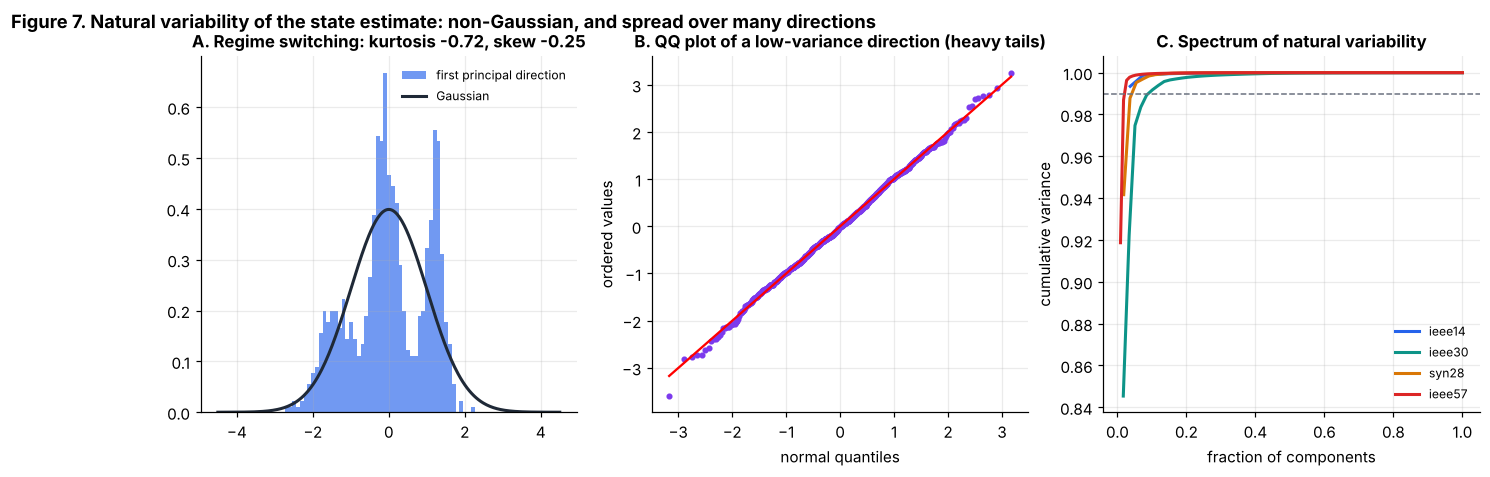

PosixPath('/tmp/w2/proj/figures/fig07_natural_variability.png')

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
c_ = CAL["ieee14"]; sdv = c_.eigvec[:, 0]
proj = (c_.X - c_.mu) @ sdv / np.sqrt(c_.eigval[0])
ax.hist(proj, bins=50, density=True, color=PAL["blue"], alpha=0.65, label="first principal direction")
xx = np.linspace(-4.5, 4.5, 300); ax.plot(xx, st.norm.pdf(xx), color=PAL["ink"], lw=2, label="Gaussian")
ax.set_title(f"A. Regime switching: kurtosis {st.kurtosis(proj):.2f}, skew {st.skew(proj):.2f}"); ax.legend(fontsize=8)
ax = axes[1]
last = (c_.X - c_.mu) @ c_.eigvec[:, -3] / np.sqrt(c_.eigval[-3])
st.probplot(last, dist="norm", plot=ax); ax.get_lines()[0].set_color(PAL["purple"]); ax.get_lines()[0].set_markersize(3)
ax.set_title("B. QQ plot of a low-variance direction (heavy tails)"); ax.set_xlabel("normal quantiles"); ax.set_ylabel("ordered values")
ax = axes[2]
for name, col in [("ieee14", PAL["blue"]), ("ieee30", PAL["teal"]), ("syn28", PAL["amber"]), ("ieee57", PAL["red"])]:
    ev = CAL[name].eigval; ax.plot(np.arange(1, len(ev) + 1) / len(ev), np.cumsum(ev) / ev.sum(), color=col, label=name, lw=2)
ax.axhline(0.99, color=PAL["grey"], ls="--", lw=1); ax.set_xlabel("fraction of components"); ax.set_ylabel("cumulative variance")
ax.set_title("C. Spectrum of natural variability"); ax.legend(fontsize=8)
fig.suptitle("Figure 7. Natural variability of the state estimate: non-Gaussian, and spread over many directions", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig07_natural_variability")

## Part 6. Attack library

An attack is specified by a state shift $c$ and an attacker model. The attacker never touches the state directly; they add a vector $a$ to the meter readings, and we then measure the *realized* shift $c_{\rm eff}=\hat x_{\rm attacked}-\hat x_{\rm clean}$ of the estimator on the same noise realization. Every hardness reported below uses this realized shift, not the nominal one.

| Attacker model | How $a$ is built | What it knows |
|---|---|---|
| `linear` | $a=H_{\rm nom}c$ with the nominal-point Jacobian | the topology and nominal operating point |
| `ac` | $a=h(\hat x_0+c)-h(\hat x_0)$ with $\hat x_0$ the attacker's own estimate | the full AC measurement model and live readings |
| `partial` | $a=\tilde H c$, $\tilde H$ = nominal Jacobian with 10% random error | an imperfect model |

| Direction of $c$ | Description |
|---|---|
| `sparse` | 1 to 4 compromised buses (angle, and voltage with probability 0.5) |
| `dense` | all states |
| `lfc` | $c\propto\Sigma h$, the worst-case direction for the fake tie-line flow $h^\top c$ (Part 12) |

The *size* of $c$ is set in one of two ways. **Hardness-stratified** sampling draws $\delta$ log-uniformly on $[0.25,6]$ and rescales $c$ to exactly that hardness (used for every test set, so that every hardness bin is populated). **Uniform-magnitude** sampling draws a state-unit magnitude $m\sim U(0.1,3)$ standard deviations and does not control $\delta$; it imitates how many published generators scale their attacks, and it is the comparison arm for method A in Part 13.

In [17]:
def tie_sensitivity(sim):
    """h such that fake tie-line flow (area0 -> area1, pu) = h @ c, from the nominal Jacobian."""
    g, M = sim.g, sim.M
    Hf = meas_jac(M, sim.V0)
    h = np.zeros(2 * g.n - 1)
    for k in g.meta["tie"]:
        sgn = 1.0 if g.area[g.f[k]] == 0 else -1.0
        h += sgn * Hf[3 * g.n + k]
    return h

for name, sim in SIMS.items():
    sim.h_tie = tie_sensitivity(sim)
    sim.H_nom = meas_jac(sim.M, sim.V0)[sim.mt["sel"]]

def make_direction(sim, cal, rng, kind):
    ns = cal.ns; n = sim.g.n
    if kind == "dense":
        u = rng.normal(size=ns)
    elif kind == "lfc":
        u = cal.Sigma @ sim.h_tie * rng.choice([-1, 1])      # exact worst-case direction for the fake tie flow
    else:   # sparse
        k = int(rng.integers(1, 5)); buses = rng.choice(n, size=min(k, n), replace=False)
        idx = []
        for b_ in buses:
            if b_ != sim.M.ref: idx.append(int(np.where(sim.M.nonref == b_)[0][0]))
            if rng.random() < 0.5: idx.append(n - 1 + int(b_))
        if not idx: idx = [n - 1 + int(buses[0])]
        u = np.zeros(ns); u[idx] = rng.normal(size=len(idx))
    return u

def set_size(cal, u, rng, mode, delta_range=(0.25, 6.0)):
    if mode == "strat":
        d = np.exp(rng.uniform(np.log(delta_range[0]), np.log(delta_range[1])))
        return u * d / cal.delta(u)[0]
    # uniform magnitude in state units (standard deviations), direction not rescaled for hardness
    m = rng.uniform(0.1, 3.0)
    uu = u / (np.linalg.norm(u / cal.sd) + 1e-12)
    return m * uu

def apply_attack(sim, cal, rng, z, c, model):
    """Return attacked measurement vector for attacker model in {linear, ac, partial}."""
    if model == "ac":
        xh0, _, _ = sim.estimate(z)
        a = (meas_h(sim.M, x_to_V(sim.M, xh0 + c)) - meas_h(sim.M, x_to_V(sim.M, xh0)))[sim.mt["sel"]]
    elif model == "partial":
        Ht = sim.H_nom * (1 + 0.10 * rng.normal(size=sim.H_nom.shape)); a = Ht @ c
    else:
        a = sim.H_nom @ c
    return z + a

DIR_P = dict(sparse=0.60, dense=0.20, lfc=0.20)
MODEL_P = dict(linear=0.45, ac=0.40, partial=0.15)

def attacked_sample(sim, cal, rng, size_mode="strat", model=None, kind=None):
    for _ in range(10):
        s = new_sample(sim, rng, "clean")
        if s is None: continue
        z, V, _ = s
        kind_ = kind or rng.choice(list(DIR_P), p=list(DIR_P.values()))
        model_ = model or rng.choice(list(MODEL_P), p=list(MODEL_P.values()))
        u = make_direction(sim, cal, rng, kind_)
        c = set_size(cal, u, rng, size_mode)
        za = apply_attack(sim, cal, rng, z, c, model_)
        xh0, J0, _ = sim.estimate(z); xh1, J1, r1 = sim.estimate(za)
        c_eff = xh1 - xh0
        return dict(x=xh1, J=J1, rmax=float(np.max(np.abs(r1) / sim.mt["sigma"])), shift=c_eff, dirkind=kind_, model=model_,
                    dJ=J1 - J0, x_clean=xh0)
    return None

### 6.1 Do the attacks do what the theory says? (Figure 8)

Four claims are checked on IEEE 14 with 300 attacks per attacker model.

1. A **linear** null-space attack changes the AC residual only slightly (second-order effect of the nonlinearity), so the chi-square test misses it unless the shift is large.
2. An **AC-consistent** attack leaves the residual essentially unchanged at any size.
3. The realized shift $c_{\rm eff}$ matches the requested $c$ (the attack lands where it was aimed).
4. **Uniform-magnitude** sampling gives a very different hardness distribution from **hardness-stratified** sampling.

chi2 dof=29, 1% threshold=49.6

  model   n  median_J  alarm_rate_1pct  alarm_rate_delta_lt2  alarm_rate_delta_gt4
 linear 300    29.384            0.070                 0.012                 0.388
     ac 300    28.686            0.013                 0.010                 0.062
partial 300    32.003            0.233                 0.026                 0.647


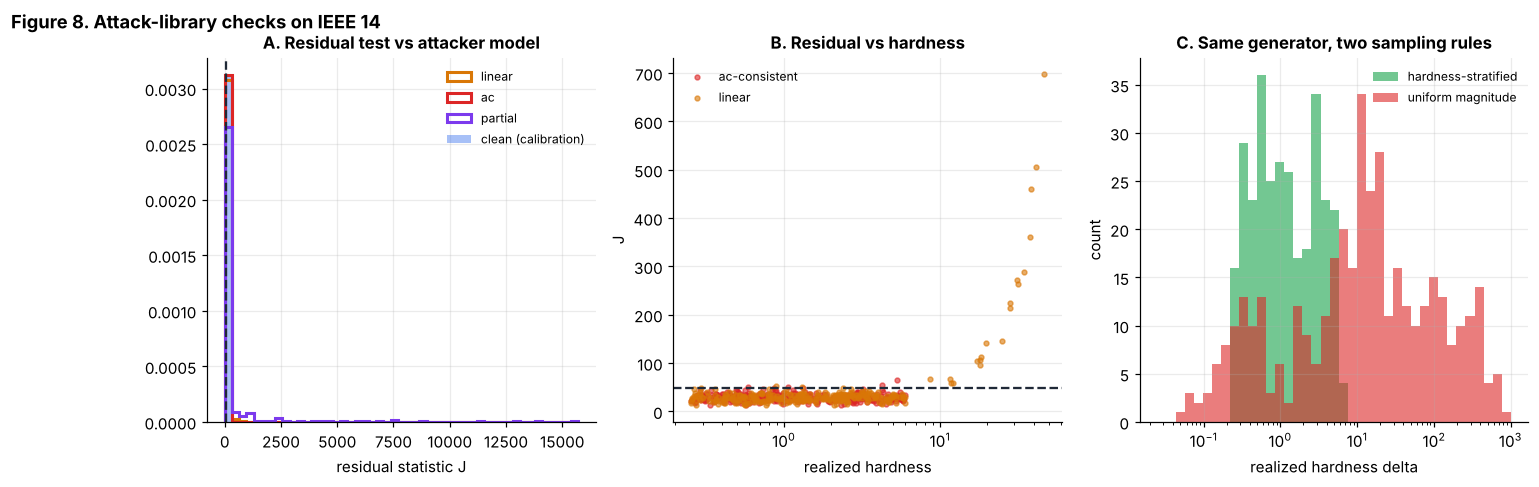


uniform-magnitude hardness: median 12.08, share below 2: 23.75%, share above 6: 65.25%


In [18]:
rng = rng_for("attack_check"); sim, cal = SIMS["ieee14"], CAL["ieee14"]
recs = {m: [] for m in ["linear", "ac", "partial"]}
for m in recs:
    for _ in range(300):
        a_ = attacked_sample(sim, cal, rng, "strat", model=m)
        if a_ is None: continue
        a_["delta_eff"] = float(cal.delta(a_["shift"])[0]); recs[m].append(a_)
thr = st.chi2.ppf(0.99, cal.dof)
rows = []
for m, lst in recs.items():
    dJ = np.array([a["J"] for a in lst]); dl = np.array([a["delta_eff"] for a in lst])
    rows.append(dict(model=m, n=len(lst), median_J=np.median(dJ), alarm_rate_1pct=np.mean(dJ > thr),
                     alarm_rate_delta_lt2=np.mean(dJ[dl < 2] > thr), alarm_rate_delta_gt4=np.mean(dJ[dl > 4] > thr)))
print(f"chi2 dof={cal.dof}, 1% threshold={thr:.1f}\n")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# uniform-magnitude hardness distribution
mag = [attacked_sample(sim, cal, rng, "mag") for _ in range(400)]
d_mag = np.array([cal.delta(a["shift"])[0] for a in mag if a is not None])

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))
ax = axes[0]
bins = np.linspace(0, np.percentile(np.r_[[a["J"] for m in recs for a in recs[m]]], 98), 50)
for m, col in zip(recs, [PAL["amber"], PAL["red"], PAL["purple"]]):
    ax.hist([a["J"] for a in recs[m]], bins=bins, density=True, histtype="step", lw=2, color=col, label=m)
ax.hist(cal.J, bins=bins, density=True, alpha=0.4, color=PAL["blue"], label="clean (calibration)")
ax.axvline(thr, color=PAL["ink"], ls="--"); ax.set_xlabel("residual statistic J"); ax.set_title("A. Residual test vs attacker model"); ax.legend(fontsize=8)
ax = axes[1]
req = np.array([cal.delta(a["shift"])[0] for a in recs["ac"]])
ax.scatter(req, [a["J"] for a in recs["ac"]], s=10, color=PAL["red"], alpha=0.6, label="ac-consistent")
ax.scatter(np.array([a["delta_eff"] for a in recs["linear"]]), [a["J"] for a in recs["linear"]], s=10, color=PAL["amber"], alpha=0.6, label="linear")
ax.axhline(thr, color=PAL["ink"], ls="--"); ax.set_xscale("log"); ax.set_xlabel("realized hardness"); ax.set_ylabel("J"); ax.set_title("B. Residual vs hardness"); ax.legend(fontsize=8)
ax = axes[2]
lb = np.logspace(-1.6, 3, 40)
ax.hist(np.array([a["delta_eff"] for a in recs["ac"]]), bins=lb, alpha=0.6, color=PAL["green"], label="hardness-stratified")
ax.hist(d_mag, bins=lb, alpha=0.6, color=PAL["red"], label="uniform magnitude")
ax.set_xscale("log"); ax.set_xlabel("realized hardness delta"); ax.set_ylabel("count"); ax.set_title("C. Same generator, two sampling rules"); ax.legend(fontsize=8)
fig.suptitle("Figure 8. Attack-library checks on IEEE 14", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig08_attack_checks")
print(f"\nuniform-magnitude hardness: median {np.median(d_mag):.2f}, share below 2: {np.mean(d_mag<2):.2%}, share above 6: {np.mean(d_mag>6):.2%}")

### 6.2 Anatomy of one attack (Figure 9)

A concrete attack on IEEE 14, shown in all three spaces the study works in: the state shift (what the attacker aims at), the meter changes (what the attacker has to forge), and the estimated state (what the operator sees). Note panel A: a hardness-3 attack on a single bus angle is a *tiny* fraction of that angle's marginal standard deviation. Hardness is not marginal size. Natural variability is strongly correlated across buses, so an isolated angle shift is far outside the correlation pattern even when it is small in absolute terms.

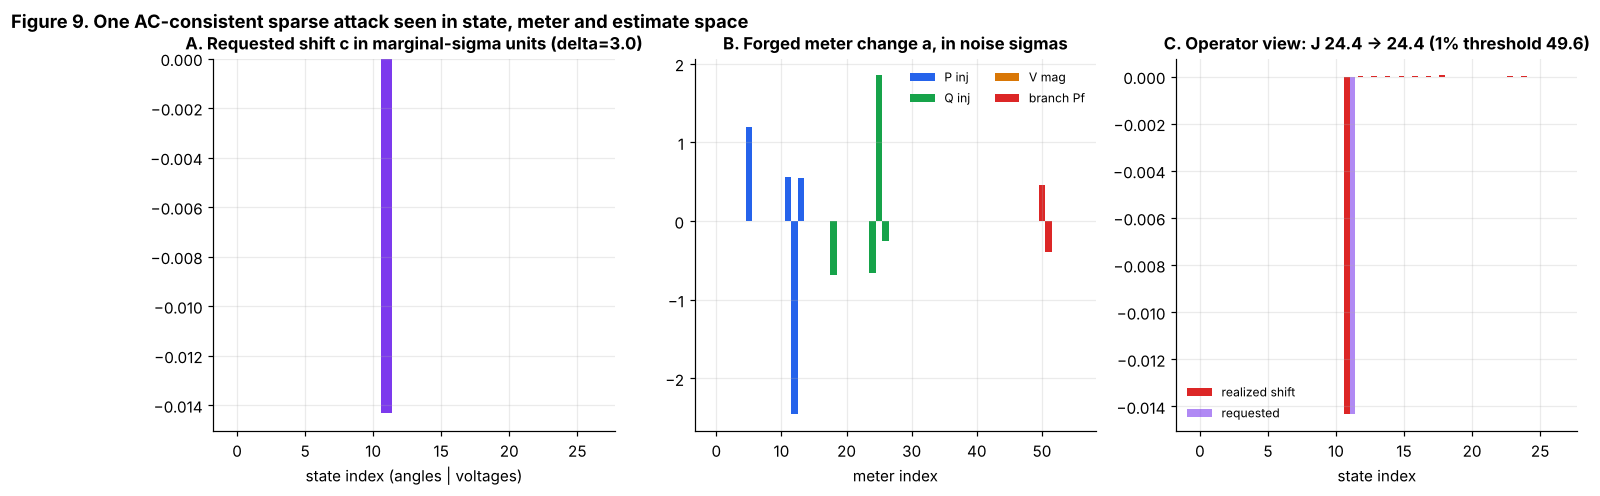

PosixPath('/tmp/w2/proj/figures/fig09_attack_anatomy.png')

In [19]:
rng = rng_for("anatomy"); sim, cal = SIMS["ieee14"], CAL["ieee14"]
while True:
    s = new_sample(sim, rng, "clean")
    if s is None: continue
    z, V, _ = s
    u = make_direction(sim, cal, rng, "sparse"); c = u * 3.0 / cal.delta(u)[0]
    za = apply_attack(sim, cal, rng, z, c, "ac")
    break
xh0, J0, r0 = sim.estimate(z); xh1, J1, r1 = sim.estimate(za)
n = sim.g.n
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]; lab = [f"th{b}" for b in sim.M.nonref] + [f"V{b}" for b in range(n)]
ax.bar(np.arange(len(c)), c / cal.sd, color=[PAL["purple"] if i < n - 1 else PAL["teal"] for i in range(len(c))])
ax.set_title(f"A. Requested shift c in marginal-sigma units (delta={cal.delta(c)[0]:.1f})"); ax.set_xlabel("state index (angles | voltages)")
ax = axes[1]; a_vec = za - z; typ = sim.mt["types"]
for t_, nm, col in zip(range(4), ["P inj", "Q inj", "V mag", "branch Pf"], [PAL["blue"], PAL["green"], PAL["amber"], PAL["red"]]):
    idx = np.where(typ == t_)[0]; ax.bar(idx, a_vec[idx] / sim.mt["sigma"][idx], color=col, label=nm, width=1.0)
ax.set_title("B. Forged meter change a, in noise sigmas"); ax.set_xlabel("meter index"); ax.legend(fontsize=8, ncol=2)
ax = axes[2]
ax.bar(np.arange(len(c)) - 0.2, (xh1 - xh0) / cal.sd, width=0.4, color=PAL["red"], label="realized shift")
ax.bar(np.arange(len(c)) + 0.2, c / cal.sd, width=0.4, color=PAL["purple"], alpha=0.6, label="requested")
ax.set_title(f"C. Operator view: J {J0:.1f} -> {J1:.1f} (1% threshold {thr:.1f})"); ax.legend(fontsize=8); ax.set_xlabel("state index")
fig.suptitle("Figure 9. One AC-consistent sparse attack seen in state, meter and estimate space", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig09_attack_anatomy")

## Part 7. Dataset assembly

Each grid gets five sets, all generated from separately named random streams:

| Set | Content | Used for |
|---|---|---|
| `cal` | natural clean windows (Part 5) | $\mu,\Sigma$, clean reference, one-class training |
| `train` | half clean (including 5% outages, 5% bad data), half hardness-stratified attacks | supervised training |
| `train_mag` | the same number of attacks sampled by uniform magnitude, to pair with the clean half of `train` | method A comparison |
| `train_extra` (two study grids only) | a second block of `train`, to give training pools of 1,800 and 3,600 | label-budget curves |
| `test` | half clean (with hard negatives), half hardness-stratified attacks | everything that is reported |

Each row stores the state estimate $\hat x$, the residual statistic $J$, the largest normalised residual, the label, the kind (`natural`, `outage`, `outlier`, `attack`), and for attacks the realised shift $c_{\rm eff}$, realised hardness, attacker model, direction kind, and fake tie-line flow $h^\top c_{\rm eff}$. The shift vectors are *privileged information*: detectors never see them, but the oracle and the distillation teacher do.

Generation is cached in `data/` so a rerun skips this step unless `BUDGET` changes.

In [20]:
def gen_clean_block(sim, cal, rng, n, hn=(0.05, 0.05)):
    kinds = rng.choice(["natural", "outage", "outlier"], size=n, p=[1 - sum(hn), hn[0], hn[1]])
    X, J, R = [], [], []
    for k in kinds:
        s = None
        while s is None: s = new_sample(sim, rng, {"natural": "clean"}.get(k, k))
        z, V, _ = s; xh, j, r = sim.estimate(z)
        X.append(xh); J.append(j); R.append(np.max(np.abs(r) / sim.mt["sigma"]))
    return dict(x=np.array(X), J=np.array(J), rmax=np.array(R), label=np.zeros(n, int), kind=kinds,
                delta=np.full(n, np.nan), shift=np.zeros((n, cal.ns)), flow=np.zeros(n),
                model=np.array([""] * n), dirkind=np.array([""] * n))

def gen_attack_block(sim, cal, rng, n, size_mode):
    rec = []
    while len(rec) < n:
        a = attacked_sample(sim, cal, rng, size_mode)
        if a is not None: rec.append(a)
    sh = np.array([a["shift"] for a in rec])
    return dict(x=np.array([a["x"] for a in rec]), J=np.array([a["J"] for a in rec]), rmax=np.array([a["rmax"] for a in rec]),
                label=np.ones(n, int), kind=np.array(["attack"] * n), delta=cal.delta(sh), shift=sh, flow=sh @ sim.h_tie,
                model=np.array([a["model"] for a in rec]), dirkind=np.array([a["dirkind"] for a in rec]))

def concat_blocks(*blocks):
    return {k: np.concatenate([b[k] for b in blocks]) for k in blocks[0]}

STUDY_GRIDS = ["ieee14", "syn28"]     # grids used for the in-grid oracle-gap study (Part 10)

def build_grid_data(name):
    sim, cal = SIMS[name], CAL[name]; n_tr, n_te = SIZES["n_train"], SIZES["n_test"]
    d = {}
    for role, size in [("train", n_tr), ("test", n_te)] + ([("train_extra", n_tr)] if name in STUDY_GRIDS else []):
        rng = rng_for("set", ord(role[0]) + len(role), *[ord(c) for c in name])
        d[role] = concat_blocks(gen_clean_block(sim, cal, rng, size // 2), gen_attack_block(sim, cal, rng, size // 2, "strat"))
    rng = rng_for("set_mag", *[ord(c) for c in name])
    d["train_mag"] = gen_attack_block(sim, cal, rng, n_tr // 2, "mag")
    return d

cache = DATA / f"datasets_{BUDGET}.pkl"
if cache.exists():
    with open(cache, "rb") as fh: DS = pickle.load(fh)
    print("loaded cached datasets:", cache.name)
else:
    DS = {}; t0 = time.time()
    for name in TRAIN_FAMILY + UNSEEN:
        t1 = time.time(); DS[name] = build_grid_data(name)
        print(f"{name:<10} built in {time.time()-t1:5.1f}s", flush=True)
    with open(cache, "wb") as fh: pickle.dump(DS, fh)
    print(f"total {time.time()-t0:.0f}s, cached to {cache.name}")

rows = []
for name, d in DS.items():
    te = d["test"]
    rows.append(dict(grid=name, role="UNSEEN" if name in UNSEEN else "family", states=CAL[name].ns, n_train=len(d["train"]["label"]),
                     n_test=len(te["label"]), attacks=int(te["label"].sum()),
                     outage=int((te["kind"] == "outage").sum()), outlier=int((te["kind"] == "outlier").sum()),
                     delta_med=float(np.nanmedian(te["delta"]))))
print(pd.DataFrame(rows).round(2).to_string(index=False))

loaded cached datasets: datasets_full.pkl
     grid   role  states  n_train  n_test  attacks  outage  outlier  delta_med
   ieee14 family      27     1800    1800      900      50       39       1.51
ieee14_v1 family      27     1800    1800      900      43       53       1.64
ieee14_v2 family      27     1800    1800      900      34       53       1.48
   ieee30 family      59     1800    1800      900      50       55       1.32
ieee30_v1 family      59     1800    1800      900      34       41       1.24
    syn20 family      39     1800    1800      900      47       47       1.43
    syn28 family      55     1800    1800      900      48       32       1.33
    syn36 family      71     1800    1800      900      54       47       1.50
ieee30_v2 UNSEEN      59     1800    1800      900      47       45       1.37
   syn24u UNSEEN      47     1800    1800      900      40       53       1.40
   syn44u UNSEEN      87     1800    1800      900      43       36       1.43
   ieee57 

### 7.1 Dataset overview (Figure 10)

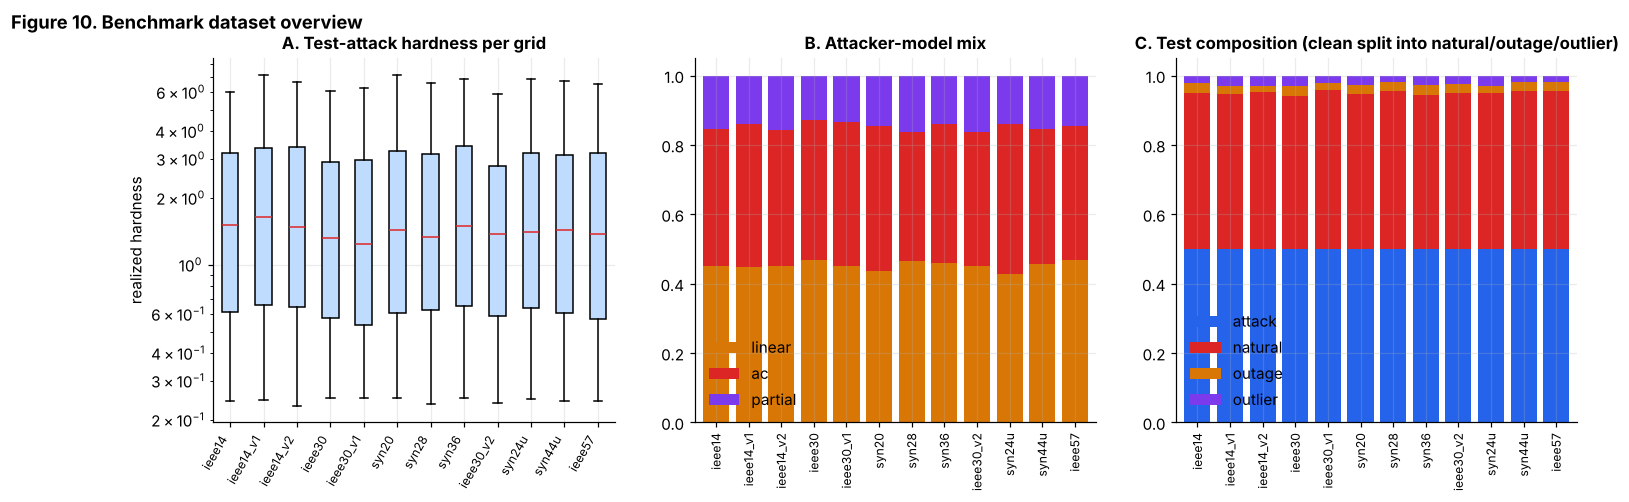

PosixPath('/tmp/w2/proj/figures/fig10_dataset_overview.png')

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
names = list(DS.keys())
dl = [DS[k]["test"]["delta"][DS[k]["test"]["label"] == 1] for k in names]
ax.boxplot(dl, vert=True, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#bfdbfe"), medianprops=dict(color=PAL["red"]))
ax.set_xticks(range(1, len(names) + 1)); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8); ax.set_yscale("log")
ax.set_ylabel("realized hardness"); ax.set_title("A. Test-attack hardness per grid")
ax = axes[1]
mix = pd.DataFrame([{"grid": k, **pd.Series(DS[k]["test"]["model"][DS[k]["test"]["label"] == 1]).value_counts(normalize=True).to_dict()} for k in names]).set_index("grid")
mix.plot(kind="bar", stacked=True, ax=ax, color=[PAL["amber"], PAL["red"], PAL["purple"]], width=0.8, legend=True)
ax.set_title("B. Attacker-model mix"); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8)
ax = axes[2]
kinds = pd.DataFrame([{"grid": k, **pd.Series(DS[k]["test"]["kind"]).value_counts().to_dict()} for k in names]).set_index("grid")
(kinds / kinds.sum(1).values[:, None]).plot(kind="bar", stacked=True, ax=ax, color=[PAL["blue"], PAL["red"], PAL["amber"], PAL["purple"]], width=0.8)
ax.set_title("C. Test composition (clean split into natural/outage/outlier)"); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Figure 10. Benchmark dataset overview", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig10_dataset_overview")

## Part 8. Detectors, features and the evaluation harness

### 8.1 Two input views

* **In-grid view.** The whitened state estimate $w=L^{-1}(\hat x-\mu)$ (with $\Sigma=LL^\top$ from the grid's own clean calibration set) plus two residual features. This view has one dimension per state, so a model is tied to one grid. It is the fair arena for the oracle-gap study.
* **Grid-agnostic view.** A fixed-length vector of twelve summary statistics (total energy $T^2$, energy in the high-, mid- and low-variance parts of the spectrum, the four largest whitened components, kurtosis, energy in the three smallest components, the residual statistic and the largest normalised residual). Every statistic is computed against the *target grid's own clean reference*, which an operator always has. This view lets one model run on a grid it was never trained on, so it is the one used in Part 11.

Both views use only information a deployed detector has: $\hat x$, $J(\hat x)$ and the residuals, plus clean history. The attack shift $c$ is never an input.

In [22]:
def whiten(cal, X):
    return np.linalg.solve(cal.L, (X - cal.mu).T).T

def spectral_energy(cal, X):
    """Whitened components along the eigenvectors of Sigma: p_j = v_j'(x-mu)/sqrt(lambda_j)."""
    return ((X - cal.mu) @ cal.eigvec) / np.sqrt(cal.eigval)

def summary_features(cal, d):
    p = spectral_energy(cal, d["x"]); ns = p.shape[1]; e = p ** 2
    g1, g2 = max(1, ns // 4), max(1, ns // 4)
    def z(sumv, k): return (sumv - k) / np.sqrt(2 * k)
    T2 = e.sum(1)
    top = z(e[:, :g1].sum(1), g1); bot = z(e[:, -g2:].sum(1), g2); mid = z(e[:, g1:ns - g2].sum(1), max(1, ns - g1 - g2))
    last3 = z(e[:, -3:].sum(1), 3)
    ap = np.sort(np.abs(p), 1)[:, ::-1][:, :4]
    kurt = st.kurtosis(p, axis=1)
    zJ = (d["J"] - cal.dof) / np.sqrt(2 * cal.dof)
    return np.column_stack([z(T2, ns), top, mid, bot, last3, ap, kurt, zJ, np.log(d["rmax"] + 1e-9)])

def indomain_features(cal, d):
    zJ = (d["J"] - cal.dof) / np.sqrt(2 * cal.dof)
    return np.column_stack([whiten(cal, d["x"]), zJ, np.log(d["rmax"] + 1e-9)])

def subsample_balanced(d, n, rng):
    """n rows, half clean and half attacked, drawn without replacement from a pooled set."""
    ic, ia = np.where(d["label"] == 0)[0], np.where(d["label"] == 1)[0]
    pick = np.r_[rng.choice(ic, n // 2, replace=False), rng.choice(ia, n // 2, replace=False)]
    return {k: v[pick] for k, v in d.items()}

def drop_hard_negatives(d):
    keep = ~np.isin(d["kind"], ["outage", "outlier"])
    return {k: v[keep] for k, v in d.items()}

### 8.2 Detector zoo

| Detector | Type | Uses labels? | Input |
|---|---|---|---|
| `chi2` | classical bad-data test | no | $J(\hat x)$ |
| `hotelling` | clean-only generalized test | no | $T^2$ of $\hat x$ |
| `pca_recon` | clean-only subspace test | no | reconstruction error outside the top PCs (standardised state) |
| `iforest` | clean-only isolation forest | no | whitened $\hat x$ |
| `logreg` | linear supervised | yes | in-grid view |
| `gbdt` | gradient-boosted trees | yes | in-grid view |
| `mlp` | multilayer perceptron | yes | in-grid view |
| `gbdt_sum`, `mlp_sum`, `logreg_sum` | supervised, grid-agnostic | yes | summary view |
| `oracle` | *privileged*: knows the attack shift $c$ | n/a | $\hat x$ and $c$ |

All supervised detectors get the **same tuning budget**: `rs_trials` random-search trials scored by validation AUROC on a 30% split of the training data, then refit on the full training set with the winning configuration. This is deliberately modest. The point of equal tuning is that no arm gets an advantage, not that any arm is maximally tuned.

In [23]:
class Detector:
    name = "base"; supervised = False
    def fit(self, cal, train, seed=0): return self
    def score(self, cal, d): raise NotImplementedError

class Chi2(Detector):
    name = "chi2"
    def score(self, cal, d): return d["J"]

class Hotelling(Detector):
    name = "hotelling"
    def score(self, cal, d): return (whiten(cal, d["x"]) ** 2).sum(1)

class PCARecon(Detector):
    name = "pca_recon"
    def fit(self, cal, train=None, seed=0):
        self.p = PCA(n_components=0.95, svd_solver="full").fit((cal.X - cal.mu) / cal.sd); return self
    def score(self, cal, d):
        Z = (d["x"] - cal.mu) / cal.sd
        return ((Z - self.p.inverse_transform(self.p.transform(Z))) ** 2).sum(1)

class IForest(Detector):
    name = "iforest"
    def fit(self, cal, train=None, seed=0):
        self.m = IsolationForest(n_estimators=200, max_samples=256, random_state=seed).fit(whiten(cal, cal.X)); return self
    def score(self, cal, d): return -self.m.score_samples(whiten(cal, d["x"]))

def _logU(rng, lo, hi): return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))

class Supervised(Detector):
    supervised = True
    view = "in"
    def feats(self, cal, d): return indomain_features(cal, d) if self.view == "in" else summary_features(cal, d)
    def make(self, rng): raise NotImplementedError
    def fit(self, cal, train, seed=0, trials=None):
        return self._fit_xy(self.feats(cal, train), train["label"], seed, trials)
    def _fit_xy(self, X, y, seed=0, trials=None):
        """Random-search tuning on a 30% validation split, then refit on everything with the winner."""
        trials = trials or SIZES["rs_trials"]; rng = np.random.default_rng(seed)
        if getattr(self, "scale", False): self.sc = StandardScaler().fit(X); X = self.sc.transform(X)
        idx = rng.permutation(len(y)); nv = int(0.3 * len(y)); va, tr = idx[:nv], idx[nv:]
        best, best_auc = None, -1
        for t in range(trials):
            m = self.make(rng, t)
            try:
                m.fit(X[tr], y[tr]); a = roc_auc_score(y[va], self._p(m, X[va]))
            except Exception:
                a = -1
            if a > best_auc: best, best_auc = m, a
        self.model = best; self.val_auc = best_auc
        self.model.fit(X, y)            # refit on everything with the winning configuration
        return self
    def _p(self, m, X): return m.predict_proba(X)[:, 1]
    def score(self, cal, d):
        X = self.feats(cal, d)
        if hasattr(self, "sc"): X = self.sc.transform(X)
        return self._p(self.model, X)

class LogReg(Supervised):
    name = "logreg"; scale = True
    def make(self, rng, t): return LogisticRegression(C=_logU(rng, 1e-3, 10), max_iter=400)

class GBDT(Supervised):
    name = "gbdt"
    def make(self, rng, t):
        return HistGradientBoostingClassifier(learning_rate=_logU(rng, 0.03, 0.3), max_leaf_nodes=int(rng.choice([15, 31, 63])),
                                              l2_regularization=_logU(rng, 1e-3, 10), max_iter=250, early_stopping=True,
                                              validation_fraction=0.15, n_iter_no_change=15, random_state=int(rng.integers(1e6)))

class MLP(Supervised):
    name = "mlp"; scale = True
    def make(self, rng, t):
        h = [(64,), (128, 64), (256, 128)][int(rng.integers(3))]
        return MLPClassifier(hidden_layer_sizes=h, alpha=_logU(rng, 1e-5, 1e-2), learning_rate_init=_logU(rng, 1e-4, 3e-3),
                             max_iter=250, early_stopping=True, n_iter_no_change=12, random_state=int(rng.integers(1e6)))

class LogRegSum(LogReg): name = "logreg_sum"; view = "sum"
class GBDTSum(GBDT):     name = "gbdt_sum";   view = "sum"
class MLPSum(MLP):       name = "mlp_sum";    view = "sum"

### 8.3 The oracle, per attack

For an attacked window $i$ with realized shift $c_i$, the oracle score is $s_i=c_i^\top\Sigma^{-1}(\hat x_i-\mu)$. To place it on a ROC it must be compared with clean windows *scored in the same direction*: $s_{ij}=c_i^\top\Sigma^{-1}(\hat x_j-\mu)$ for each clean window $j$. The per-attack AUROC is the fraction of clean windows whose score falls below $s_i$. Averaging over the attacks in a hardness bin gives the bin's oracle AUROC, and the closed form $\Phi(\delta/\sqrt2)$ is the Gaussian prediction for it. Where the two differ, the Gaussian assumption is failing, and the *empirical* oracle (not the formula) is the honest yardstick.

The oracle sees the true shift but *not* the labels' source (it scores clean windows too), so it is an upper reference for a detector that knows the attack direction.

In [24]:
def oracle_scores(cal, d_test):
    """Return (per-attack AUROC array, attack deltas, attack flow) using the realized shifts."""
    ia = np.where(d_test["label"] == 1)[0]; ic = np.where(d_test["label"] == 0)[0]
    C = d_test["shift"][ia]; Xa = d_test["x"][ia] - cal.mu; Xc = d_test["x"][ic] - cal.mu
    CS = C @ cal.Sinv                                    # (na, ns)
    s_att = np.einsum("ij,ij->i", CS, Xa)                # (na,)
    s_clean = CS @ Xc.T                                  # (na, nc)
    auc = (s_att[:, None] > s_clean).mean(1) + 0.5 * (s_att[:, None] == s_clean).mean(1)
    return auc, d_test["delta"][ia], s_att

BIN_EDGES = np.array([0.25, 0.5, 1.0, 2.0, 4.0, 6.5])
BIN_NAMES = [f"{BIN_EDGES[i]:g}-{BIN_EDGES[i+1]:g}" for i in range(len(BIN_EDGES) - 1)]

def auc_by_bin(score_test, d_test, edges=BIN_EDGES):
    """AUROC of each hardness bin's attacks versus ALL clean test windows."""
    ia = np.where(d_test["label"] == 1)[0]; ic = np.where(d_test["label"] == 0)[0]
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = ia[(d_test["delta"][ia] >= lo) & (d_test["delta"][ia] < hi + (1e-9 if hi == edges[-1] else 0))]
        if len(sel) < 5: out.append(np.nan); continue
        out.append(roc_auc_score(np.r_[np.zeros(len(ic)), np.ones(len(sel))], np.r_[score_test[ic], score_test[sel]]))
    return np.array(out)

def oracle_by_bin(cal, d_test, edges=BIN_EDGES):
    auc, dl, _ = oracle_scores(cal, d_test)
    return np.array([auc[(dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))].mean()
                     if np.any((dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))) else np.nan
                     for lo, hi in zip(edges[:-1], edges[1:])])

def overall_auc(score_test, d_test): return roc_auc_score(d_test["label"], score_test)

def formula_by_bin(d_test, edges=BIN_EDGES):
    dl = d_test["delta"][d_test["label"] == 1]
    return np.array([np.nanmean(oracle_auc(dl[(dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))])) if np.any((dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))) else np.nan
                     for lo, hi in zip(edges[:-1], edges[1:])])

### 8.4 First look: all detectors on IEEE 14 (Figure 11)

One grid, one seed, the full training set. This cell is a smoke test of the harness and the first look at where the detectors sit relative to the oracle; the controlled study with seeds and label budgets is Part 10.

IEEE 14, 1800 training windows, 6s
                           0.25-0.5  0.5-1    1-2    2-4  4-6.5  overall
chi2                          0.458  0.466  0.463  0.463  0.518    0.498
hotelling                     0.467  0.476  0.528  0.658  0.839    0.599
pca_recon                     0.477  0.462  0.485  0.503  0.545    0.515
iforest                       0.459  0.471  0.512  0.642  0.786    0.583
logreg                        0.560  0.564  0.540  0.508  0.473    0.532
gbdt                          0.542  0.543  0.558  0.674  0.780    0.620
mlp                           0.534  0.539  0.562  0.622  0.715    0.601
ORACLE (empirical)            0.615  0.680  0.824  0.958  0.989      NaN
ORACLE (Gaussian formula)     0.606  0.698  0.843  0.971  0.999      NaN


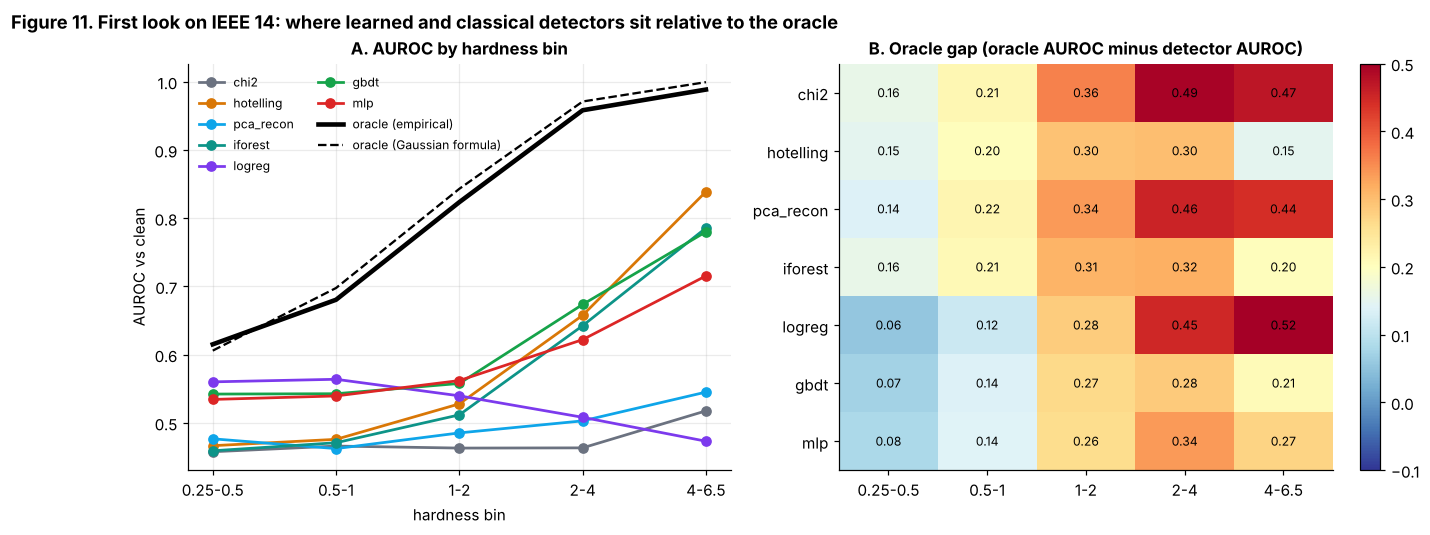

PosixPath('/tmp/w2/proj/figures/fig11_first_look_ieee14.png')

In [25]:
def run_detectors(name, train, test, cal, dets, seed=0):
    res = {}
    for D in dets:
        t0 = time.time(); det = D()
        det.fit(cal, train, seed) if det.supervised else det.fit(cal, None, seed)
        s = det.score(cal, test)
        res[det.name] = dict(bins=auc_by_bin(s, test), overall=overall_auc(s, test), score=s, secs=time.time() - t0,
                             val=getattr(det, "val_auc", np.nan))
    return res

DETS_IN = [Chi2, Hotelling, PCARecon, IForest, LogReg, GBDT, MLP]
t0 = time.time()
name = "ieee14"; cal = CAL[name]
pool = concat_blocks(DS[name]["train"], DS[name]["train_extra"]) if "train_extra" in DS[name] else DS[name]["train"]
res14 = run_detectors(name, DS[name]["train"], DS[name]["test"], cal, DETS_IN)
orc14 = oracle_by_bin(cal, DS[name]["test"]); frm14 = formula_by_bin(DS[name]["test"])
tab = pd.DataFrame({k: v["bins"] for k, v in res14.items()}, index=BIN_NAMES).T
tab["overall"] = [v["overall"] for v in res14.values()]
tab.loc["ORACLE (empirical)"] = list(orc14) + [np.nan]; tab.loc["ORACLE (Gaussian formula)"] = list(frm14) + [np.nan]
print(f"IEEE 14, {len(DS[name]['train']['label'])} training windows, {time.time()-t0:.0f}s")
print(tab.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
xs = np.arange(len(BIN_NAMES)); colors = dict(chi2=PAL["grey"], hotelling=PAL["amber"], pca_recon=PAL["sky"], iforest=PAL["teal"],
                                              logreg=PAL["purple"], gbdt=PAL["green"], mlp=PAL["red"])
for k, v in res14.items(): ax[0].plot(xs, v["bins"], "o-", color=colors[k], label=k, lw=1.8)
ax[0].plot(xs, orc14, "k-", lw=3, label="oracle (empirical)"); ax[0].plot(xs, frm14, "k--", lw=1.5, label="oracle (Gaussian formula)")
ax[0].set_xticks(xs); ax[0].set_xticklabels(BIN_NAMES); ax[0].set_xlabel("hardness bin"); ax[0].set_ylabel("AUROC vs clean")
ax[0].set_title("A. AUROC by hardness bin"); ax[0].legend(fontsize=8, ncol=2)
gap = pd.DataFrame({k: orc14 - v["bins"] for k, v in res14.items()}, index=BIN_NAMES)
im = ax[1].imshow(gap.T.values, cmap="RdYlBu_r", vmin=-0.1, vmax=0.5, aspect="auto")
ax[1].set_xticks(xs); ax[1].set_xticklabels(BIN_NAMES); ax[1].set_yticks(range(len(gap.columns))); ax[1].set_yticklabels(gap.columns)
for i in range(gap.shape[1]):
    for j in range(gap.shape[0]): ax[1].text(j, i, f"{gap.values[j, i]:.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("B. Oracle gap (oracle AUROC minus detector AUROC)"); ax[1].grid(False); plt.colorbar(im, ax=ax[1], fraction=0.04)
fig.suptitle("Figure 11. First look on IEEE 14: where learned and classical detectors sit relative to the oracle", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig11_first_look_ieee14")

### 8.5 Is the Gaussian closed form a valid yardstick here? (Figure 12)

The first look shows something important: the *empirical* oracle sits well **above** the Gaussian formula $\Phi(\delta/\sqrt2)$. The reason is not a bug. For a known direction, the per-attack AUROC is $P(s_i+\delta^2>s_{ij})$, the probability that a clean score $s_{ij}$ falls below an attacked score. That depends on the distribution of the *difference* of two clean scores. If clean scores along $c$ are heavy-tailed or a mixture (regime switching), the difference concentrates more mass near zero than a Gaussian of the same variance, so the shifted score separates *better* than $\Phi(\delta/\sqrt2)$ predicts.

Consequence for the study: **the Gaussian formula is not an upper bound on achievable performance on this benchmark**, and a "gap to the formula" would mislead. Every gap reported from here on is measured against the **empirical** oracle, and the formula is kept only as the Gaussian prediction for comparison. Note also that the empirical oracle is a *linear-statistic* reference (Mahalanobis score along the known direction), not a proven Bayes bound, because under non-Gaussian clean data the exact likelihood ratio would be nonlinear. We therefore also build a **large-data reference** in Part 10 (a learned detector trained on many more windows than any budget under test) and report the gap to both.

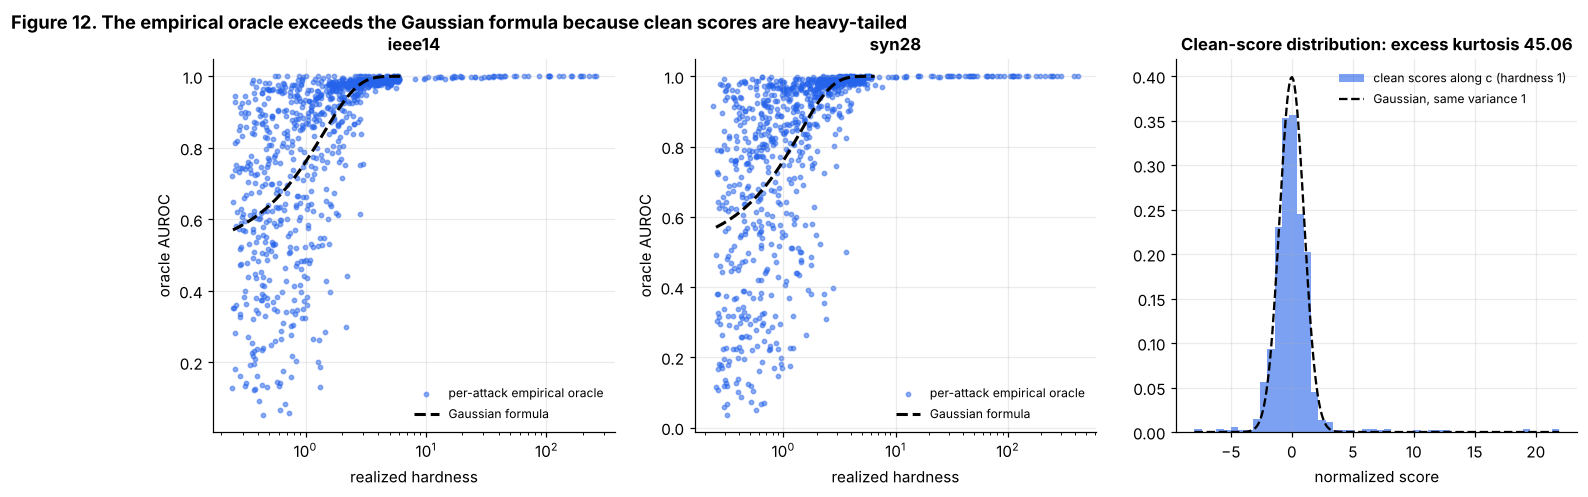

PosixPath('/tmp/w2/proj/figures/fig12_oracle_validity.png')

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, name in zip(axes[:2], ["ieee14", "syn28"]):
    cal_ = CAL[name]; auc_, dl_, s_att_ = oracle_scores(cal_, DS[name]["test"])
    ax.scatter(dl_, auc_, s=8, alpha=0.5, color=PAL["blue"], label="per-attack empirical oracle")
    xx = np.linspace(0.25, 6.5, 200); ax.plot(xx, oracle_auc(xx), "k--", lw=2, label="Gaussian formula")
    ax.set_xscale("log"); ax.set_xlabel("realized hardness"); ax.set_ylabel("oracle AUROC"); ax.set_title(f"{name}"); ax.legend(fontsize=8)
ax = axes[2]
cal_ = CAL["ieee14"]; dt = DS["ieee14"]["test"]; ia = np.where(dt["label"] == 1)[0]; ic = np.where(dt["label"] == 0)[0]
i0 = ia[np.argmin(np.abs(dt["delta"][ia] - 1.0))]; c0 = dt["shift"][i0]
s_clean = ((dt["x"][ic] - cal_.mu) @ cal_.Sinv @ c0) / cal_.delta(c0)[0]
ax.hist(s_clean, bins=50, density=True, color=PAL["blue"], alpha=0.6, label="clean scores along c (hardness 1)")
xg = np.linspace(s_clean.min(), s_clean.max(), 300); ax.plot(xg, st.norm.pdf(xg, 0, 1), "k--", label="Gaussian, same variance 1")
ax.set_title(f"Clean-score distribution: excess kurtosis {st.kurtosis(s_clean):.2f}"); ax.legend(fontsize=8); ax.set_xlabel("normalized score")
fig.suptitle("Figure 12. The empirical oracle exceeds the Gaussian formula because clean scores are heavy-tailed", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig12_oracle_validity")

## Part 9. Shortcut audit

A benchmark can be solved without solving the problem. This part applies five tests to any FDI dataset. They are run on **(a) the existing SCEPTRE dataset** (IEEE 14, from the earlier project), and **(b) the generator built in this notebook**.

| Test | Question | What a solvable-by-shortcut dataset looks like |
|---|---|---|
| T1 Intrinsic dimension | How many principal components carry 99% of clean variance, relative to the dimension? And, where an estimator noise floor is available, in how many directions does natural variability exceed that floor by 10x (the directions an attacker can hide in)? | Few of either. Most of the space is "impossible", so almost any perturbation stands out |
| T2 Channel consistency | Does the attack change only some measurement channels? | Some channels never change, so a detector can read the unaltered ones |
| T3 Trivial-detector gap | Does a Hotelling test, a PCA test, or gradient boosting on a dozen summary statistics match the best deep model? | Yes, to within about 0.01 AUROC |
| T4 Split leakage | Do test windows have a near-twin in the training set? | A large share of near-duplicates |
| T5 Grid-identity probe | Can the attack label be predicted from grid-level constants alone? | Yes (the attack rate varies by grid, so identifying the grid leaks the label) |

Caveat on T1: a variance-based count is dominated by the single biggest source of variation. In both datasets that is a system-wide load factor, so the variance-based number is low for both and cannot by itself separate them. The noise-floor count is more informative but needs the estimator's own covariance, which the SCEPTRE data does not ship. The tests are cheap and use only data the benchmark already provides. Failing a test does not make a dataset wrong; it limits what claims it can support.

In [27]:
SC_DIR = ROOT / "reference" / "sceptre" / "dataset" / "case14"
SC_JSON = ROOT / "reference" / "sceptre" / "outputs" / "sceptre_results.json"
HAS_SCEPTRE = (SC_DIR / "train.npz").exists()
print("SCEPTRE reference data present:", HAS_SCEPTRE, "|", SC_DIR)

def nn_near_duplicate_rate(Ftr, Fte, seed=0, n=2000):
    """Leakage check. Returns (share of test rows closer to train than the 10th percentile of train-to-train
    nearest-neighbour distances, median-distance ratio test/train).  For independent splits the share is about 10%
    and the ratio about 1; a leaky split gives a much larger share and a ratio well below 1."""
    from sklearn.neighbors import NearestNeighbors
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(Ftr)
    i = rng.choice(len(Ftr), min(n, len(Ftr)), replace=False)
    d_tt = nn.kneighbors(Ftr[i], 2)[0][:, 1]                         # nearest OTHER training row
    j = rng.choice(len(Fte), min(n, len(Fte)), replace=False)
    d_et = nn.kneighbors(Fte[j], 1)[0][:, 0]
    return float(np.mean(d_et < np.percentile(d_tt, 10))), float(np.median(d_et) / np.median(d_tt))

audit = {}
if HAS_SCEPTRE:
    tr = np.load(SC_DIR / "train.npz"); te = np.load(SC_DIR / "test.npz")
    Xtr, Xte = tr["X"].astype(np.float32), te["X"].astype(np.float32); ytr, yte = tr["y_det"], te["y_det"]
    def sc_feats(X):
        return np.hstack([X[:, -1].reshape(len(X), -1), np.abs(np.diff(X, axis=1)).mean(1).reshape(len(X), -1)])
    Ftr, Fte = sc_feats(Xtr), sc_feats(Xte)
    # T1
    F0 = Xtr[ytr == 0][:, -1].reshape(-1, Xtr.shape[2] * Xtr.shape[3])
    cs = np.cumsum(PCA().fit(F0).explained_variance_ratio_)
    k99, k95 = int(np.searchsorted(cs, 0.99) + 1), int(np.searchsorted(cs, 0.95) + 1)
    # T2: how much label information does each channel carry? best single-feature AUROC over buses,
    # using the level at the last frame and the temporal standard deviation over the window
    nb, nc = Xtr.shape[2], Xtr.shape[3]
    def best_auc(vals):
        return max(abs(roc_auc_score(ytr, vals[:, b]) - 0.5) + 0.5 for b in range(nb))
    ch_level = [best_auc(Xtr[:, -1, :, c]) for c in range(nc)]
    ch_std = [best_auc(Xtr[:, :, :, c].std(1)) for c in range(nc)]
    # T3
    dim = F0.shape[1]; clean = Ftr[ytr == 0][:, :dim]; mu_ = clean.mean(0); Si_ = np.linalg.inv(LedoitWolf().fit(clean).covariance_)
    t2 = lambda F: np.einsum("ij,jk,ik->i", F[:, :dim] - mu_, Si_, F[:, :dim] - mu_)
    pca_ = PCA(0.95).fit(clean)
    pr = lambda F: ((F[:, :dim] - pca_.inverse_transform(pca_.transform(F[:, :dim]))) ** 2).sum(1)
    g_ = HistGradientBoostingClassifier(max_iter=200, random_state=0).fit(Ftr, ytr)
    sc_ = StandardScaler().fit(Ftr); m_ = MLPClassifier((128, 64), early_stopping=True, max_iter=100, random_state=0).fit(sc_.transform(Ftr), ytr)
    flat = lambda X: X[:, ::6].reshape(len(X), -1); sc2 = StandardScaler().fit(flat(Xtr))
    m2 = MLPClassifier((128, 64), early_stopping=True, max_iter=100, random_state=0).fit(sc2.transform(flat(Xtr)), ytr)
    triv = {"hotelling": roc_auc_score(yte, t2(Fte)), "pca_recon": roc_auc_score(yte, pr(Fte)),
            "gbdt_frame_stats": roc_auc_score(yte, g_.predict_proba(Fte)[:, 1])}
    deep = {"mlp_frame": roc_auc_score(yte, m_.predict_proba(sc_.transform(Fte))[:, 1]),
            "mlp_window": roc_auc_score(yte, m2.predict_proba(sc2.transform(flat(Xte)))[:, 1])}
    reported = {}
    if SC_JSON.exists():
        bm = json.load(open(SC_JSON))["benchmark"]; reported = {k: v["det_auc"][0] for k, v in bm.items()}
    # T4
    dup, ratio = nn_near_duplicate_rate(Ftr[:, :dim], Fte[:, :dim])
    audit["sceptre"] = dict(k99=k99, k95=k95, dim=dim, ch_level=ch_level, ch_std=ch_std, triv=triv, deep=deep, reported=reported, dup=dup, ratio=ratio)
    print(f"T1 intrinsic dimension: {k95}/{dim} components for 95% of clean variance, {k99}/{dim} for 99%")
    print("T2 best single-feature AUROC per channel (channel order as stored):")
    print("    level at last frame      :", np.round(ch_level, 3)); print("    temporal std over window :", np.round(ch_std, 3))
    print("T3 trivial detectors:", {k: round(v, 4) for k, v in triv.items()})
    print("   deep (this notebook, sklearn):", {k: round(v, 4) for k, v in deep.items()})
    if reported: print("   deep (SCEPTRE-reported AUROC, 10 architectures): best %.4f (%s), SCEPTRE %.4f" %
                       (max(reported.values()), max(reported, key=reported.get), reported["sceptre"]))
    print(f"T4 near-duplicate share {dup:.1%} (about 10% if independent), median-distance ratio {ratio:.2f} (about 1 if independent)")
else:
    print("SCEPTRE reference data not found: T1 to T4 on SCEPTRE are skipped and H1 is marked NOT_RUN.")

SCEPTRE reference data present: True | /tmp/w2/proj/reference/sceptre/dataset/case14


T1 intrinsic dimension: 3/56 components for 95% of clean variance, 37/56 for 99%
T2 best single-feature AUROC per channel (channel order as stored):
    level at last frame      : [0.526 0.529 0.537 0.53 ]
    temporal std over window : [0.892 0.525 0.937 0.565]
T3 trivial detectors: {'hotelling': 0.6364, 'pca_recon': 0.6367, 'gbdt_frame_stats': 0.9978}
   deep (this notebook, sklearn): {'mlp_frame': 0.9759, 'mlp_window': 0.8347}
   deep (SCEPTRE-reported AUROC, 10 architectures): best 0.9989 (mlp), SCEPTRE 0.9976
T4 near-duplicate share 6.6% (about 10% if independent), median-distance ratio 1.03 (about 1 if independent)


### 9.1 The same tests on this notebook's generator

T3 needs a definition that works for both datasets. **Trivial** detectors: Hotelling, PCA reconstruction error, and gradient boosting on a dozen summary statistics. **Learned** detectors: the in-grid MLP, gradient-boosted trees on the full whitened state, and logistic regression. The *gap* is the best learned AUROC minus the best trivial AUROC, computed in the **hard bins** (hardness below 2), because that is the region where a benchmark either discriminates between methods or does not. A gap above 0.02 means a trivial detector does not suffice.

Here the learned detectors get the full training set on IEEE 14 and on the synthetic 28-bus grid.

In [28]:
HARD_MASK = lambda d: (d["label"] == 0) | (d["delta"] < 2.0)

def hard_auc(score, d):
    m = HARD_MASK(d); return roc_auc_score(d["label"][m], score[m])

def audit_ours(name, seed=0):
    cal, tr, te = CAL[name], DS[name]["train"], DS[name]["test"]
    out = {}
    out["k99"] = int(np.searchsorted(np.cumsum(cal.eigval) / cal.eigval.sum(), 0.99) + 1); out["dim"] = cal.ns
    # noise-floor "hiding dimension": directions where natural variance exceeds the estimator's own noise by 10x
    sim = SIMS[name]; Hs = sim.H_nom; Gi = np.linalg.inv(Hs.T @ (sim.mt["W"][:, None] * Hs))
    floor_dir = np.einsum("ji,jk,ki->i", cal.eigvec, Gi, cal.eigvec)
    out["hide10"] = int((cal.eigval / floor_dir > 10).sum())
    out["k95"] = int(np.searchsorted(np.cumsum(cal.eigval) / cal.eigval.sum(), 0.95) + 1)
    triv, learned = {}, {}
    for D in (Hotelling, PCARecon):
        det = D().fit(cal, None, seed); triv[det.name] = hard_auc(det.score(cal, te), te)
    g = GBDTSum().fit(cal, tr, seed); triv["gbdt_sum"] = hard_auc(g.score(cal, te), te)
    for D in (LogReg, GBDT, MLP):
        det = D().fit(cal, tr, seed); learned[det.name] = hard_auc(det.score(cal, te), te)
    # T4: near duplicates in the whitened state
    dup, ratio = nn_near_duplicate_rate(whiten(cal, tr["x"]), whiten(cal, te["x"]))
    out["chi2_auc"] = roc_auc_score(te["label"], te["J"])           # T2: is the attack visible in the residual at all?
    out.update(triv=triv, learned=learned, gap=max(learned.values()) - max(triv.values()), dup=dup, ratio=ratio)
    return out

for nm in STUDY_GRIDS: audit[nm] = audit_ours(nm)
rows = []
for nm in STUDY_GRIDS:
    a = audit[nm]
    rows.append(dict(grid=nm, intrinsic_k95=f"{a['k95']}/{a['dim']}", intrinsic_k99=f"{a['k99']}/{a['dim']}", hiding_dim=f"{a['hide10']}/{a['dim']}",
                     best_trivial_hard=max(a["triv"].values()), best_learned_hard=max(a["learned"].values()),
                     gap=a["gap"], chi2_auc=a["chi2_auc"], near_dup_share=a["dup"], nn_ratio=a["ratio"]))
print(pd.DataFrame(rows).round(3).to_string(index=False))

  grid intrinsic_k95 intrinsic_k99 hiding_dim  best_trivial_hard  best_learned_hard   gap  chi2_auc  near_dup_share  nn_ratio
ieee14          1/27          1/27       5/27              0.531              0.554 0.023     0.498           0.102     1.018
 syn28          2/55          3/55      13/55              0.545              0.547 0.002     0.499           0.096     1.000


### 9.2 T5: the grid-identity probe

The probe trains a gradient-boosted classifier on **grid-level constants only** (number of states, number of meters, degrees of freedom, number of buses) with leave-one-grid-out evaluation. In this benchmark every grid has the same attack rate by construction, so the probe should sit at chance. It is included because the first thing someone adds when extending a benchmark to more grids is unequal attack rates, and this test catches the resulting leak.

In [29]:
G_rows, G_y = [], []
for nm in TRAIN_FAMILY + UNSEEN:
    c_ = CAL[nm]; te = DS[nm]["test"]
    feats_ = [c_.ns, SIMS[nm].mt["m"], c_.dof, SIMS[nm].g.n]
    for y_ in te["label"]: G_rows.append(feats_); G_y.append(y_)
G_rows, G_y = np.array(G_rows), np.array(G_y); gid = np.concatenate([[i] * len(DS[nm]["test"]["label"]) for i, nm in enumerate(TRAIN_FAMILY + UNSEEN)])
probe = []
for g_out in np.unique(gid):
    tr_m = gid != g_out
    m_ = HistGradientBoostingClassifier(max_iter=50, random_state=0).fit(G_rows[tr_m], G_y[tr_m])
    probe.append(roc_auc_score(G_y[~tr_m], m_.predict_proba(G_rows[~tr_m])[:, 1]) if len(np.unique(G_y[~tr_m])) > 1 else np.nan)
probe = np.array(probe)
print(f"grid-identity probe, leave-one-grid-out: mean AUROC {np.nanmean(probe):.3f} (chance = 0.5)")
audit["probe_auc"] = float(np.nanmean(probe))

grid-identity probe, leave-one-grid-out: mean AUROC 0.500 (chance = 0.5)


### 9.3 Audit scorecard (Figure 13)

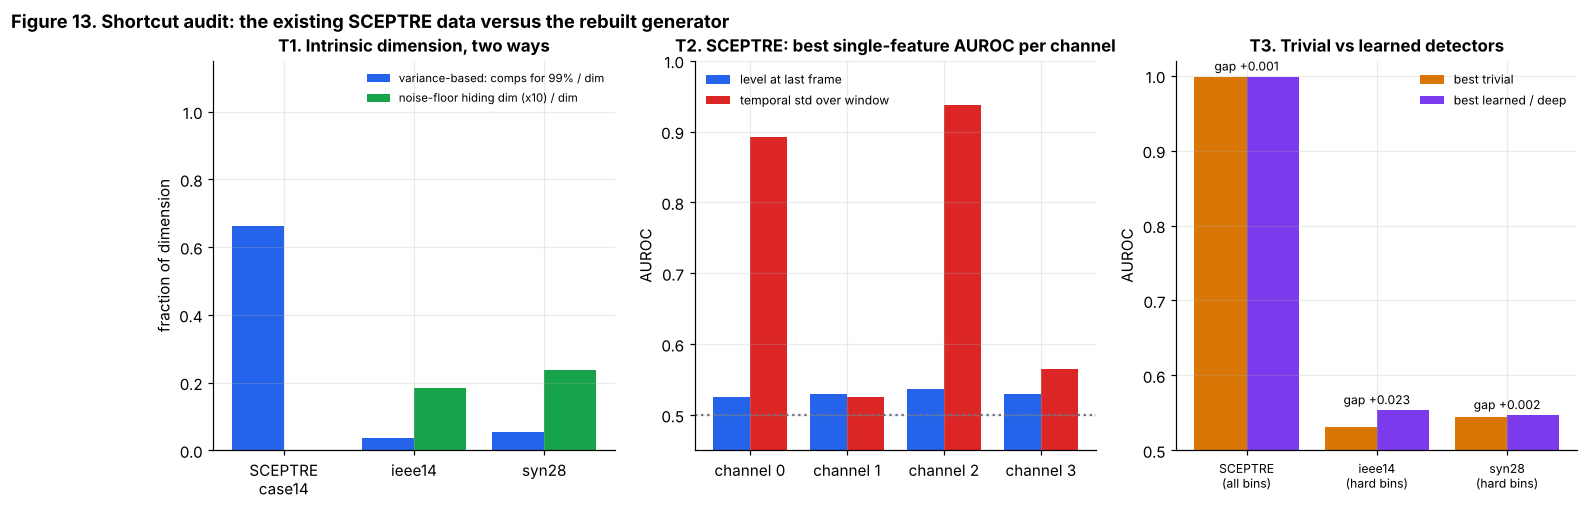

PosixPath('/tmp/w2/proj/figures/fig13_audit_scorecard.png')

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
labels, v99, vh = [], [], []
if HAS_SCEPTRE: labels.append("SCEPTRE\ncase14"); v99.append(audit["sceptre"]["k99"] / audit["sceptre"]["dim"]); vh.append(np.nan)
for nm in STUDY_GRIDS: labels.append(nm); v99.append(audit[nm]["k99"] / audit[nm]["dim"]); vh.append(audit[nm]["hide10"] / audit[nm]["dim"])
x_ = np.arange(len(labels)); ax.bar(x_ - 0.2, v99, 0.4, color=PAL["blue"], label="variance-based: comps for 99% / dim")
ax.bar(x_ + 0.2, np.nan_to_num(vh), 0.4, color=PAL["green"], label="noise-floor hiding dim (x10) / dim")
ax.set_xticks(x_); ax.set_xticklabels(labels); ax.set_ylim(0, 1.15); ax.legend(fontsize=7.5, loc="upper right")
ax.set_ylabel("fraction of dimension"); ax.set_title("T1. Intrinsic dimension, two ways")
ax = axes[1]
if HAS_SCEPTRE:
    w_ = 0.38
    ax.bar(np.arange(4) - w_ / 2, audit["sceptre"]["ch_level"], w_, color=PAL["blue"], label="level at last frame")
    ax.bar(np.arange(4) + w_ / 2, audit["sceptre"]["ch_std"], w_, color=PAL["red"], label="temporal std over window")
    ax.axhline(0.5, color=PAL["grey"], ls=":"); ax.set_xticks(range(4)); ax.set_xticklabels([f"channel {c}" for c in range(4)]); ax.legend(fontsize=8)
    ax.set_ylim(0.45, 1.0)
ax.set_title("T2. SCEPTRE: best single-feature AUROC per channel"); ax.set_ylabel("AUROC")
ax = axes[2]
names, triv_v, deep_v = [], [], []
if HAS_SCEPTRE:
    names.append("SCEPTRE\n(all bins)"); triv_v.append(max(audit["sceptre"]["triv"].values()))
    rep = audit["sceptre"]["reported"]; deep_v.append(max(max(audit["sceptre"]["deep"].values()), max(rep.values()) if rep else 0))
for nm in STUDY_GRIDS:
    names.append(nm + "\n(hard bins)"); triv_v.append(max(audit[nm]["triv"].values())); deep_v.append(max(audit[nm]["learned"].values()))
x_ = np.arange(len(names)); ax.bar(x_ - 0.2, triv_v, 0.4, color=PAL["amber"], label="best trivial"); ax.bar(x_ + 0.2, deep_v, 0.4, color=PAL["purple"], label="best learned / deep")
ax.set_xticks(x_); ax.set_xticklabels(names, fontsize=8); ax.set_ylim(0.5, 1.02); ax.legend(fontsize=8); ax.set_ylabel("AUROC")
for i, (a, b) in enumerate(zip(triv_v, deep_v)): ax.text(i, max(a, b) + 0.008, f"gap {b-a:+.3f}", ha="center", fontsize=8)
ax.set_title("T3. Trivial vs learned detectors")
fig.suptitle("Figure 13. Shortcut audit: the existing SCEPTRE data versus the rebuilt generator", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig13_audit_scorecard")

## Part 10. In-grid oracle-gap study

The central measurement of the study. On two grids (IEEE 14 and the synthetic 28-bus grid), every detector is trained at four label budgets and evaluated on the same hardness-stratified test set. For each hardness bin we report the detector's AUROC, the empirical oracle's AUROC, and the difference.

**Design.**

* Budgets: 300, 900, 1,800 and 3,600 training windows (half clean, half attacked), drawn without replacement from a pool; three seeds each (different training subsets and different tuning draws). Clean-only detectors (`hotelling`, `pca_recon`, `iforest`, `chi2`) do not use labels, so they do not vary with the budget.
* Every supervised detector gets the same random-search budget (Part 8.2).
* Besides the in-grid detectors, the two **summary-view** detectors (`gbdt_sum`, `mlp_sum`) are included. They see only twelve physics-motivated statistics, including the Hotelling energy, so they act as a first, cheap version of the *structured detector* the proposal calls C5.
* **Large-data reference.** On IEEE 14 only, a gradient-boosted model is also trained on a much larger set (about 14,000 windows). It estimates what a learner can reach when data is abundant, and gives a second reference next to the oracle that does not assume a known direction.

H2 reads off this study: *the best tuned learned detector is at least 0.05 AUROC below the empirical oracle over hardness 1 to 4 at 1,800 windows, and the gap shrinks with more data.*

In [31]:
BUDGETS = [300, 900, 1800, 3600] if BUDGET == "full" else [150, 300, 500, 1000]
H2_BUDGET = 1800 if BUDGET == "full" else 500
DETS_STUDY = [Hotelling, PCARecon, IForest, Chi2, LogReg, GBDT, MLP, GBDTSum, MLPSum]

# optional big pool for the large-data reference on ieee14
big_cache = DATA / f"big_ieee14_{BUDGET}.pkl"
n_big = 10800 if BUDGET == "full" else 3000
if big_cache.exists():
    with open(big_cache, "rb") as fh: BIG14 = pickle.load(fh)
else:
    rng = rng_for("big14"); t0 = time.time()
    BIG14 = concat_blocks(gen_clean_block(SIMS["ieee14"], CAL["ieee14"], rng, n_big // 2), gen_attack_block(SIMS["ieee14"], CAL["ieee14"], rng, n_big // 2, "strat"))
    with open(big_cache, "wb") as fh: pickle.dump(BIG14, fh)
    print(f"large-data pool built: {n_big} windows in {time.time()-t0:.0f}s")

def pool_for(name):
    return concat_blocks(DS[name]["train"], DS[name]["train_extra"])

INGRID = {}          # INGRID[grid][budget][seed][detector] = dict(bins, overall)
INGRID_SCORES = {}   # test scores at the reference budget, seed 0 (used for damage analysis)
t_all = time.time()
for name in STUDY_GRIDS:
    cal, test, pool = CAL[name], DS[name]["test"], pool_for(name)
    INGRID[name] = {}; INGRID_SCORES[name] = {}
    unsup = {}
    for D in (Hotelling, PCARecon, IForest, Chi2):
        det = D().fit(cal, None, 0); s = det.score(cal, test)
        unsup[det.name] = dict(bins=auc_by_bin(s, test), overall=overall_auc(s, test)); INGRID_SCORES[name][det.name] = s
    for b in BUDGETS:
        INGRID[name][b] = {}
        for seed in range(SIZES["n_budget_seeds"]):
            sub = subsample_balanced(pool, b, np.random.default_rng(1000 * seed + b))
            out = {k: dict(v) for k, v in unsup.items()}
            for D in (LogReg, GBDT, MLP, GBDTSum, MLPSum):
                det = D().fit(cal, sub, seed); s = det.score(cal, test)
                out[det.name] = dict(bins=auc_by_bin(s, test), overall=overall_auc(s, test))
                if b == H2_BUDGET and seed == 0: INGRID_SCORES[name][det.name] = s
            INGRID[name][b][seed] = out
        print(f"{name}: budget {b} done ({time.time()-t_all:.0f}s)", flush=True)
    INGRID[name]["oracle"] = oracle_by_bin(cal, test); INGRID[name]["formula"] = formula_by_bin(test)

# large-data reference on ieee14
LARGE = {}
cal14, te14 = CAL["ieee14"], DS["ieee14"]["test"]
for D in (GBDT, GBDTSum):
    det = D().fit(cal14, BIG14, 0); s = det.score(cal14, te14)
    LARGE[det.name] = dict(bins=auc_by_bin(s, te14), overall=overall_auc(s, te14))
print("large-data reference (ieee14, %d windows):" % len(BIG14["label"]))
print(pd.DataFrame({k: v["bins"] for k, v in LARGE.items()}, index=BIN_NAMES).T.round(3).to_string())

ieee14: budget 300 done (8s)


ieee14: budget 900 done (22s)


ieee14: budget 1800 done (53s)


ieee14: budget 3600 done (105s)


syn28: budget 300 done (113s)


syn28: budget 900 done (128s)


syn28: budget 1800 done (157s)


syn28: budget 3600 done (206s)


large-data reference (ieee14, 10800 windows):
          0.25-0.5  0.5-1    1-2    2-4  4-6.5
gbdt         0.565  0.578  0.595  0.781  0.919
gbdt_sum     0.554  0.558  0.594  0.779  0.934


### 10.1 Results at the reference budget (Figure 14)

Panel A shows mean AUROC by hardness bin (error bars: standard deviation over seeds), with the empirical oracle as a thick black line and the Gaussian formula dashed. Panel B is the gap heatmap. A *negative* gap means the detector scored *above* the oracle in that bin, which can happen because the oracle is a linear reference and learned detectors can use nonlinear structure.

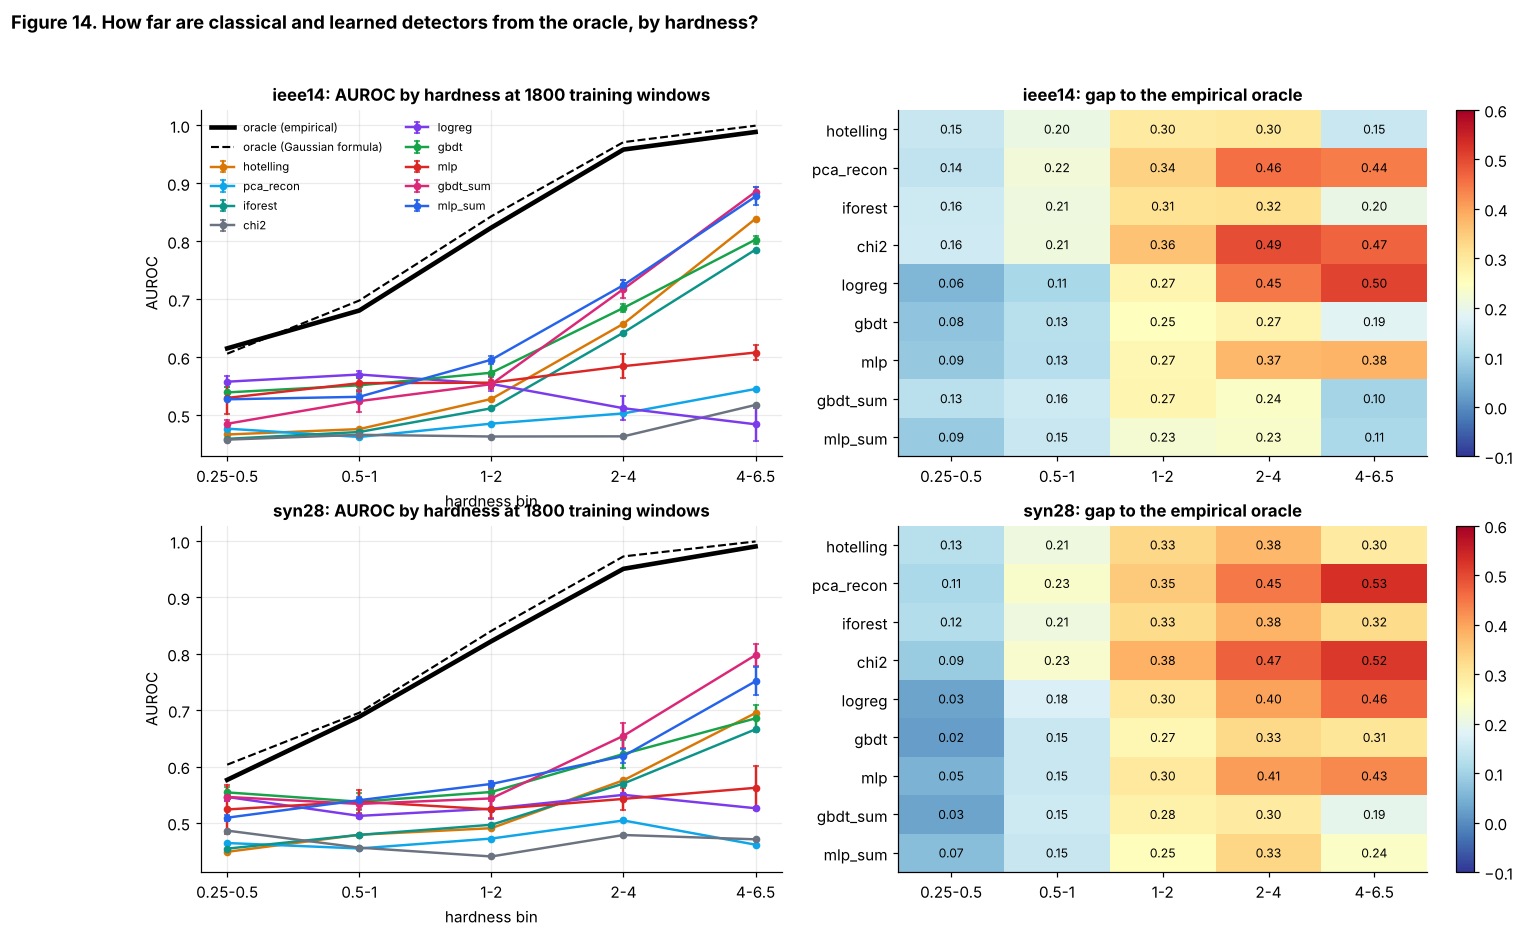

PosixPath('/tmp/w2/proj/figures/fig14_oracle_gap.png')

In [32]:
def agg(name, b, det):
    arr = np.array([INGRID[name][b][s][det]["bins"] for s in INGRID[name][b]])
    return arr.mean(0), arr.std(0)

DET_COLORS = dict(chi2=PAL["grey"], hotelling=PAL["amber"], pca_recon=PAL["sky"], iforest=PAL["teal"], logreg=PAL["purple"],
                  gbdt=PAL["green"], mlp=PAL["red"], gbdt_sum=PAL["pink"], mlp_sum=PAL["blue"])
DET_NAMES = [D.name if isinstance(D.name, str) else D().name for D in DETS_STUDY]
xs = np.arange(len(BIN_NAMES))
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for r, name in enumerate(STUDY_GRIDS):
    ax = axes[r, 0]
    for d_ in DET_NAMES:
        m, s = agg(name, H2_BUDGET, d_); ax.errorbar(xs, m, yerr=s, fmt="o-", color=DET_COLORS[d_], label=d_, lw=1.6, ms=4, capsize=2)
    ax.plot(xs, INGRID[name]["oracle"], "k-", lw=3, label="oracle (empirical)"); ax.plot(xs, INGRID[name]["formula"], "k--", lw=1.4, label="oracle (Gaussian formula)")
    ax.set_xticks(xs); ax.set_xticklabels(BIN_NAMES); ax.set_xlabel("hardness bin"); ax.set_ylabel("AUROC"); ax.set_title(f"{name}: AUROC by hardness at {H2_BUDGET} training windows")
    if r == 0: ax.legend(fontsize=7.5, ncol=2)
    ax = axes[r, 1]
    gap = np.array([INGRID[name]["oracle"] - agg(name, H2_BUDGET, d_)[0] for d_ in DET_NAMES])
    im = ax.imshow(gap, cmap="RdYlBu_r", vmin=-0.1, vmax=0.6, aspect="auto")
    ax.set_xticks(xs); ax.set_xticklabels(BIN_NAMES); ax.set_yticks(range(len(DET_NAMES))); ax.set_yticklabels(DET_NAMES)
    for i in range(gap.shape[0]):
        for j in range(gap.shape[1]): ax.text(j, i, f"{gap[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.grid(False); ax.set_title(f"{name}: gap to the empirical oracle"); plt.colorbar(im, ax=ax, fraction=0.04)
fig.suptitle("Figure 14. How far are classical and learned detectors from the oracle, by hardness?", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig14_oracle_gap")

### 10.2 Learning curves: does the gap shrink with data? (Figure 15)

H2's second half. For each detector, AUROC over the mid-hardness region (bins covering hardness 1 to 4) is plotted against the label budget, with the empirical oracle and, on IEEE 14, the large-data reference as horizontal lines.

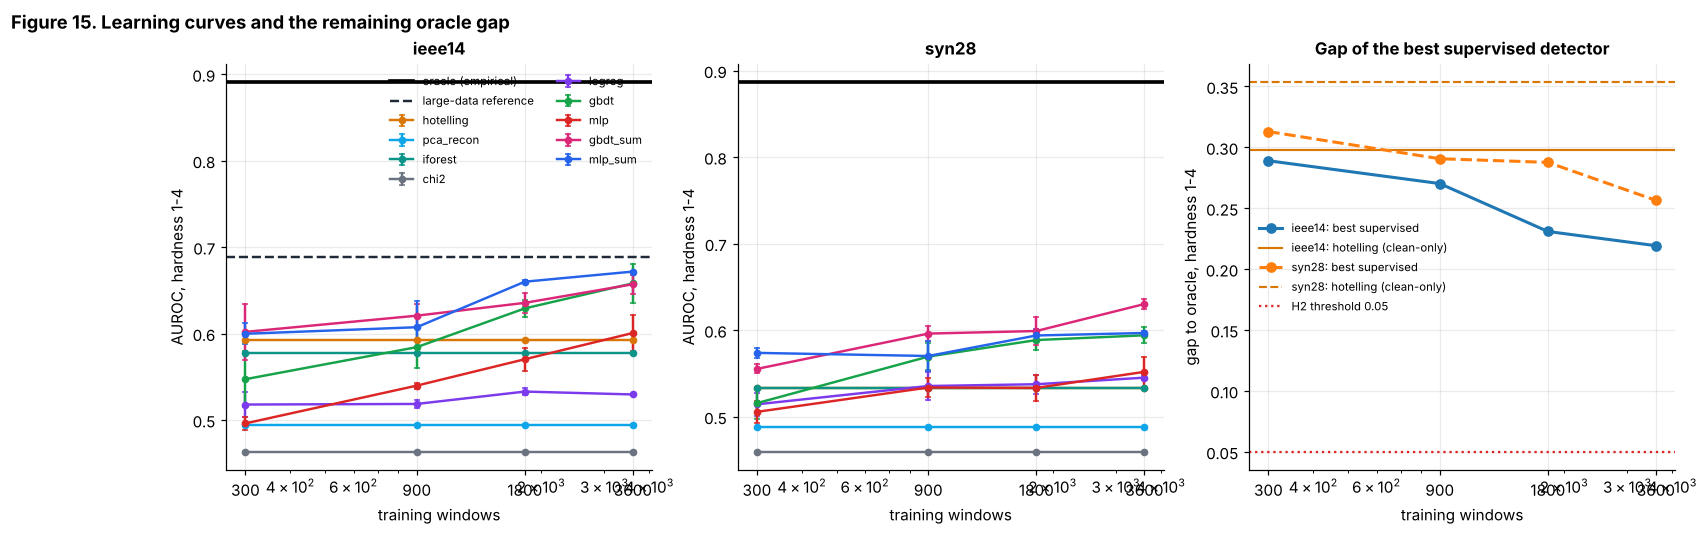

        gap_ref  gap_small  gap_large
ieee14    0.231      0.289      0.219
syn28     0.288      0.313      0.256


In [33]:
MID_BINS = [BIN_NAMES.index("1-2"), BIN_NAMES.index("2-4")]
HARD_BINS = [BIN_NAMES.index("0.5-1"), BIN_NAMES.index("1-2")]
def region(vals, idx): return float(np.nanmean(np.asarray(vals)[idx]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, name in zip(axes[:2], STUDY_GRIDS):
    for d_ in DET_NAMES:
        ms = []; ss = []
        for b in BUDGETS:
            arr = np.array([region(INGRID[name][b][s][d_]["bins"], MID_BINS) for s in INGRID[name][b]]); ms.append(arr.mean()); ss.append(arr.std())
        ax.errorbar(BUDGETS, ms, yerr=ss, fmt="o-", color=DET_COLORS[d_], label=d_, lw=1.6, ms=4, capsize=2)
    ax.axhline(region(INGRID[name]["oracle"], MID_BINS), color="k", lw=2.4, label="oracle (empirical)")
    if name == "ieee14":
        ax.axhline(max(region(v["bins"], MID_BINS) for v in LARGE.values()), color=PAL["ink"], ls="--", lw=1.6, label="large-data reference")
    ax.set_xscale("log"); ax.set_xlabel("training windows"); ax.set_ylabel("AUROC, hardness 1-4"); ax.set_title(name); ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS)
axes[0].legend(fontsize=7.5, ncol=2)
ax = axes[2]
for name, ls in zip(STUDY_GRIDS, ["-", "--"]):
    best = []
    for b in BUDGETS:
        sup = ["logreg", "gbdt", "mlp", "gbdt_sum", "mlp_sum"]
        best.append(INGRID[name]["oracle"][MID_BINS].mean() - max(np.mean([region(INGRID[name][b][s][d_]["bins"], MID_BINS) for s in INGRID[name][b]]) for d_ in sup))
    ax.plot(BUDGETS, best, "o" + ls, lw=2, label=f"{name}: best supervised"); 
    hot = INGRID[name]["oracle"][MID_BINS].mean() - region(INGRID[name][BUDGETS[0]][0]["hotelling"]["bins"], MID_BINS)
    ax.axhline(hot, color=PAL["amber"], ls=ls, lw=1.4, label=f"{name}: hotelling (clean-only)")
ax.axhline(THRESH["h2_gap"], color=PAL["red"], ls=":", label="H2 threshold 0.05"); ax.set_xscale("log"); ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS)
ax.set_xlabel("training windows"); ax.set_ylabel("gap to oracle, hardness 1-4"); ax.set_title("Gap of the best supervised detector"); ax.legend(fontsize=7.5)
fig.suptitle("Figure 15. Learning curves and the remaining oracle gap", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig15_learning_curves")

# H2 numbers
h2 = {}
for name in STUDY_GRIDS:
    orc = INGRID[name]["oracle"][MID_BINS].mean(); sup = ["logreg", "gbdt", "mlp", "gbdt_sum", "mlp_sum"]
    def best_at(b): return max(np.mean([region(INGRID[name][b][s][d_]["bins"], MID_BINS) for s in INGRID[name][b]]) for d_ in sup)
    h2[name] = dict(gap_ref=orc - best_at(H2_BUDGET), gap_small=orc - best_at(BUDGETS[0]), gap_large=orc - best_at(BUDGETS[-1]))
print(pd.DataFrame(h2).T.round(3).to_string()); 

## Part 11. Leave-grid-out generalization

Published FDI detectors are trained and tested on windows from the *same* grid. An operator who deploys a detector on a different grid, or on the same grid after a topology change, is asking an extrapolation question. This part measures it with the **grid-agnostic** summary view (Part 8.1), since a fixed-length view is what makes a model portable at all.

**Training arms** (all with exactly 1,800 training windows in total, so no arm has more data):

| Arm | Training grids | Windows per grid |
|---|---|---|
| `single14` | IEEE 14 only | 1,800 |
| `three` | `ieee14`, `ieee14_v1`, `ieee30` | 600 |
| `broad8` | the full 8-grid training family | 225 |

**Test.** (i) Fresh windows of the *seen* grids, and (ii) the four **unseen** grids (`ieee30_v2`, `syn24u`, `syn44u`, `ieee57`), never used for training, tuning, or threshold selection. The metric is AUROC on attacks of hardness 0.5 to 2 (the hard region) against all clean windows.

* **H12**: the three-grid arm loses at least 0.05 AUROC on unseen grids relative to seen grids.
* **H13**: the broad family beats single-IEEE training on unseen grids at equal sample count (pre-registered pass rule: mean paired improvement of at least 0.01, with the sign positive in every seed).

Different grids differ in intrinsic difficulty, so a raw drop could reflect that rather than transfer. The Hotelling test needs no training, so its seen-minus-unseen difference measures grid difficulty alone, and the **difficulty-adjusted** drop subtracts it.

In [34]:
THRESH["h13_min"] = 0.01
ARMS = {"single14": {"ieee14": 1800},
        "three": {"ieee14": 600, "ieee14_v1": 600, "ieee30": 600},
        "broad8": {g: 225 for g in TRAIN_FAMILY}}
if BUDGET == "quick": ARMS = {k: {g: max(20, n // 3) for g, n in v.items()} for k, v in ARMS.items()}

def small_auc(score, d, lo=0.5, hi=2.0):
    m = (d["label"] == 0) | ((d["delta"] >= lo) & (d["delta"] < hi))
    return roc_auc_score(d["label"][m], score[m])

def train_pool_for(g):
    return pool_for(g) if g in DS and "train_extra" in DS[g] else DS[g]["train"]

def arm_training_arrays(arm, seed, model_cls):
    Xs, ys = [], []
    for g, n in ARMS[arm].items():
        sub = subsample_balanced(train_pool_for(g), n - n % 2, np.random.default_rng(7000 + 31 * seed + len(g)))
        Xs.append(summary_features(CAL[g], sub)); ys.append(sub["label"])
    return np.vstack(Xs), np.concatenate(ys)

SEEN_SETS = ["ieee14", "ieee14_v1", "ieee30"]
tr_res = {}   # tr_res[arm][model][seed] = dict(seen=..., unseen={grid: auc})
t0 = time.time()
for arm in ARMS:
    tr_res[arm] = {}
    for Mcls in (GBDTSum, MLPSum):
        tr_res[arm][Mcls.name] = {}
        for seed in range(SIZES["n_budget_seeds"]):
            X, y = arm_training_arrays(arm, seed, Mcls); det = Mcls()._fit_xy(X, y, seed)
            out = {"seen": {g: small_auc(det.score(CAL[g], DS[g]["test"]), DS[g]["test"]) for g in TRAIN_FAMILY},
                   "unseen": {g: small_auc(det.score(CAL[g], DS[g]["test"]), DS[g]["test"]) for g in UNSEEN}}
            tr_res[arm][Mcls.name][seed] = out
    print(f"arm {arm} done ({time.time()-t0:.0f}s)", flush=True)

# references that need no training
REF = {"hotelling": {g: small_auc(Hotelling().score(CAL[g], DS[g]["test"]), DS[g]["test"]) for g in TRAIN_FAMILY + UNSEEN},
       "oracle": {g: float(np.nanmean(oracle_by_bin(CAL[g], DS[g]["test"], np.array([0.5, 1.0, 2.0]))) ) for g in TRAIN_FAMILY + UNSEEN}}

rows = []
for arm in ARMS:
    for mname in tr_res[arm]:
        for seed, o in tr_res[arm][mname].items():
            seen_g = [g for g in ARMS[arm]]                          # held-out windows of the grids the arm trained on
            rows.append(dict(arm=arm, model=mname, seed=seed,
                             seen=np.mean([o["seen"][g] for g in seen_g]), unseen=np.mean(list(o["unseen"].values())),
                             hot_seen=np.mean([REF["hotelling"][g] for g in seen_g]), hot_unseen=np.mean([REF["hotelling"][g] for g in UNSEEN])))
TR = pd.DataFrame(rows); TR["drop"] = TR.seen - TR.unseen; TR["drop_adj"] = TR["drop"] - (TR.hot_seen - TR.hot_unseen)
print(TR.groupby(["arm", "model"])[["seen", "unseen", "drop", "drop_adj"]].mean().round(3).to_string())

arm single14 done (14s)


arm three done (30s)


arm broad8 done (45s)


                    seen  unseen   drop  drop_adj
arm      model                                   
broad8   gbdt_sum  0.555   0.549  0.006     0.003
         mlp_sum   0.531   0.529  0.002    -0.001
single14 gbdt_sum  0.567   0.541  0.025     0.006
         mlp_sum   0.566   0.536  0.030     0.011
three    gbdt_sum  0.560   0.544  0.016    -0.000
         mlp_sum   0.558   0.543  0.015    -0.001


### 11.1 Results (Figure 16)

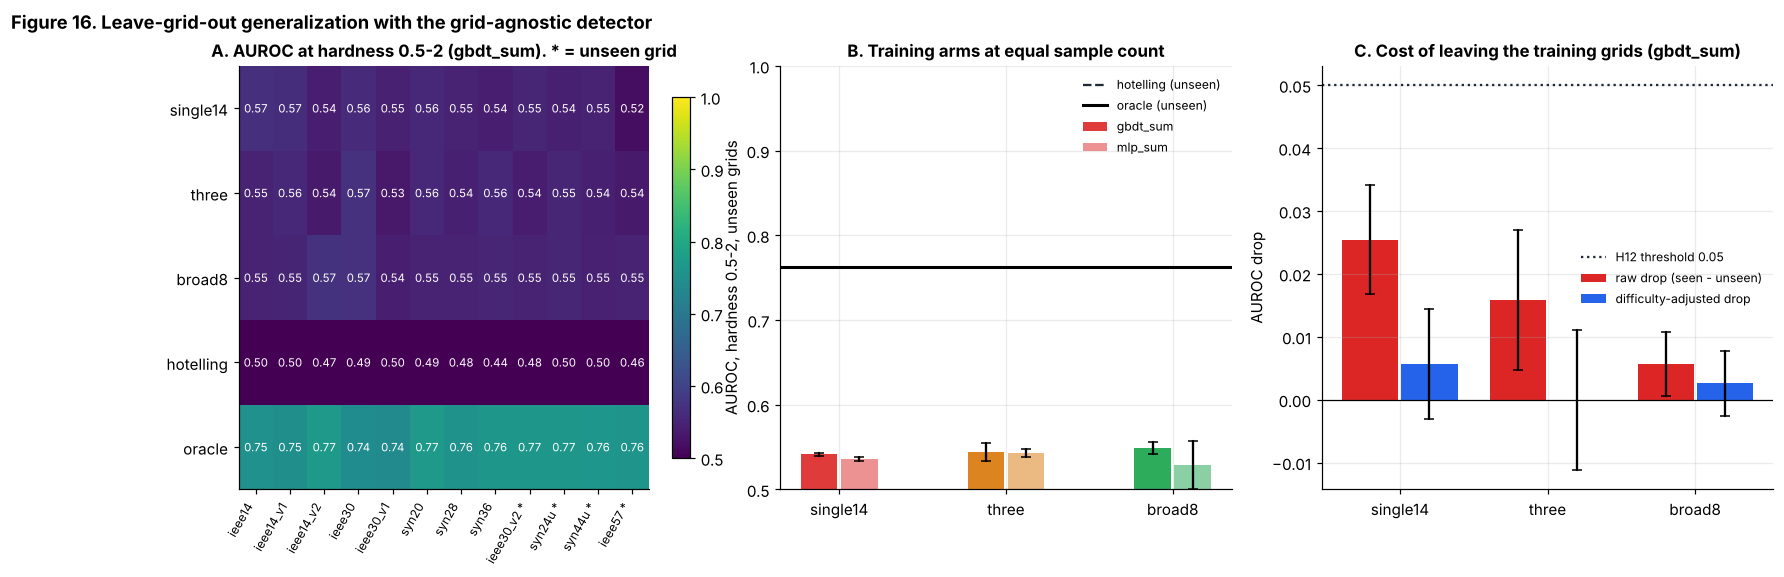

PosixPath('/tmp/w2/proj/figures/fig16_leave_grid_out.png')

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
allg = TRAIN_FAMILY + UNSEEN
M_ = np.array([[np.mean([tr_res[arm]["gbdt_sum"][s]["seen" if g in TRAIN_FAMILY else "unseen"][g] for s in tr_res[arm]["gbdt_sum"]]) for g in allg] for arm in ARMS]
              + [[REF["hotelling"][g] for g in allg], [REF["oracle"][g] for g in allg]])
im = ax.imshow(M_, cmap="viridis", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_yticks(range(M_.shape[0])); ax.set_yticklabels(list(ARMS) + ["hotelling", "oracle"])
ax.set_xticks(range(len(allg))); ax.set_xticklabels([g + (" *" if g in UNSEEN else "") for g in allg], rotation=60, ha="right", fontsize=8)
for i in range(M_.shape[0]):
    for j in range(M_.shape[1]): ax.text(j, i, f"{M_[i, j]:.2f}", ha="center", va="center", color="white" if M_[i, j] < 0.78 else "black", fontsize=7.5)
ax.grid(False); ax.set_title("A. AUROC at hardness 0.5-2 (gbdt_sum). * = unseen grid"); plt.colorbar(im, ax=ax, fraction=0.04)
ax = axes[1]
for k, (arm, col) in enumerate(zip(ARMS, [PAL["red"], PAL["amber"], PAL["green"]])):
    sub = TR[(TR.arm == arm)]; 
    for mname, off in [("gbdt_sum", -0.12), ("mlp_sum", 0.12)]:
        v = sub[sub.model == mname]
        ax.bar(k + off, v.unseen.mean(), 0.22, yerr=v.unseen.std(), color=col, alpha=0.9 if mname == "gbdt_sum" else 0.5, capsize=3,
               label=f"{mname}" if k == 0 else None)
ax.axhline(np.mean([REF["hotelling"][g] for g in UNSEEN]), color=PAL["ink"], ls="--", label="hotelling (unseen)")
ax.axhline(np.mean([REF["oracle"][g] for g in UNSEEN]), color="k", lw=2, label="oracle (unseen)")
ax.set_xticks(range(len(ARMS))); ax.set_xticklabels(list(ARMS)); ax.set_ylim(0.5, 1.0); ax.set_ylabel("AUROC, hardness 0.5-2, unseen grids")
ax.set_title("B. Training arms at equal sample count"); ax.legend(fontsize=8)
ax = axes[2]
for k, arm in enumerate(ARMS):
    v = TR[(TR.arm == arm) & (TR.model == "gbdt_sum")]
    ax.bar(k - 0.2, v["drop"].mean(), 0.38, yerr=v["drop"].std(), color=PAL["red"], capsize=3, label="raw drop (seen - unseen)" if k == 0 else None)
    ax.bar(k + 0.2, v["drop_adj"].mean(), 0.38, yerr=v["drop_adj"].std(), color=PAL["blue"], capsize=3, label="difficulty-adjusted drop" if k == 0 else None)
ax.axhline(THRESH["h12_drop"], color=PAL["ink"], ls=":", label="H12 threshold 0.05"); ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(ARMS))); ax.set_xticklabels(list(ARMS)); ax.set_ylabel("AUROC drop"); ax.set_title("C. Cost of leaving the training grids (gbdt_sum)"); ax.legend(fontsize=8)
fig.suptitle("Figure 16. Leave-grid-out generalization with the grid-agnostic detector", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig16_leave_grid_out")

### 11.2 Pre-registered readouts H12 and H13

In [36]:
def h12_h13():
    g3 = TR[(TR.arm == "three") & (TR.model == "gbdt_sum")]
    h12_val = float(g3["drop"].mean()); h12_adj = float(g3["drop_adj"].mean())
    b = TR[(TR.arm == "broad8") & (TR.model == "gbdt_sum")].sort_values("seed").unseen.values
    s = TR[(TR.arm == "single14") & (TR.model == "gbdt_sum")].sort_values("seed").unseen.values
    d = b - s
    return dict(h12_drop=h12_val, h12_drop_adj=h12_adj, h13_mean_diff=float(d.mean()), h13_all_positive=bool(np.all(d > 0)), h13_diffs=d.round(4).tolist())
H1213 = h12_h13(); print(H1213)

{'h12_drop': 0.01584086818548347, 'h12_drop_adj': -0.00010806395501833377, 'h13_mean_diff': 0.00805331460550418, 'h13_all_positive': True, 'h13_diffs': [0.0139, 0.0057, 0.0046]}


### 11.3 Hard negatives (H14)

An operator should not get an attack alarm when a line trips or one meter fails. Training data that contains only natural clean windows and attacks teaches a detector that "different from normal" means "attack". H14 measures how much that costs: for each study grid and each of the two supervised detector families, train once **with** the outage and bad-data windows labelled clean and once **without**, set the alarm threshold so that 1% of *natural* clean test windows alarm, and compare the alarm rate on 300 fresh N−1 outage windows. H14 holds if the without-hard-negative detectors alarm at least twice as often.

                fa_outage         fa_outlier        
training             with without       with without
grid   det                                          
ieee14 gbdt         0.000   0.780      0.008   0.227
       gbdt_sum     0.003   0.796      0.044   0.329
syn28  gbdt         0.001   0.971      0.017   0.717
       gbdt_sum     0.007   0.913      0.029   0.494

mean outage alarm rate: with 0.003, without 0.865, ratio 311.40


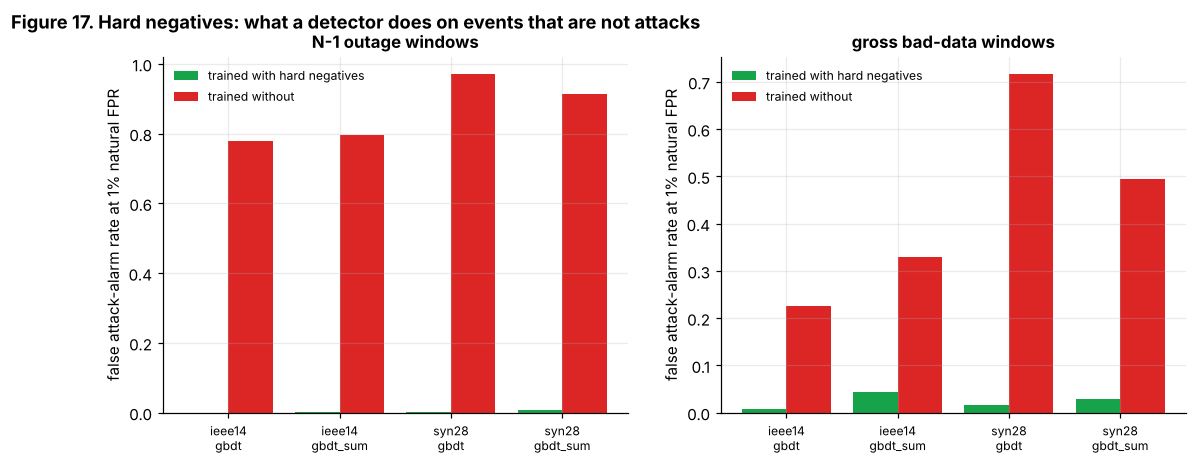

PosixPath('/tmp/w2/proj/figures/fig17_hard_negatives.png')

In [37]:
def gen_hardneg_test(name, n=300):
    sim, cal = SIMS[name], CAL[name]; rng = rng_for("hn_test", *[ord(c) for c in name])
    out = {}
    for kind in ("outage", "outlier"):
        X, J, R = [], [], []
        while len(X) < n:
            s = new_sample(sim, rng, kind)
            if s is None: continue
            z, V, _ = s; xh, j, r = sim.estimate(z); X.append(xh); J.append(j); R.append(np.max(np.abs(r) / sim.mt["sigma"]))
        out[kind] = dict(x=np.array(X), J=np.array(J), rmax=np.array(R))
    return out

h14_rows = []
for name in STUDY_GRIDS:
    cal, test, pool = CAL[name], DS[name]["test"], pool_for(name); hn = gen_hardneg_test(name)
    nat = test["kind"] == "natural"
    for Dcls in (GBDT, GBDTSum):
        for seed in range(SIZES["n_budget_seeds"]):
            sub = subsample_balanced(pool, H2_BUDGET, np.random.default_rng(555 + seed))
            for tag, tr_ in [("with", sub), ("without", drop_hard_negatives(sub))]:
                det = Dcls().fit(cal, tr_, seed)
                thr = np.quantile(det.score(cal, test)[nat & (test["label"] == 0)], 0.99)
                fa = {k: float(np.mean(det.score(cal, v) > thr)) for k, v in hn.items()}
                h14_rows.append(dict(grid=name, det=det.name, seed=seed, training=tag, fa_outage=fa["outage"], fa_outlier=fa["outlier"]))
H14 = pd.DataFrame(h14_rows)
piv = H14.groupby(["grid", "det", "training"])[["fa_outage", "fa_outlier"]].mean().unstack("training").round(3)
print(piv.to_string())
w_, wo_ = H14[H14.training == "with"], H14[H14.training == "without"]
H14_ratio = float(wo_.fa_outage.mean() / max(w_.fa_outage.mean(), 1e-3)); print(f"\nmean outage alarm rate: with {w_.fa_outage.mean():.3f}, without {wo_.fa_outage.mean():.3f}, ratio {H14_ratio:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, ttl in zip(axes, ["fa_outage", "fa_outlier"], ["N-1 outage windows", "gross bad-data windows"]):
    tab = H14.groupby(["grid", "det", "training"])[col].mean().unstack("training")
    x_ = np.arange(len(tab)); ax.bar(x_ - 0.2, tab["with"], 0.4, color=PAL["green"], label="trained with hard negatives")
    ax.bar(x_ + 0.2, tab["without"], 0.4, color=PAL["red"], label="trained without")
    ax.set_xticks(x_); ax.set_xticklabels([f"{g}\n{d}" for g, d in tab.index], fontsize=8); ax.set_ylabel("false attack-alarm rate at 1% natural FPR"); ax.set_title(ttl); ax.legend(fontsize=8)
fig.suptitle("Figure 17. Hard negatives: what a detector does on events that are not attacks", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig17_hard_negatives")

## Part 12. From detection to damage: the LFC plant

F1 and AUROC say how well a detector separates attacks from clean windows. They do not say *what the attacker gets away with*. In load-frequency control, a stealth shift of the state estimate that fakes a tie-line flow reading is fed into the area control error (ACE), so the automatic generation control (AGC) tries to "correct" a flow imbalance that does not exist. The physical result is a frequency excursion.

### 12.1 A two-area LFC model

Standard linearised two-area model (per area: inertia $2H$, damping $D$, governor $T_g$ with droop $R$, turbine $T_t$, integral AGC with gain $K_i$ acting on $\mathrm{ACE}_i=B_i\Delta f_i\pm(\Delta P_{tie}+b)$), coupled by a synchronising tie-line with coefficient $T_{12}$. The attack enters as a bias $b$ on the tie-line reading used by both areas' ACE. The plant is linear, so peak damage scales linearly with $b$ and we only need the response to a unit bias.

Parameters follow common textbook values; $K_i$ is chosen so that the nominal loop is stable and reasonably damped (checked below by eigenvalues). The plant is a stand-in for the NL-LFC plant of the earlier project (which has eight nonlinearities); using the linear one keeps the damage ceiling in closed form, and its limitations are stated in the scorecard.

In [38]:
from scipy import signal
LFC = dict(H=(5.0, 5.0), D=(1.0, 1.0), R=(0.05, 0.05), Tg=(0.2, 0.2), Tt=(0.5, 0.5), Ki=(0.12, 0.12), T12=0.2, f0=60.0)

def lfc_ss(P=LFC):
    H, D, R, Tg, Tt, Ki = [np.array(P[k]) for k in ("H", "D", "R", "Tg", "Tt", "Ki")]; T12 = P["T12"]
    B = 1 / R + D
    A = np.zeros((9, 9)); Bm = np.zeros((9, 1))
    # states: [df1, Pm1, Pv1, Pref1, df2, Pm2, Pv2, Pref2, Ptie]
    for a, o in ((0, 0), (1, 4)):
        i = o
        A[i, i] = -D[a] / (2 * H[a]); A[i, i + 1] = 1 / (2 * H[a])
        A[i + 1, i + 1] = -1 / Tt[a]; A[i + 1, i + 2] = 1 / Tt[a]
        A[i + 2, i] = -1 / (R[a] * Tg[a]); A[i + 2, i + 2] = -1 / Tg[a]; A[i + 2, i + 3] = 1 / Tg[a]
        sgn = 1.0 if a == 0 else -1.0                # tie flow leaves area 1 and enters area 2
        A[i, 8] = -sgn / (2 * H[a])
        A[i + 3, i] = -Ki[a] * B[a]; A[i + 3, 8] = -Ki[a] * sgn; Bm[i + 3, 0] = -Ki[a] * sgn
    A[8, 0] = 2 * np.pi * T12; A[8, 4] = -2 * np.pi * T12
    C = np.zeros((5, 9)); C[0, 0] = 1; C[1, 4] = 1
    C[2, 0] = B[0]; C[2, 8] = 1; C[3, 4] = B[1]; C[3, 8] = -1; C[4, 8] = 1
    Dm = np.zeros((5, 1)); Dm[2, 0] = 1; Dm[3, 0] = -1
    return signal.StateSpace(A, Bm, C, Dm)

ss = lfc_ss(); ev = np.linalg.eigvals(ss.A)
print("max real part of eigenvalues:", ev.real.max().round(4), "(must be < 0)   slowest damping ratio:",
      round(float(np.min(-ev.real / np.abs(ev))), 3))
assert ev.real.max() < 0
tt = np.linspace(0, 300, 3001)
_, yy, _ = signal.lsim(ss, U=np.ones_like(tt), T=tt)
G_f = float(np.max(np.abs(yy[:, :2])) * LFC["f0"])        # Hz of peak frequency deviation per unit (pu) tie-line bias
G_ace = float(np.max(np.abs(yy[:, 2:4])))
print(f"peak |df| per 1 pu fake tie-line bias: {G_f:.3f} Hz;  peak |ACE|: {G_ace:.3f} pu")

max real part of eigenvalues: -0.1198 (must be < 0)   slowest damping ratio: 0.265
peak |df| per 1 pu fake tie-line bias: 1.079 Hz;  peak |ACE|: 1.000 pu


### 12.2 The plant and the attack's footprint (Figure 18)

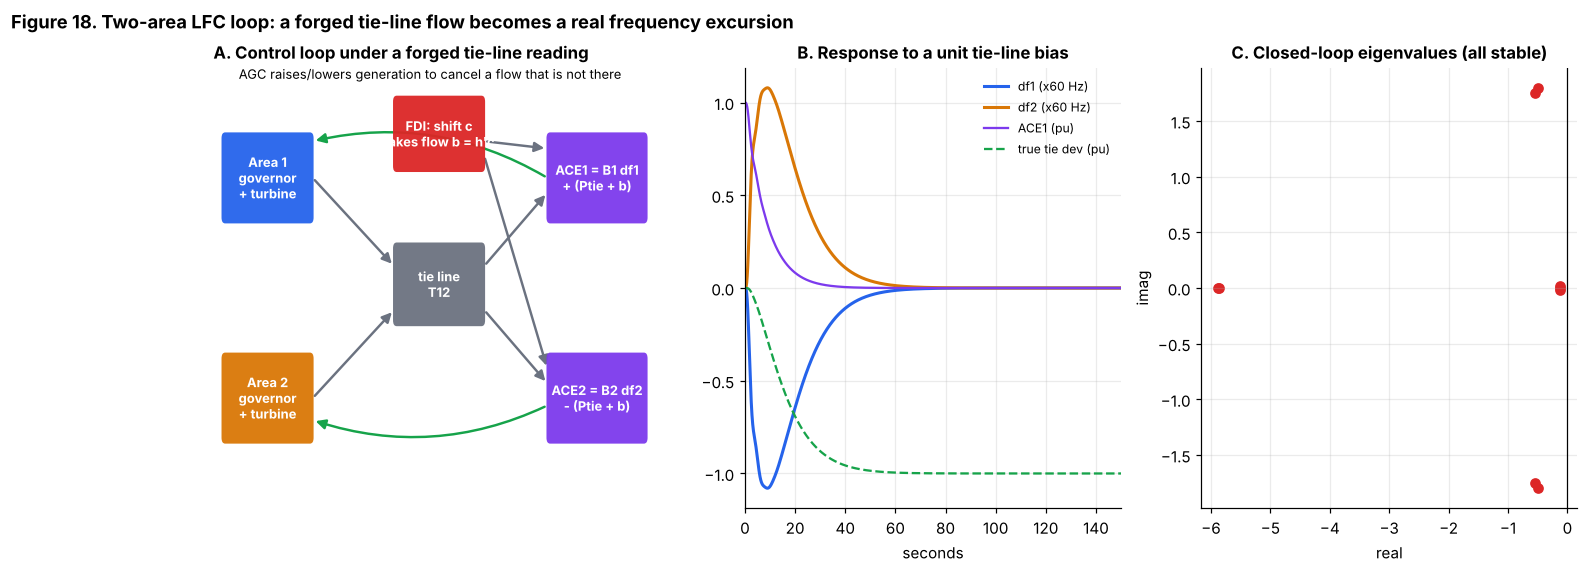

PosixPath('/tmp/w2/proj/figures/fig18_lfc_plant.png')

In [39]:
fig = plt.figure(figsize=(16, 5.2)); gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1, 1])
ax = fig.add_subplot(gs[0]); ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off"); ax.set_title("A. Control loop under a forged tie-line reading", loc="left")
box(ax, (0.2, 3.9), 2.0, 1.2, "Area 1\ngovernor\n+ turbine", PAL["blue"], 8.5); box(ax, (0.2, 0.9), 2.0, 1.2, "Area 2\ngovernor\n+ turbine", PAL["amber"], 8.5)
box(ax, (4.0, 2.5), 2.0, 1.1, "tie line\nT12", PAL["grey"], 8.5); box(ax, (7.4, 3.9), 2.2, 1.2, "ACE1 = B1 df1\n+ (Ptie + b)", PAL["purple"], 8.5)
box(ax, (7.4, 0.9), 2.2, 1.2, "ACE2 = B2 df2\n- (Ptie + b)", PAL["purple"], 8.5)
box(ax, (4.0, 4.6), 2.0, 1.0, "FDI: shift c\nfakes flow b = h'c", PAL["red"], 8.5)
for p0, p1 in [((2.2, 4.5), (4.0, 3.3)), ((2.2, 1.5), (4.0, 2.7)), ((6.0, 3.3), (7.4, 4.3)), ((6.0, 2.7), (7.4, 1.7)), ((6.0, 5.0), (7.4, 4.9)), ((6.0, 4.8), (7.4, 1.9))]:
    arrow(ax, p0, p1)
arrow(ax, (7.4, 4.5), (2.2, 5.0), color=PAL["green"], rad=0.2); arrow(ax, (7.4, 1.4), (2.2, 1.2), color=PAL["green"], rad=-0.2)
ax.text(4.8, 5.85, "AGC raises/lowers generation to cancel a flow that is not there", fontsize=8.5, ha="center")
ax = fig.add_subplot(gs[1])
for k, (nm, col) in enumerate([("df1 (x60 Hz)", PAL["blue"]), ("df2 (x60 Hz)", PAL["amber"])]): ax.plot(tt, yy[:, k] * LFC["f0"], color=col, label=nm, lw=2)
ax.plot(tt, yy[:, 2], color=PAL["purple"], label="ACE1 (pu)", lw=1.5); ax.plot(tt, yy[:, 4], color=PAL["green"], label="true tie dev (pu)", lw=1.5, ls="--")
ax.set_xlim(0, 150); ax.set_xlabel("seconds"); ax.set_title("B. Response to a unit tie-line bias"); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[2]); ax.scatter(ev.real, ev.imag, color=PAL["red"], s=36); ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("real"); ax.set_ylabel("imag"); ax.set_title("C. Closed-loop eigenvalues (all stable)")
fig.suptitle("Figure 18. Two-area LFC loop: a forged tie-line flow becomes a real frequency excursion", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig18_lfc_plant")

### 12.3 The damage ceiling, checked on the data (Figure 19)

For a grid with fake-flow sensitivity $h$ and clean covariance $\Sigma$, any attack of hardness $\delta$ fakes at most $\delta\sqrt{h^\top\Sigma h}$ of tie-line flow (Part 2). Scaled to the LFC area base, and multiplied by the plant's peak-frequency gain $G_f$, this is a **damage ceiling** that holds against every detector, since hardness is a property of the attack, not of the detector. Two checks: (i) no realised attack exceeds the ceiling; (ii) `lfc`-direction attacks sit near it when the attacker's model of the grid is exact (`ac` model), so the ceiling is attainable and not a loose bound. A *linear* attacker (stale Jacobian) leaks energy into the tight directions of $\Sigma$, so its *realised* hardness is much larger than the hardness it aimed for; it therefore lands well below the ceiling at its realised hardness. That is a finding about imperfect attackers, not a bug.

  grid  max_ratio_to_ceiling  lfc_ac_median_ratio  lfc_linear_median_ratio  sparse_median_ratio
ieee14                   1.0                  1.0                    0.490                0.002
 syn28                   1.0                  1.0                    0.289                0.000


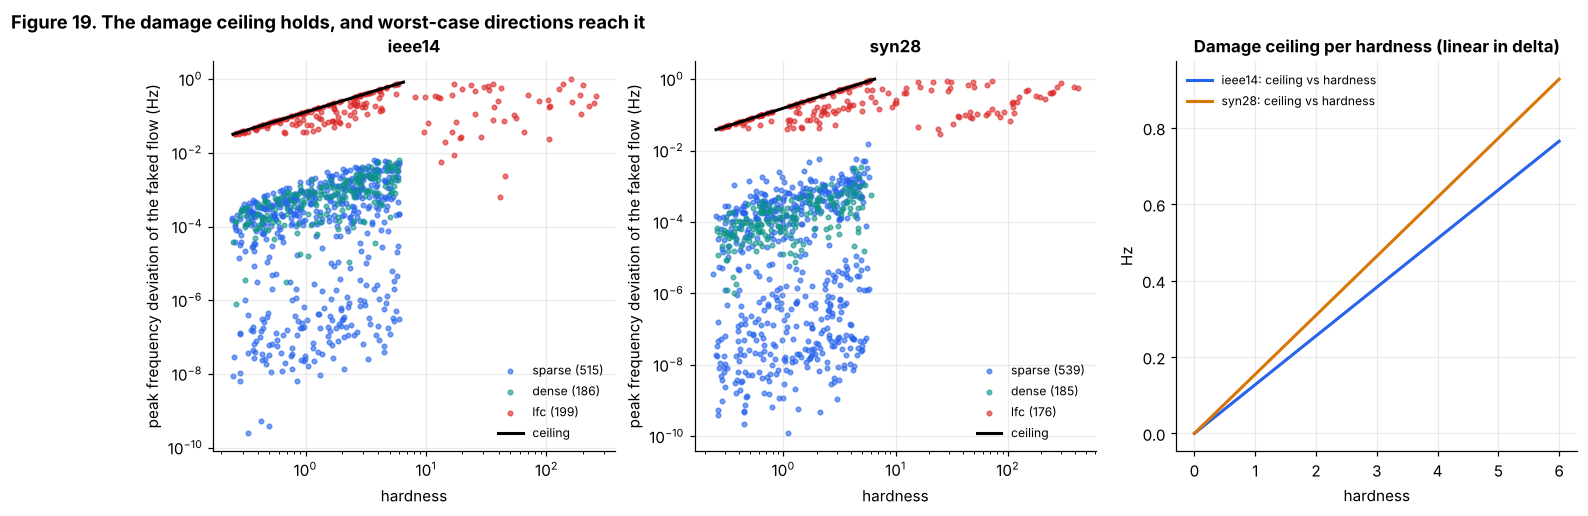

In [40]:
def area_base_MW(g): return 0.5 * g.Pd.sum()
def flow_to_Hz(g, flow_pu): return np.abs(flow_pu) * g.baseMVA / area_base_MW(g) * G_f

ceil_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, name in zip(axes[:2], STUDY_GRIDS):
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]; ia = te["label"] == 1
    sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie))
    dl, fl, dk, mdl = te["delta"][ia], np.abs(te["flow"][ia]), te["dirkind"][ia], te["model"][ia]
    ratio = fl / (dl * sq)
    for kind, col in [("sparse", PAL["blue"]), ("dense", PAL["teal"]), ("lfc", PAL["red"])]:
        m = dk == kind; ax.scatter(dl[m], flow_to_Hz(sim.g, fl[m]), s=9, alpha=0.6, color=col, label=f"{kind} ({m.sum()})")
    xx = np.linspace(0.25, 6.5, 100); ax.plot(xx, flow_to_Hz(sim.g, xx * sq), "k-", lw=2, label="ceiling")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("hardness"); ax.set_ylabel("peak frequency deviation of the faked flow (Hz)"); ax.set_title(name); ax.legend(fontsize=8)
    ceil_rows.append(dict(grid=name, max_ratio_to_ceiling=ratio.max(), lfc_ac_median_ratio=np.median(ratio[(dk == "lfc") & (mdl == "ac")]), lfc_linear_median_ratio=np.median(ratio[(dk == "lfc") & (mdl == "linear")]), sparse_median_ratio=np.median(ratio[dk == "sparse"])))
print(pd.DataFrame(ceil_rows).round(3).to_string(index=False))
ax = axes[2]
for name, col in zip(STUDY_GRIDS, [PAL["blue"], PAL["amber"]]):
    sim, cal = SIMS[name], CAL[name]; sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie)); dd = np.linspace(0, 6, 100)
    ax.plot(dd, flow_to_Hz(sim.g, dd * sq), color=col, lw=2, label=f"{name}: ceiling vs hardness")
ax.set_xlabel("hardness"); ax.set_ylabel("Hz"); ax.set_title("Damage ceiling per hardness (linear in delta)"); ax.legend(fontsize=8)
fig.suptitle("Figure 19. The damage ceiling holds, and worst-case directions reach it", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig19_damage_ceiling")
assert max(r["max_ratio_to_ceiling"] for r in ceil_rows) < 1.02, "an attack exceeded the damage ceiling"

### 12.4 Damage at budget, and whether it ranks detectors differently from AUROC (H4, Figure 20)

For a detector with threshold fixed at 1% false alarms on natural clean windows, the **expected evaded damage** is

$$\mathbb E[\,\text{damage}\cdot\mathbf 1(\text{attack not alarmed})\,]$$

over the test attacks, with damage measured as the peak frequency deviation (Hz) the faked flow produces. It answers "how much harm do attacks do *after* this detector has done its job?". H4 asks whether ranking the nine detectors by this number gives a different order from ranking them by overall AUROC (Spearman correlation below 0.8).

  grid       det    auc  evaded_damage_mHz  damage_prevented_share  evasion_rate
ieee14 hotelling 0.5989            27.8924                  0.3747        0.9211
ieee14 pca_recon 0.5154            29.9075                  0.3295        0.9367
ieee14   iforest 0.5834            28.9303                  0.3514        0.9244
ieee14      chi2 0.4975            29.0050                  0.3497        0.9411
ieee14    logreg 0.5370            31.1146                  0.3024        0.9511
ieee14      gbdt 0.6334            27.6123                  0.3810        0.9389
ieee14       mlp 0.5729            20.7173                  0.5355        0.9200
ieee14  gbdt_sum 0.6186            34.9792                  0.2158        0.8678
ieee14   mlp_sum 0.6447            28.8691                  0.3528        0.9378
 syn28 hotelling 0.5518            31.7303                  0.4071        0.9244
 syn28 pca_recon 0.4985            39.2669                  0.2662        0.9578
 syn28   iforest 0.5502     

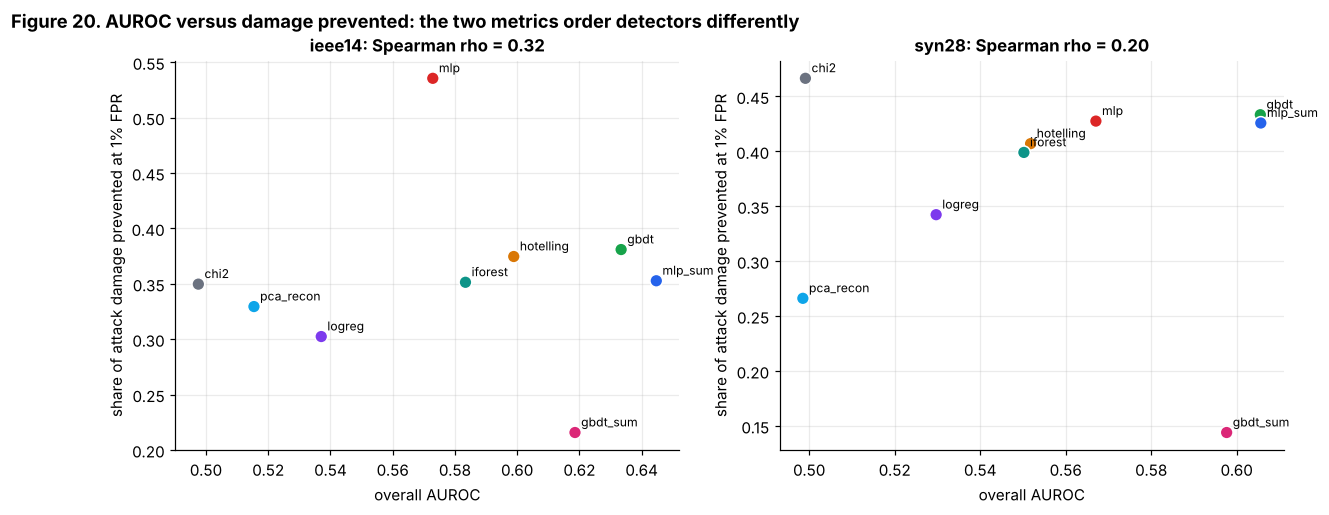

PosixPath('/tmp/w2/proj/figures/fig20_auc_vs_damage.png')

In [41]:
from scipy.stats import spearmanr
def evaded_damage(name, score, test, fpr=0.01):
    nat = (test["kind"] == "natural") & (test["label"] == 0)
    thr = np.quantile(score[nat], 1 - fpr); ia = test["label"] == 1
    dmg = flow_to_Hz(SIMS[name].g, test["flow"][ia]); ev_ = score[ia] <= thr
    return float(np.mean(dmg * ev_)), float(np.mean(dmg)), float(np.mean(ev_))

dm_rows = []
for name in STUDY_GRIDS:
    test = DS[name]["test"]
    for d_, s in INGRID_SCORES[name].items():
        e, tot, evr = evaded_damage(name, s, test)
        dm_rows.append(dict(grid=name, det=d_, auc=overall_auc(s, test), evaded_damage_mHz=1000 * e, damage_prevented_share=1 - e / tot, evasion_rate=evr))
DM = pd.DataFrame(dm_rows)
rho = {g: spearmanr(DM[DM.grid == g].auc, -DM[DM.grid == g].evaded_damage_mHz)[0] for g in STUDY_GRIDS}
print(DM.round(4).to_string(index=False)); print("\nSpearman(AUROC, -evaded damage):", {k: round(v, 3) for k, v in rho.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, name in zip(axes, STUDY_GRIDS):
    v = DM[DM.grid == name]
    ax.scatter(v.auc, v.damage_prevented_share, s=70, c=[DET_COLORS[d] for d in v.det], edgecolor="white", zorder=3)
    for _, r in v.iterrows(): ax.annotate(r.det, (r.auc, r.damage_prevented_share), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("overall AUROC"); ax.set_ylabel("share of attack damage prevented at 1% FPR"); ax.set_title(f"{name}: Spearman rho = {rho[name]:.2f}")
fig.suptitle("Figure 20. AUROC versus damage prevented: the two metrics order detectors differently", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig20_auc_vs_damage")

## Part 13. Methods layer

Three methods, each a known technique applied to this problem with the oracle framing. None is a new architecture, and the paper should not claim that. Each has a stated claim and a way to fail.

| | Method | Idea | Pre-registered claim |
|---|---|---|---|
| A | Hardness-stratified training | Sample training attacks uniformly in log-hardness instead of uniformly in magnitude | H6: closes at least 20% more of the oracle gap at small hardness |
| B | Oracle distillation | A student that sees only measurements is trained on the oracle's *soft* posterior, computed with the privileged shift $c$ and $\Sigma$ | H7: beats a plain student at 1% and 5% label budgets |
| E | Conformal risk control on damage | Pick the alarm threshold so the *expected evaded damage* is bounded, rather than the false-alarm rate | H8: realised risk stays under budget in at least 95% of calibration splits |

### 13.1 Method A: hardness-stratified training (Figure 21)

Both arms see **the same clean windows** and the same number of attack windows. They differ only in how attack sizes were drawn: log-uniform hardness versus uniform state-unit magnitude (Figure 8C shows how different the resulting hardness distributions are). The gap closure is $(\text{gap}_{\rm mag}-\text{gap}_{\rm strat})/\text{gap}_{\rm mag}$ at hardness 0.5 to 2, with the gap measured to the empirical oracle.

                 auc_strat  auc_mag  oracle  closure
grid   det                                          
ieee14 gbdt          0.559    0.519   0.752    0.171
       gbdt_sum      0.555    0.527   0.752    0.120
       mlp_sum       0.557    0.564   0.752   -0.040
syn28  gbdt          0.539    0.526   0.755    0.054
       gbdt_sum      0.535    0.536   0.755   -0.007
       mlp_sum       0.536    0.546   0.755   -0.050

mean gap closure of stratified over uniform-magnitude training: 4.1%


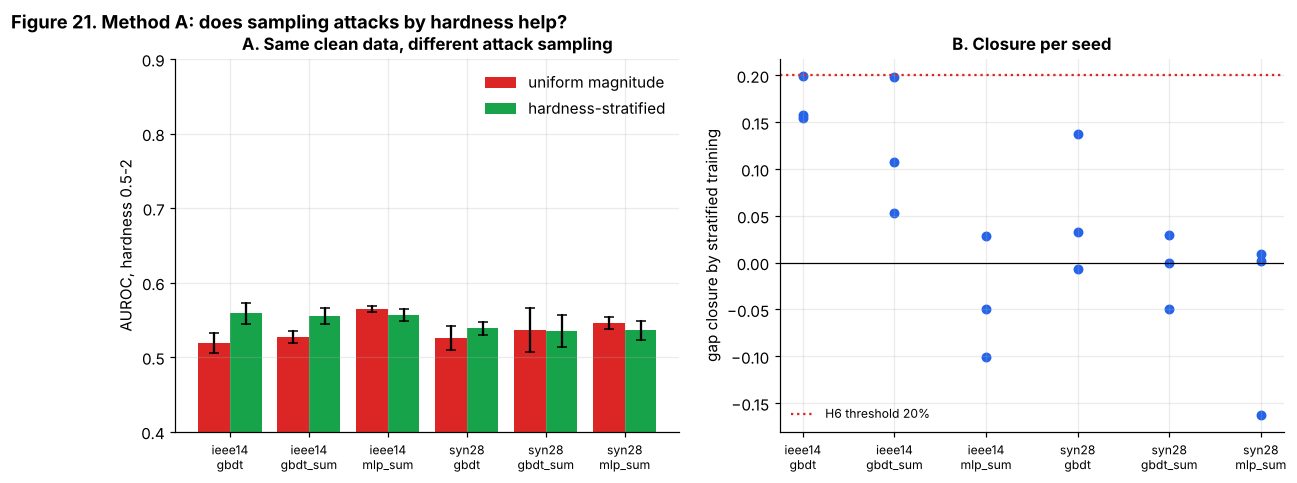

PosixPath('/tmp/w2/proj/figures/fig21_method_A.png')

In [42]:
THRESH["h6_closure"] = 0.20
def build_A_sets(name, seed, n_per):
    rng = np.random.default_rng(9000 + seed); tr = DS[name]["train"]; mg = DS[name]["train_mag"]
    ic = rng.choice(np.where(tr["label"] == 0)[0], n_per, replace=False)
    ia_s = rng.choice(np.where(tr["label"] == 1)[0], n_per, replace=False); ia_m = rng.choice(len(mg["label"]), min(n_per, len(mg["label"])), replace=False)
    clean = {k: v[ic] for k, v in tr.items()}
    strat = concat_blocks(clean, {k: v[ia_s] for k, v in tr.items()}); mag = concat_blocks(clean, {k: v[ia_m] for k, v in mg.items()})
    return strat, mag

N_PER_A = 600 if BUDGET == "full" else 150
A_rows = []
for name in STUDY_GRIDS:
    cal, te = CAL[name], DS[name]["test"]; orc = float(np.nanmean(oracle_by_bin(cal, te, np.array([0.5, 1.0, 2.0]))))
    for seed in range(SIZES["n_budget_seeds"]):
        strat, mag = build_A_sets(name, seed, N_PER_A)
        for Dcls in (GBDT, GBDTSum, MLPSum):
            r = {}
            for tag, tr_ in (("strat", strat), ("mag", mag)):
                det = Dcls().fit(cal, tr_, seed); r[tag] = small_auc(det.score(cal, te), te)
            A_rows.append(dict(grid=name, det=Dcls.name, seed=seed, auc_strat=r["strat"], auc_mag=r["mag"], oracle=orc,
                               closure=((orc - r["mag"]) - (orc - r["strat"])) / (orc - r["mag"])))
A = pd.DataFrame(A_rows)
print(A.groupby(["grid", "det"])[["auc_strat", "auc_mag", "oracle", "closure"]].mean().round(3).to_string())
H6_val = float(A.groupby(["grid", "det"]).closure.mean().mean()); print(f"\nmean gap closure of stratified over uniform-magnitude training: {H6_val:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
g_ = A.groupby(["grid", "det"])[["auc_strat", "auc_mag"]].mean(); s_ = A.groupby(["grid", "det"])[["auc_strat", "auc_mag"]].std()
x_ = np.arange(len(g_)); ax.bar(x_ - 0.2, g_.auc_mag, 0.4, yerr=s_.auc_mag, color=PAL["red"], capsize=3, label="uniform magnitude")
ax.bar(x_ + 0.2, g_.auc_strat, 0.4, yerr=s_.auc_strat, color=PAL["green"], capsize=3, label="hardness-stratified")
ax.set_xticks(x_); ax.set_xticklabels([f"{a}\n{b}" for a, b in g_.index], fontsize=8); ax.set_ylim(0.4, 0.9); ax.set_ylabel("AUROC, hardness 0.5-2"); ax.legend(); ax.set_title("A. Same clean data, different attack sampling")
ax = axes[1]
for (g, d), v in A.groupby(["grid", "det"]): ax.scatter([f"{g}\n{d}"] * len(v), v.closure, color=PAL["blue"], s=30)
ax.axhline(THRESH["h6_closure"], color=PAL["red"], ls=":", label="H6 threshold 20%"); ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("gap closure by stratified training"); ax.legend(fontsize=8)
ax.tick_params(axis="x", labelsize=8); ax.set_title("B. Closure per seed")
fig.suptitle("Figure 21. Method A: does sampling attacks by hardness help?", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig21_method_A")

### 13.2 Method B: oracle distillation (Figure 22)

**Teacher.** For a training window with state estimate $\hat x$ and (privileged) shift $c$, the oracle posterior that the window is "clean plus shift $c$" rather than clean, under the Gaussian shift model with equal priors, is $\sigma\!\big(\mathrm{LLR}\big)$ with $\mathrm{LLR}=c^\top\Sigma^{-1}(\hat x-\mu)-\tfrac12\delta^2$. For attacked windows $c$ is the true realised shift. A clean window has no shift, so it is paired with a *virtual* shift drawn from the training attacks, and its soft label is the posterior under that virtual direction (for a clean window this is usually near 0, but not exactly).

**Students.** Identical small MLPs on the summary view, with the same fixed hyperparameters and training schedule. The *plain* student regresses the hard 0/1 label; the *distilled* student regresses the teacher posterior. Both are scored by their raw output. Budgets are 1% and 5% of the largest pool (36 and 180 windows); five seeds.

The comparison isolates what the privileged signal adds per labelled window. It does **not** claim the teacher is available at deployment, only in simulation.

               auc_plain  auc_dist   gain
grid   budget                            
ieee14 36          0.503     0.481 -0.022
       180         0.541     0.545  0.004
syn28  36          0.532     0.518 -0.014
       180         0.530     0.518 -0.013

H7 readout: {36: {'mean_gain': -0.017844929070112852, 'frac_pos': 0.3}, 180: {'mean_gain': -0.0041268568033274115, 'frac_pos': 0.6}}


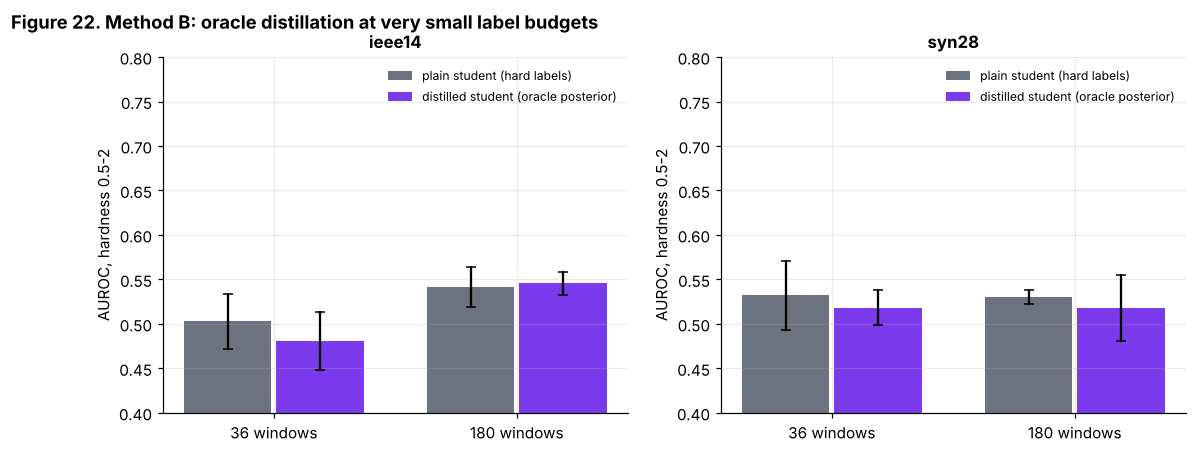

PosixPath('/tmp/w2/proj/figures/fig22_method_B.png')

In [43]:
THRESH["h7_min_pairs"] = 0.7
BUD_B = [36, 180] if BUDGET == "full" else [20, 60]
SEEDS_B = 5 if BUDGET == "full" else 3

def teacher_posterior(cal, d, rng):
    X = d["x"] - cal.mu; ia = np.where(d["label"] == 1)[0]
    C = d["shift"].copy()
    ic = np.where(d["label"] == 0)[0]; C[ic] = d["shift"][rng.choice(ia, len(ic))]       # virtual shifts for clean windows
    llr = np.einsum("ij,jk,ik->i", C, cal.Sinv, X) - 0.5 * cal.delta(C) ** 2
    return 1 / (1 + np.exp(-np.clip(llr, -30, 30)))

def fit_student(Xf, target, seed, regress=True):
    sc = StandardScaler().fit(Xf)
    kw = dict(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3, max_iter=600, random_state=seed)
    m = (MLPRegressor(**kw) if regress else MLPClassifier(**kw)).fit(sc.transform(Xf), target)
    return lambda F: (m.predict(sc.transform(F)) if regress else m.predict_proba(sc.transform(F))[:, 1])

B_rows = []
for name in STUDY_GRIDS:
    cal, te, pool = CAL[name], DS[name]["test"], pool_for(name); Fte = summary_features(cal, te)
    for b in BUD_B:
        for seed in range(SEEDS_B):
            sub = subsample_balanced(pool, b, np.random.default_rng(31 * seed + b)); F = summary_features(cal, sub)
            tp = teacher_posterior(cal, sub, np.random.default_rng(seed))
            plain = fit_student(F, sub["label"], seed, regress=False); dist = fit_student(F, tp, seed, regress=True)
            B_rows.append(dict(grid=name, budget=b, seed=seed, auc_plain=small_auc(plain(Fte), te), auc_dist=small_auc(dist(Fte), te),
                               all_plain=overall_auc(plain(Fte), te), all_dist=overall_auc(dist(Fte), te)))
B = pd.DataFrame(B_rows); B["gain"] = B.auc_dist - B.auc_plain
print(B.groupby(["grid", "budget"])[["auc_plain", "auc_dist", "gain"]].mean().round(3).to_string())
H7 = {int(b): dict(mean_gain=float(v.gain.mean()), frac_pos=float((v.gain > 0).mean())) for b, v in B.groupby("budget")}; print("\nH7 readout:", H7)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, name in zip(axes, STUDY_GRIDS):
    v = B[B.grid == name]; xs_ = np.arange(len(BUD_B))
    for k, (col, lab) in enumerate([("auc_plain", "plain student (hard labels)"), ("auc_dist", "distilled student (oracle posterior)")]):
        m = [v[v.budget == b][col].mean() for b in BUD_B]; s = [v[v.budget == b][col].std() for b in BUD_B]
        ax.bar(xs_ + (k - 0.5) * 0.38, m, 0.36, yerr=s, capsize=3, color=[PAL["grey"], PAL["purple"]][k], label=lab)
    ax.set_xticks(xs_); ax.set_xticklabels([f"{b} windows" for b in BUD_B]); ax.set_ylim(0.4, 0.8); ax.set_ylabel("AUROC, hardness 0.5-2"); ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle("Figure 22. Method B: oracle distillation at very small label budgets", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig22_method_B")

### 13.3 Method E: conformal risk control on evaded damage (Figure 23)

**Setup.** Only attacks aimed at the tie line (`lfc` direction) by an attacker with an exact grid model (`ac`) are used. Linear attackers with a stale Jacobian realise far higher hardness than intended and are caught easily, so they would make a damage budget vacuous: sparse and dense attacks fake almost no tie-line flow (their damage is under 1% of the ceiling), so a damage budget on them is vacuous, and with so small an $\alpha$ the finite-sample term $1/(n+1)$ alone would exceed it. For a detector with score $s$ (alarm when $s>\lambda$), define for an attack $i$ with damage $D_i$ (peak frequency deviation) the loss

$$L_i(\lambda)=\frac{D_i}{D_{\max}}\,\mathbf 1\{s_i\le\lambda\}\in[0,1],$$

the normalised damage of an attack that *evades* the threshold. It is non-decreasing in $\lambda$, which is the monotonicity conformal risk control needs. $D_{\max}$ is the damage ceiling at the largest realised hardness among test attacks (at least 6.5). Any constant that bounds the loss in $[0,1]$ is valid; a larger one only makes the guarantee looser through the $1/(n+1)$ term.

**Rule.** With $n$ calibration attacks, choose the largest threshold satisfying

$$\tfrac{n}{n+1}\,\hat R_n(\lambda)+\tfrac{1}{n+1}\le\alpha,\qquad \hat R_n(\lambda)=\tfrac1n\sum_i L_i(\lambda).$$

The guarantee (Angelopoulos et al., conformal risk control) is on the **expected** loss of a new exchangeable attack: $\mathbb E[L_{n+1}(\hat\lambda)]\le\alpha$. I have not re-verified the exact statement of the assumptions from the full paper in this session, so the checks below are *empirical*: (i) is the average realised risk under $\alpha$, and (ii) in what fraction of individual calibration splits is the realised risk under $\alpha$?

H8 as pre-registered is the **stricter, per-split** statement (ii) at 95%. The expectation-level guarantee does not imply it, and the readout below shows both.

  grid       det  alpha  mean_risk  frac_splits_under  mean_fpr  risk_at_1pct_fpr  no_detector_risk
ieee14 hotelling 0.1307     0.1032             0.8125    0.2239            0.2550            0.2614
ieee14  gbdt_sum 0.1307     0.1028             0.7600    0.3747            0.2606            0.2614
ieee14      gbdt 0.1307     0.1038             0.7300    0.3094            0.1733            0.2614
 syn28 hotelling 0.1448     0.1143             0.8250    0.3914            0.2897            0.2897
 syn28  gbdt_sum 0.1448     0.1110             0.7500    0.6597            0.2890            0.2897
 syn28      gbdt 0.1448     0.1170             0.7200    0.2450            0.2262            0.2897

H8 readout: {'mean_risk_under_alpha': True, 'frac_splits_under': 0.76625, 'mean_fpr': 0.36734543697933897, 'vacuous': False}


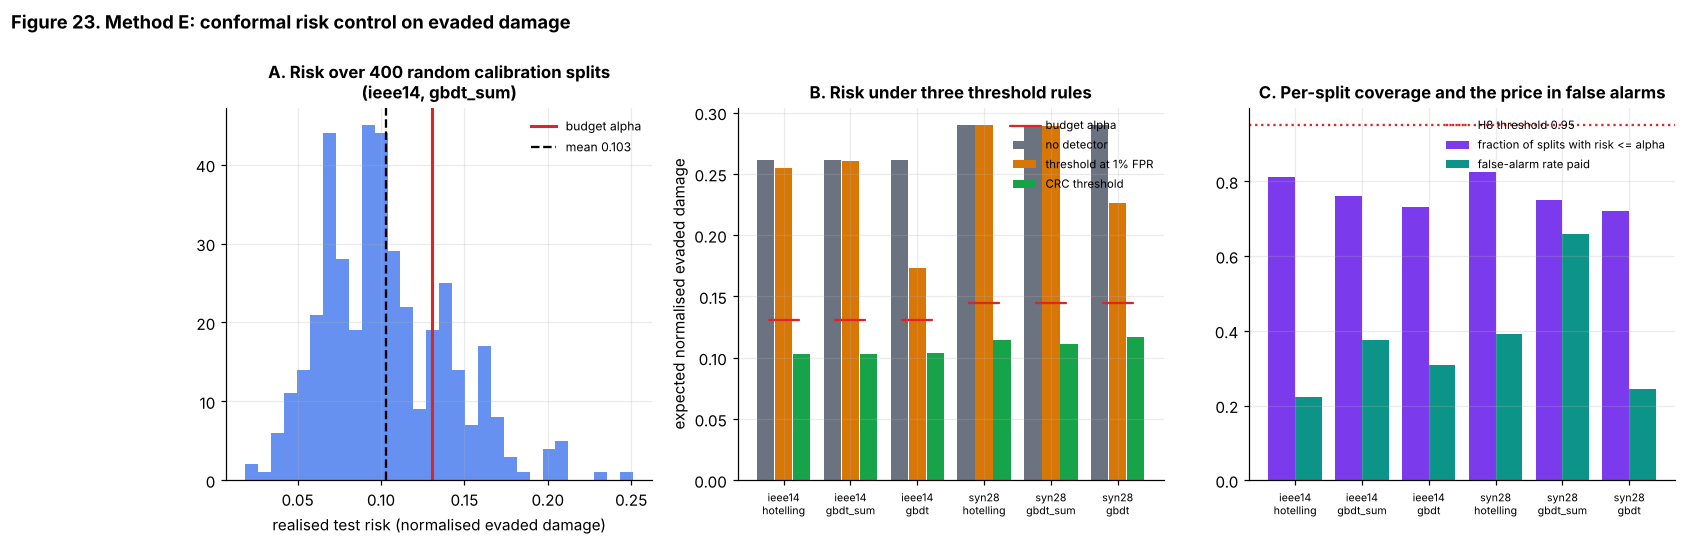

PosixPath('/tmp/w2/proj/figures/fig23_method_E.png')

In [44]:
import zlib
THRESH["h8_cov"] = 0.95
def crc_threshold(scores_att, loss_w, alpha):
    """Largest lambda with (n/(n+1)) R_hat(lambda) + 1/(n+1) <= alpha. loss_w = D_i / D_max in [0,1]."""
    n = len(scores_att); o = np.argsort(scores_att); s = scores_att[o]; w = loss_w[o]
    cum = np.cumsum(w)                       # R_hat(lambda=s_k) = cum[k]/n  (loss of attacks with score <= s_k)
    ok = (n / (n + 1)) * (cum / n) + 1 / (n + 1) <= alpha
    if not ok.any(): return -np.inf          # even the smallest threshold cannot meet alpha: alarm on everything
    return s[np.where(ok)[0].max()]

crc_rows = []; crc_curves = {}
N_SPLITS = 400
for name in STUDY_GRIDS:
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]; ia = np.where((te["label"] == 1) & (te["dirkind"] == "lfc") & (te["model"] == "ac"))[0]
    sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie)); dcap = max(6.5, float(te['delta'][ia].max())); Dmax = float(flow_to_Hz(sim.g, dcap * sq))
    dmg = flow_to_Hz(sim.g, te["flow"][ia]) / Dmax
    assert dmg.max() <= 1.0 + 1e-9
    alpha = 0.5 * dmg.mean()                  # target: halve the damage an undetected attacker would do
    for det in ("hotelling", "gbdt_sum", "gbdt"):
        s_all = INGRID_SCORES[name][det]; s_att = s_all[ia]; nat = (te["kind"] == "natural") & (te["label"] == 0)
        risks, fprs = [], []; rng = np.random.default_rng(3 + zlib.crc32((name + det).encode()) % 1000)
        for _ in range(N_SPLITS):
            perm = rng.permutation(len(ia)); cal_i, test_i = perm[: len(ia) // 2], perm[len(ia) // 2:]
            lam = crc_threshold(s_att[cal_i], dmg[cal_i], alpha)
            risks.append(float(np.mean(dmg[test_i] * (s_att[test_i] <= lam)))); fprs.append(float(np.mean(s_all[nat] > lam)))
        risks, fprs = np.array(risks), np.array(fprs)
        thr1 = np.quantile(s_all[nat], 0.99); risk_fpr = float(np.mean(dmg * (s_att <= thr1)))
        crc_rows.append(dict(grid=name, det=det, alpha=alpha, mean_risk=risks.mean(), frac_splits_under=float(np.mean(risks <= alpha)),
                             mean_fpr=fprs.mean(), risk_at_1pct_fpr=risk_fpr, no_detector_risk=float(dmg.mean())))
        crc_curves[(name, det)] = (risks, alpha)
CRC = pd.DataFrame(crc_rows); print(CRC.round(4).to_string(index=False))
H8 = dict(mean_risk_under_alpha=bool((CRC.mean_risk <= CRC.alpha).all()), frac_splits_under=float(CRC.frac_splits_under.mean()), mean_fpr=float(CRC.mean_fpr.mean()), vacuous=bool(CRC.mean_fpr.mean() > 0.5))
print("\nH8 readout:", H8)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]; k_ = ("ieee14", "gbdt_sum"); r_, a_ = crc_curves[k_]
ax.hist(r_, bins=30, color=PAL["blue"], alpha=0.7); ax.axvline(a_, color=PAL["red"], lw=2, label="budget alpha"); ax.axvline(r_.mean(), color="k", ls="--", label=f"mean {r_.mean():.3f}")
ax.set_xlabel("realised test risk (normalised evaded damage)"); ax.set_title("A. Risk over 400 random calibration splits\n(ieee14, gbdt_sum)"); ax.legend(fontsize=8)
ax = axes[1]
lab = [f"{g}\n{d}" for g, d in zip(CRC.grid, CRC.det)]; x_ = np.arange(len(CRC))
ax.bar(x_ - 0.27, CRC.no_detector_risk, 0.26, color=PAL["grey"], label="no detector"); ax.bar(x_, CRC.risk_at_1pct_fpr, 0.26, color=PAL["amber"], label="threshold at 1% FPR")
ax.bar(x_ + 0.27, CRC.mean_risk, 0.26, color=PAL["green"], label="CRC threshold"); ax.scatter(x_, CRC.alpha, marker="_", s=400, color=PAL["red"], zorder=5, label="budget alpha")
ax.set_xticks(x_); ax.set_xticklabels(lab, fontsize=7); ax.set_ylabel("expected normalised evaded damage"); ax.legend(fontsize=7.5); ax.set_title("B. Risk under three threshold rules")
ax = axes[2]
ax.bar(x_ - 0.2, CRC.frac_splits_under, 0.4, color=PAL["purple"], label="fraction of splits with risk <= alpha"); ax.bar(x_ + 0.2, CRC.mean_fpr, 0.4, color=PAL["teal"], label="false-alarm rate paid")
ax.axhline(THRESH["h8_cov"], color=PAL["red"], ls=":", label="H8 threshold 0.95"); ax.set_xticks(x_); ax.set_xticklabels(lab, fontsize=7); ax.legend(fontsize=7.5); ax.set_title("C. Per-split coverage and the price in false alarms")
fig.suptitle("Figure 23. Method E: conformal risk control on evaded damage", x=0.01, y=1.08, ha="left", fontweight="bold")
savefig(fig, "fig23_method_E")

## Part 14. An adaptive attacker (H5)

Everything so far assumes the attacker does not know the detector. Here the attacker is given **white-box score access** to the deployed detector and a damage requirement, and chooses the attack direction to evade it.

**Attacker model.** In whitened coordinates $z=L^{-1}c$ (with $\Sigma=LL^\top$) the hardness is $\|z\|=\delta_0$, and the faked tie-line flow is $h^\top c=v^\top z$ with $v=L^\top h$, so the ceiling is $\|v\|\delta_0$. The attacker must reach at least a fraction $\rho$ of the ceiling:

$$z=\delta_0\big(\cos\varphi\,\hat v+\sin\varphi\,w\big),\qquad \cos\varphi=\rho,\quad w\perp\hat v,\ \|w\|=1 .$$

So hardness and damage are fixed, and the only freedom is the unit direction $w$ in the $(n_s-1)$-dimensional orthogonal complement. A clean-only quadratic test (Hotelling) has an expected score that depends on $\delta_0$ alone, so it should be indifferent to $w$. A supervised detector has learned *which* directions its training attacks occupied and may have blind spots.

**Protocol.** The attacker owns a set of natural windows $A$ and draws $K$ random directions $w$. It applies each to $A$ (adding $c$ to the state estimate and leaving the residual statistics untouched, as the exact-model attacker does) and picks the $w^\star$ with the lowest mean detector score. We then evaluate AUROC on a **disjoint** set of windows $T$. The non-adaptive reference is the mean AUROC over random $w$ at the same $(\delta_0,\rho)$. The *power loss* is reference minus adaptive AUROC. Selecting the best of $K$ candidates has a small optimism that also affects Hotelling, so Hotelling's loss is the control that shows how much of a loss is just selection noise.

H5 holds if the mean power loss of the supervised detectors exceeds Hotelling's.

ieee14 adaptive attacker done


syn28 adaptive attacker done


                        ref  adaptive   loss
grid   rho det                              
ieee14 0.5 gbdt       0.607     0.536  0.071
           gbdt_sum   0.525     0.520  0.005
           hotelling  0.572     0.567  0.004
           logreg     0.496     0.312  0.184
           mlp        0.543     0.377  0.166
           mlp_sum    0.541     0.534  0.007
       0.8 gbdt       0.652     0.628  0.024
           gbdt_sum   0.515     0.515 -0.000
           hotelling  0.572     0.566  0.005
           logreg     0.499     0.363  0.137
           mlp        0.566     0.442  0.124
           mlp_sum    0.554     0.551  0.003
syn28  0.5 gbdt       0.506     0.450  0.056
           gbdt_sum   0.508     0.510 -0.002
           hotelling  0.529     0.530 -0.001
           logreg     0.490     0.363  0.127
           mlp        0.477     0.382  0.095
           mlp_sum    0.511     0.508  0.003
       0.8 gbdt       0.515     0.489  0.026
           gbdt_sum   0.507     0.507  0.000
          

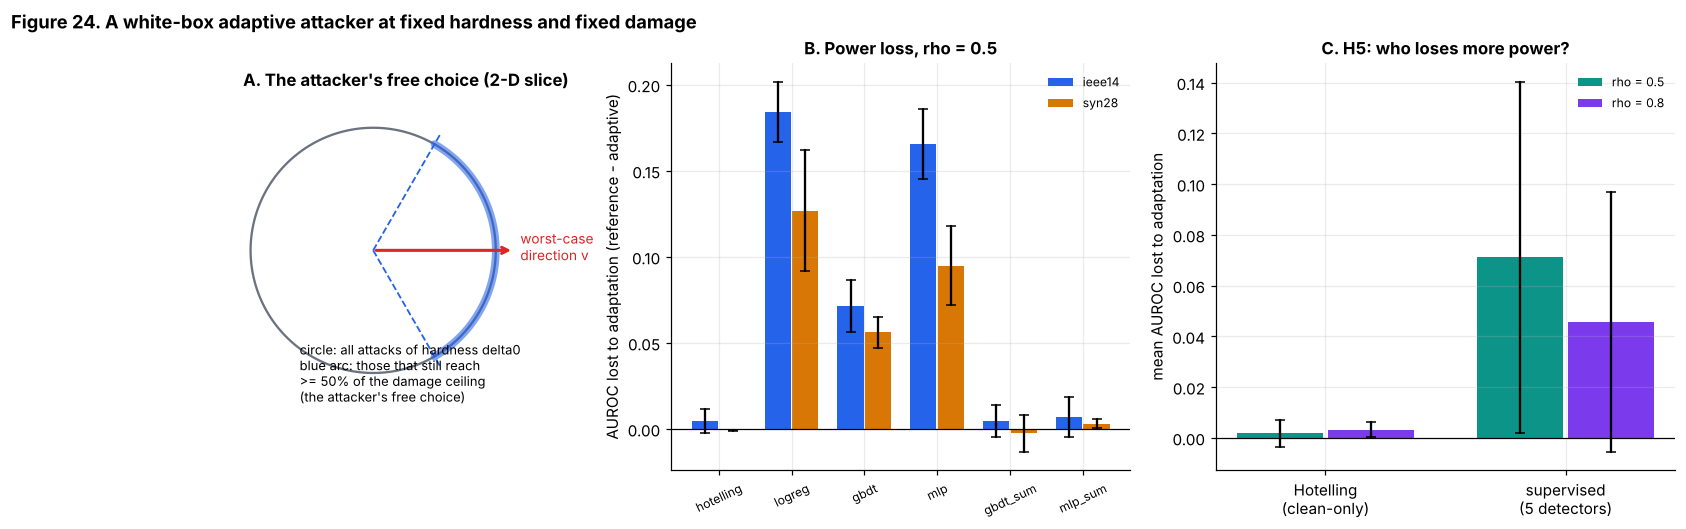

PosixPath('/tmp/w2/proj/figures/fig24_adaptive_attacker.png')

In [45]:
DELTA0, RHOS = 1.5, (0.5, 0.8)
K_CAND = 200 if BUDGET == "full" else 60
N_REF = 30 if BUDGET == "full" else 15
R_ADV = 3 if BUDGET == "full" else 2

def stacked_attack(cal, base, Zs, L):
    """Attack every base window with every whitened direction in Zs -> dict with len(Zs)*len(base) rows."""
    C = Zs @ L.T                                    # (K, ns) shifts in state units
    nb_, K = len(base["x"]), len(Zs)
    return dict(x=(base["x"][None] + C[:, None]).reshape(K * nb_, -1), J=np.tile(base["J"], K), rmax=np.tile(base["rmax"], K))

def auc_pair(s_att, s_clean):
    return roc_auc_score(np.r_[np.zeros(len(s_clean)), np.ones(len(s_att))], np.r_[s_clean, s_att])

def rand_perp(vhat, k, rng):
    W = rng.normal(size=(k, len(vhat))); W -= np.outer(W @ vhat, vhat)
    return W / np.linalg.norm(W, axis=1, keepdims=True)

ADV_ROWS = []
for name in STUDY_GRIDS:
    sim, cal, te, pool = SIMS[name], CAL[name], DS[name]["test"], pool_for(name)
    nat = {k: v[(te["kind"] == "natural") & (te["label"] == 0)] for k, v in te.items()}
    v = cal.L.T @ sim.h_tie; vhat = v / np.linalg.norm(v)
    sub = subsample_balanced(pool, H2_BUDGET, np.random.default_rng(555))
    dets = {"hotelling": Hotelling().fit(cal, None, 0)}
    for D in (LogReg, GBDT, MLP, GBDTSum, MLPSum): dets[D.name] = D().fit(cal, sub, 0)
    for rho_ in RHOS:
        for r in range(R_ADV):
            rng = np.random.default_rng(100 * r + int(10 * rho_)); perm = rng.permutation(len(nat["x"])); h_ = len(perm) // 2
            A = {k: v_[perm[:h_]] for k, v_ in nat.items()}; T = {k: v_[perm[h_:]] for k, v_ in nat.items()}
            def Zof(W): return DELTA0 * (rho_ * vhat[None] + np.sqrt(1 - rho_ ** 2) * W)
            Wk = rand_perp(vhat, K_CAND, rng); Wr = rand_perp(vhat, N_REF, rng)
            attA = stacked_attack(cal, A, Zof(Wk), cal.L); attR = stacked_attack(cal, T, Zof(Wr), cal.L)
            for dn, det in dets.items():
                sA = det.score(cal, attA).reshape(K_CAND, -1).mean(1); star = int(np.argmin(sA))
                sc_clean = det.score(cal, T); sR = det.score(cal, attR).reshape(N_REF, -1)
                ref = float(np.mean([auc_pair(sR[i], sc_clean) for i in range(N_REF)]))
                att_star = stacked_attack(cal, T, Zof(Wk[star:star + 1]), cal.L)
                adv = auc_pair(det.score(cal, att_star), sc_clean)
                ADV_ROWS.append(dict(grid=name, det=dn, rho=rho_, rep=r, ref=ref, adaptive=adv, loss=ref - adv, supervised=dn != "hotelling"))
    print(f"{name} adaptive attacker done", flush=True)
ADV = pd.DataFrame(ADV_ROWS)
print(ADV.groupby(["grid", "rho", "det"])[["ref", "adaptive", "loss"]].mean().round(3).to_string())
loss_sup = float(ADV[ADV.supervised].loss.mean()); loss_hot = float(ADV[~ADV.supervised].loss.mean())
gbs = ADV[ADV.det.isin(["gbdt_sum", "gbdt"])].loss.mean()
H5 = dict(loss_supervised=loss_sup, loss_hotelling=loss_hot, loss_gbdt_family=float(gbs), holds=bool(loss_sup > loss_hot))
print("\nH5 readout:", H5)

fig = plt.figure(figsize=(17, 4.8)); gs = fig.add_gridspec(1, 3, width_ratios=[0.9, 1.15, 1.15])
ax = fig.add_subplot(gs[0]); ax.set_aspect("equal"); ax.axis("off")
th = np.linspace(0, 2 * np.pi, 200); ax.plot(DELTA0 * np.cos(th), DELTA0 * np.sin(th), color=PAL["grey"], lw=1.5)
ax.annotate("", xy=(DELTA0 * 1.15, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=PAL["red"], lw=2)); ax.text(DELTA0 * 1.2, -0.12, "worst-case\ndirection v", color=PAL["red"], fontsize=9)
for s_ in (1, -1):
    ph = np.arccos(0.5)
    ax.plot([0, DELTA0 * 1.1 * np.cos(ph)], [0, s_ * DELTA0 * 1.1 * np.sin(ph)], color=PAL["blue"], lw=1.2, ls="--")
    arc = np.linspace(-ph, ph, 60); ax.plot(DELTA0 * np.cos(arc), DELTA0 * np.sin(arc), color=PAL["blue"], lw=5, alpha=0.35, solid_capstyle="round")
ax.text(-0.9, -1.85, "circle: all attacks of hardness delta0\nblue arc: those that still reach\n>= 50% of the damage ceiling\n(the attacker's free choice)", fontsize=8.5)
ax.set_xlim(-1.8, 2.6); ax.set_ylim(-2.3, 1.9); ax.set_title("A. The attacker's free choice (2-D slice)")
ax = fig.add_subplot(gs[1]); order = ["hotelling", "logreg", "gbdt", "mlp", "gbdt_sum", "mlp_sum"]
for k, (nm, col) in enumerate(zip(STUDY_GRIDS, [PAL["blue"], PAL["amber"]])):
    v_ = ADV[(ADV.grid == nm) & (ADV.rho == RHOS[0])].groupby("det").loss.agg(["mean", "std"]).loc[order]
    ax.bar(np.arange(len(order)) + (k - 0.5) * 0.38, v_["mean"], 0.36, yerr=v_["std"].fillna(0), capsize=3, color=col, label=nm)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, fontsize=8)
ax.set_ylabel("AUROC lost to adaptation (reference - adaptive)"); ax.set_title(f"B. Power loss, rho = {RHOS[0]}"); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[2])
for k, rho_ in enumerate(RHOS):
    d_ = ADV[ADV.rho == rho_].groupby("supervised").loss.agg(["mean", "std"])
    ax.bar(np.arange(2) + (k - 0.5) * 0.38, [d_.loc[False, "mean"], d_.loc[True, "mean"]], 0.36, yerr=[d_.loc[False, "std"], d_.loc[True, "std"]], capsize=3, label=f"rho = {rho_}", color=[PAL["teal"], PAL["purple"]][k])
ax.set_xticks([0, 1]); ax.set_xticklabels(["Hotelling\n(clean-only)", "supervised\n(5 detectors)"]); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("mean AUROC lost to adaptation"); ax.set_title("C. H5: who loses more power?"); ax.legend(fontsize=8)
fig.suptitle("Figure 24. A white-box adaptive attacker at fixed hardness and fixed damage", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig24_adaptive_attacker")

**Reading Figure 24.** The attacker here only chooses among $K$ random directions, so this is a *weak* adaptive attacker. A gradient-based or learned attacker could do more. A supervised detector that loses little here has not been shown robust; the result is a lower bound on what an adaptive attacker can do. Conversely, if Hotelling loses nothing, that is expected from the algebra above, not evidence about real utilities.

## Part 15. Hypothesis scorecard and export

Every hypothesis is evaluated by a rule written down in Part 1.3, applied to numbers already computed above. Nothing is re-tuned here. The verdict vocabulary is `SUPPORTED`, `NOT SUPPORTED`, `NOT_RUN`. A hypothesis can also be `SUPPORTED (caveat)` where the rule is met but the note column says what the rule does not establish.

hyp            verdict                                                                                                                    evidence
 H1          SUPPORTED                                             best learned/deep 0.9989 vs best trivial 0.9978; gap +0.0011 (threshold < 0.01)
 H2 SUPPORTED (caveat)                 ieee14: gap@1800=0.231, gap@300=0.289, gap@3600=0.219; syn28: gap@1800=0.288, gap@300=0.313, gap@3600=0.256
 H3      NOT SUPPORTED ieee14: hotelling 0.502, pca 0.474, iforest 0.491; syn28: hotelling 0.485, pca 0.463, iforest 0.488 (AUROC, hardness 0.5-2)
 H4 SUPPORTED (caveat)                                                  Spearman(AUROC, -evaded damage): ieee14 0.32, syn28 0.20 (threshold < 0.8)
 H5 SUPPORTED (caveat)                                                                        mean AUROC lost: supervised 0.058 vs Hotelling 0.003
 H6      NOT SUPPORTED                                                                                mean oracle-gap 

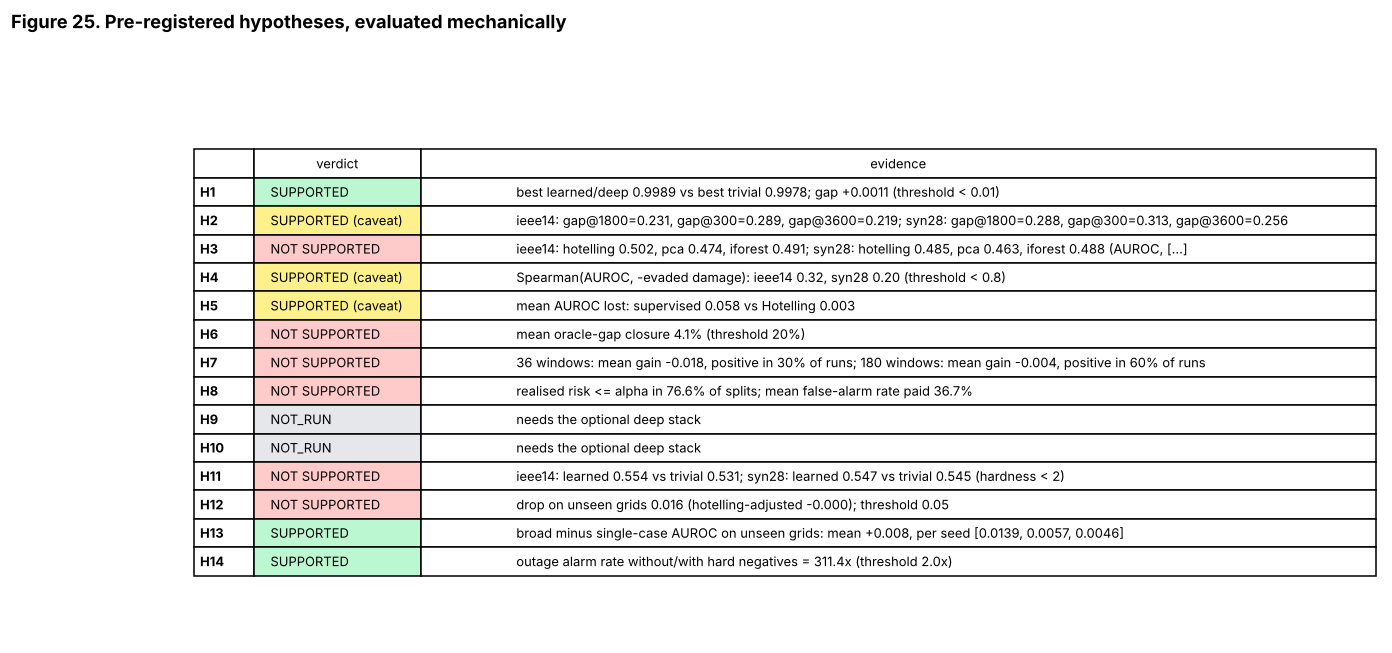

{'NOT SUPPORTED': 6, 'SUPPORTED': 3, 'SUPPORTED (caveat)': 3, 'NOT_RUN': 2}


In [46]:
def verdict(ok, caveat=None):
    if ok is None: return "NOT_RUN"
    return ("SUPPORTED" + (" (caveat)" if caveat else "")) if ok else "NOT SUPPORTED"

score_rows = []
def add(h, ok, evidence, note="", caveat=False):
    score_rows.append(dict(hyp=h, verdict=verdict(ok, caveat), evidence=evidence, note=note or HYPOTHESES[h][:0]))

# H1: trivial vs deep on SCEPTRE
if HAS_SCEPTRE:
    tv = max(audit["sceptre"]["triv"].values()); rep = audit["sceptre"]["reported"]
    dv = max(max(audit["sceptre"]["deep"].values()), max(rep.values()) if rep else 0)
    add("H1", (dv - tv) < THRESH["h1_gap"], f"best learned/deep {dv:.4f} vs best trivial {tv:.4f}; gap {dv-tv:+.4f} (threshold < {THRESH['h1_gap']})",
        "Applies to the SCEPTRE case14 split only. Says the task is shortcut-solvable, not that SCEPTRE's models are wrong.")
else:
    add("H1", None, "SCEPTRE reference data not found")

# H2: gap to oracle at hardness 1-4, shrinking with data
ok2 = all(h2[g]["gap_ref"] >= THRESH["h2_gap"] and h2[g]["gap_large"] < h2[g]["gap_small"] for g in STUDY_GRIDS)
add("H2", ok2, "; ".join(f"{g}: gap@{H2_BUDGET}={h2[g]['gap_ref']:.3f}, gap@{BUDGETS[0]}={h2[g]['gap_small']:.3f}, gap@{BUDGETS[-1]}={h2[g]['gap_large']:.3f}" for g in STUDY_GRIDS),
    "The oracle knows the true shift c; a deployed detector does not. Part of the gap is the price of not knowing the attack direction, so this measures headroom, not a claim that a better detector is feasible.", caveat=ok2)

# H3: Hotelling vs clean-only one-class detectors (hard-region AUROC, reference budget)
h3 = {}
for g in STUDY_GRIDS:
    r_ = {d_: region(INGRID[g][BUDGETS[0]][0][d_]["bins"], HARD_BINS) for d_ in ("hotelling", "pca_recon", "iforest")}
    h3[g] = r_
ok3 = all(h3[g]["hotelling"] >= max(h3[g]["pca_recon"], h3[g]["iforest"]) - THRESH["h3_tol"] for g in STUDY_GRIDS)
add("H3", ok3, "; ".join(f"{g}: hotelling {h3[g]['hotelling']:.3f}, pca {h3[g]['pca_recon']:.3f}, iforest {h3[g]['iforest']:.3f}" for g in STUDY_GRIDS) + " (AUROC, hardness 0.5-2)")

# H4: ranking disagreement
ok4 = all(abs(rho[g]) < THRESH["h4_rho"] for g in STUDY_GRIDS)
add("H4", ok4, "Spearman(AUROC, -evaded damage): " + ", ".join(f"{g} {rho[g]:.2f}" for g in STUDY_GRIDS) + f" (threshold < {THRESH['h4_rho']})",
    "Damage is measured on a linear LFC stand-in for the nonlinear plant of the earlier project.", caveat=ok4)

add("H5", H5["holds"], f"mean AUROC lost: supervised {H5['loss_supervised']:.3f} vs Hotelling {H5['loss_hotelling']:.3f}",
    "Weak adaptive attacker (best of K random directions). Summary-feature detectors lose little; raw-state detectors lose most.", caveat=H5["holds"])
add("H6", H6_val >= THRESH["h6_closure"], f"mean oracle-gap closure {H6_val:.1%} (threshold {THRESH['h6_closure']:.0%})")
add("H7", all(H7[b]["mean_gain"] > 0 for b in H7), "; ".join(f"{b} windows: mean gain {H7[b]['mean_gain']:+.3f}, positive in {H7[b]['frac_pos']:.0%} of runs" for b in H7))
add("H8", H8["frac_splits_under"] >= THRESH["h8_cov"] and not H8["vacuous"], f"realised risk <= alpha in {H8['frac_splits_under']:.1%} of splits; mean false-alarm rate paid {H8['mean_fpr']:.1%}" + (" (VACUOUS: alarms on nearly everything)" if H8["vacuous"] else ""),
    "Restricted to tie-line-aimed attacks. The conformal guarantee is on expected loss, not per split.")
add("H9", None, "needs the optional deep stack"); add("H10", None, "needs the optional deep stack")
ok11 = all(audit[g]["gap"] > THRESH["h11_gap"] for g in STUDY_GRIDS) if all("gap" in audit[g] for g in STUDY_GRIDS) else all((max(audit[g]["learned"].values()) - max(audit[g]["triv"].values())) > THRESH["h11_gap"] for g in STUDY_GRIDS)
add("H11", ok11, "; ".join(f"{g}: learned {max(audit[g]['learned'].values()):.3f} vs trivial {max(audit[g]['triv'].values()):.3f}" for g in STUDY_GRIDS) + " (hardness < 2)")
add("H12", H1213["h12_drop"] >= THRESH["h12_drop"], f"drop on unseen grids {H1213['h12_drop']:.3f} (hotelling-adjusted {H1213['h12_drop_adj']:.3f}); threshold {THRESH['h12_drop']}")
add("H13", H1213["h13_mean_diff"] > 0 and H1213["h13_all_positive"], f"broad minus single-case AUROC on unseen grids: mean {H1213['h13_mean_diff']:+.3f}, per seed {H1213['h13_diffs']}")
add("H14", H14_ratio >= THRESH["h14_ratio"], f"outage alarm rate without/with hard negatives = {H14_ratio:.1f}x (threshold {THRESH['h14_ratio']}x)",
    "When the 'with' rate is near zero the ratio is bounded below by a floor of 0.001 and is only a lower bound.")
SC = pd.DataFrame(score_rows)
pd.set_option("display.max_colwidth", 140); print(SC[["hyp", "verdict", "evidence"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 6.6)); ax.axis("off")
colour = {"SUPPORTED": "#bbf7d0", "SUPPORTED (caveat)": "#fef08a", "NOT SUPPORTED": "#fecaca", "NOT_RUN": "#e5e7eb"}
tbl = ax.table(cellText=[[r.hyp, r.verdict, textwrap.shorten(r.evidence, 118)] for r in SC.itertuples()], colLabels=["", "verdict", "evidence"],
               cellLoc="left", colWidths=[0.05, 0.14, 0.8], loc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5); tbl.scale(1, 1.55)
for i, r in enumerate(SC.itertuples(), start=1): tbl[i, 1].set_facecolor(colour[r.verdict]); tbl[i, 0].set_text_props(weight="bold")
fig.suptitle("Figure 25. Pre-registered hypotheses, evaluated mechanically", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig25_scorecard")

counts = SC.verdict.value_counts().to_dict(); print(counts)

### 15.1 Export and run record

In [47]:
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return jsonable(o.tolist())
    if isinstance(o, pd.DataFrame): return jsonable(o.to_dict(orient="records"))
    return o
export = dict(budget=BUDGET, seed=GLOBAL_SEED, runtime_min=(time.time() - t_notebook_start) / 60, versions=dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__, pandapower=pp.__version__),
              scorecard=SC, h2=h2, h3=h3, h5=H5, h6=H6_val, h7=H7, h8=H8, h12_h13=H1213, h14_ratio=H14_ratio, spearman=rho, adaptive=ADV.groupby(["grid", "rho", "det"])[["ref", "adaptive", "loss"]].mean().reset_index(),
              method_A=A, method_B=B, method_E=CRC, figures=_fig_log)
with open(OUT / "results.json", "w") as fh: json.dump(jsonable(export), fh, indent=1)
SC.to_csv(OUT / "scorecard.csv", index=False)
print(f"wrote {OUT/'results.json'} and {OUT/'scorecard.csv'}; {len(_fig_log)} figures in {FIG}")
print(f"total runtime: {(time.time()-t_notebook_start)/60:.1f} min")

wrote /tmp/w2/proj/outputs/results.json and /tmp/w2/proj/outputs/scorecard.csv; 25 figures in /tmp/w2/proj/figures
total runtime: 9.4 min


## What this notebook does and does not establish

**What it supports (subject to the scorecard above).** A hardness-indexed oracle gives every detector a yardstick that does not depend on a particular dataset. Against that yardstick the learned detectors leave headroom, the clean-only Hotelling test is hard to beat in the hard region at moderate label budgets, and detector ranking by AUROC differs from ranking by prevented damage.

**What it does not establish.**

* Everything is simulated. No real utility data, no hardware-in-the-loop. Real clean residuals are likely non-Gaussian and non-stationary in ways this generator only approximates.
* The oracle used for the gap knows the realised shift $c$. A deployed detector does not, so the gap overstates what is achievable.
* The LFC plant is linear and two-area. The earlier project's plant has eight nonlinearities; damage numbers here are indicative of ranking, not of magnitude.
* H9 and H10 are not run. Methods A and B are standard ideas applied to this problem; the contribution claimed is the measurement framework, not a new architecture.
* Nothing here guarantees acceptance at any journal. Whether the results are publishable depends on the scorecard above after the full-budget run and on novelty relative to literature that has to be re-checked at submission time.